
# **Rossmann Retail Store Sales Forecasting**

## Exploratory Data Analysis (EDA)

### 1. Project Overview

Rossmann operates multiple retail stores, and daily sales can vary according to customer traffic, promotions, holidays, seasonality, store characteristics, and competition.

The purpose of this project is to explore historical store-level data, identify meaningful sales patterns, and generate business insights that can support the development of reliable sales forecasting models.

### 2. Business Objective

The main objective is to understand customer purchasing behavior and investigate the factors associated with daily sales across Rossmann stores.

This analysis will help answer questions such as:

- How are sales and customer visits distributed?
- How are promotions associated with sales and customer traffic?
- How do holidays, weekdays, weekends, and seasons relate to sales?
- How do store characteristics and competitor distance relate to sales?
- Which combinations of factors may help explain differences in store performance?

### 3. EDA Approach

The notebook follows a structured exploratory workflow:

1. Data verification, loading, and structural inspection.
2. Data-quality assessment, missing-value analysis, and outlier investigation.
3. **Univariate Analysis:** understanding individual variables and their distributions.
4. **Bivariate Analysis:** examining relationships between pairs of variables.
5. **Multivariate Analysis:** investigating interactions among three or more variables.
6. Business interpretation, limitations, and recommendations for forecasting.

### 4. Dataset Scope

The project uses the merged Rossmann training and test datasets prepared in the preceding data-merging and preprocessing notebook.

- **Training data:** contains historical sales information and associated store-level and date-level features.
- **Test data:** contains the records for which sales predictions are required; actual test sales are not provided.
- **Store information:** includes store characteristics and competition-related attributes incorporated during preprocessing.

The training dataset is the primary source for historical sales analysis. The test dataset is used where appropriate to compare feature distributions and verify consistency.

### 5. Analytical Principles

- Preserve the original data and create separate analysis copies when necessary.
- Investigate missing values and potential outliers before deciding how to handle them.
- Use methods appropriate to numerical, categorical, and time-dependent variables.
- Distinguish association from causation.
- Support major conclusions with actual tables, visualizations, and numerical results.
- Record important analysis steps using the project logger.

### 6. Expected Outcome

The final EDA notebook will provide a structured understanding of sales patterns, customer behavior, store differences, promotions, holidays, seasonality, and competition.

The findings will guide feature engineering, model development, evaluation, and the subsequent sales forecasting workflow.



## **Introduction and Data Preparation**


### Environment Setup: Import Libraries, Define Paths, and Configure Logging


This section imports the libraries required for data manipulation, statistical analysis, visualization, and project logging.

The project paths are configured to provide consistent access to the processed datasets and log files. Logging records important project activities and helps with debugging and reproducibility.

**Libraries used:**
- **Pandas and NumPy:** data manipulation and numerical operations.
- **Matplotlib and Seaborn:** statistical visualization.
- **Pathlib:** platform-independent path management.
- **Logging:** recording project activities and errors.

**Expected outcome:** a reproducible analysis environment with access to the project directories and a configured logger.


In [207]:

# ============================================================
# IMPORT LIBRARIES, PROJECT PATHS AND LOGGING
# ============================================================
# Purpose:
# 1. Import libraries for data analysis and visualization.
# 2. Configure project directories.
# 3. Set up logging for reproducibility and debugging.
# ============================================================

# Step 1: Import standard libraries.
import logging
from pathlib import Path
from datetime import datetime

# Step 2: Import data analysis libraries.
import numpy as np
import pandas as pd

# Step 3: Import visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Step 4: Configure visualization defaults.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 100

# Step 5: Identify the project root directory.
# This notebook is expected to be inside the "notebooks" folder.
PROJECT_ROOT = Path.cwd().parent

# Step 6: Define the project directories.
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RAW_DIR = DATA_DIR / "raw"
LOG_DIR = PROJECT_ROOT / "logs"

# Step 7: Create the log directory if it does not exist.
LOG_DIR.mkdir(parents=True, exist_ok=True)

# Step 8: Configure the project logger.
LOG_FILE = LOG_DIR / "project6.log"

logger = logging.getLogger("Project6_EDA")
logger.setLevel(logging.INFO)
logger.propagate = False

# Remove and close existing handlers to avoid duplicate log messages.
for handler in logger.handlers[:]:
    logger.removeHandler(handler)
    handler.close()

# Write logs to both a file and the notebook output.
file_handler = logging.FileHandler(
    LOG_FILE,
    encoding="utf-8"
)
file_handler.setLevel(logging.INFO)

console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)

# Use a consistent timestamp and log format.
log_formatter = logging.Formatter(
    "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
)

file_handler.setFormatter(log_formatter)
console_handler.setFormatter(log_formatter)

logger.addHandler(file_handler)
logger.addHandler(console_handler)

# Step 9: Record environment setup.
logger.info("EDA environment setup started.")
logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Processed data directory: %s", PROCESSED_DIR)
logger.info("Log file: %s", LOG_FILE)

# Step 10: Display the configured paths.
print("=" * 65)
print("PROJECT ENVIRONMENT CONFIGURATION")
print("=" * 65)

print(f"Project Root     : {PROJECT_ROOT}")
print(f"Raw Data Folder  : {RAW_DIR}")
print(f"Processed Folder : {PROCESSED_DIR}")
print(f"Log Folder       : {LOG_DIR}")
print(f"Log File         : {LOG_FILE}")

# Step 11: Verify the important directories.
print("\nDIRECTORY CHECK")
print("-" * 65)

print(f"Project root exists     : {PROJECT_ROOT.exists()}")
print(f"Processed folder exists : {PROCESSED_DIR.exists()}")
print(f"Log folder exists       : {LOG_DIR.exists()}")

logger.info("EDA environment configuration completed.")


2026-10-31 09:23:05,462 | INFO | Project6_EDA | EDA environment setup started.
2026-10-31 09:23:05,464 | INFO | Project6_EDA | Project root: d:\Project_6_Rossmann_Forecasting
2026-10-31 09:23:05,465 | INFO | Project6_EDA | Processed data directory: d:\Project_6_Rossmann_Forecasting\data\processed
2026-10-31 09:23:05,466 | INFO | Project6_EDA | Log file: d:\Project_6_Rossmann_Forecasting\logs\project6.log
2026-10-31 09:23:05,469 | INFO | Project6_EDA | EDA environment configuration completed.


PROJECT ENVIRONMENT CONFIGURATION
Project Root     : d:\Project_6_Rossmann_Forecasting
Raw Data Folder  : d:\Project_6_Rossmann_Forecasting\data\raw
Processed Folder : d:\Project_6_Rossmann_Forecasting\data\processed
Log Folder       : d:\Project_6_Rossmann_Forecasting\logs
Log File         : d:\Project_6_Rossmann_Forecasting\logs\project6.log

DIRECTORY CHECK
-----------------------------------------------------------------
Project root exists     : True
Processed folder exists : True
Log folder exists       : True


### 3. **Verification of Processed Dataset Files**

Before loading the datasets, we verify that the required processed training and test CSV files are available in the expected project directory.

This step helps identify missing files, incorrect file paths, and incomplete data exports before beginning the exploratory data analysis.

**Validation checks:**

1. Confirm that the processed data directory exists.
2. Identify the available CSV files in the processed folder.
3. Verify that the required training and test datasets exist.
4. Check that both files have a non-zero file size.
5. Display a verification report containing file names, availability, and file sizes.

**Expected outcome:** Both merged datasets, `train_merged.csv` and `test_merged.csv`, should be available and non-empty before loading them into Pandas DataFrames.

In [208]:

# ============================================================
# VERIFY PROCESSED DATASET FILES
# ============================================================
# Purpose:
# 1. Confirm that the processed data folder exists.
# 2. Display available CSV files.
# 3. Verify the required training and test datasets.
# ============================================================

# Step 1: Check that PROCESSED_DIR was defined in Cell 3.
if "PROCESSED_DIR" not in globals():
    raise NameError(
        "PROCESSED_DIR is not defined. Run Cell 3 first."
    )

# Step 2: Check the processed data directory.
print("Processed data directory:")
print(PROCESSED_DIR.resolve())

if not PROCESSED_DIR.exists():
    raise FileNotFoundError(
        f"Processed data directory does not exist: {PROCESSED_DIR}\n"
        "Please check the project path in Cell 3."
    )

# Step 3: List all available CSV files.
available_csv_files = sorted(
    PROCESSED_DIR.glob("*.csv")
)

print("\nCSV files found:")
if available_csv_files:
    for file_path in available_csv_files:
        print(
            f"- {file_path.name} "
            f"({file_path.stat().st_size / (1024 ** 2):.2f} MB)"
        )
else:
    print("No CSV files found.")

# Step 4: Define the required files.
# These names must match the actual files in the folder.
required_files = {
    "train": PROCESSED_DIR / "train_merged.csv",
    "test": PROCESSED_DIR / "test_merged.csv"
}

# Step 5: Build a verification report.
verification_results = []

for dataset_name, file_path in required_files.items():
    file_exists = file_path.is_file()

    file_size = (
        file_path.stat().st_size
        if file_exists
        else 0
    )

    verification_results.append({
        "Dataset": dataset_name,
        "File_Name": file_path.name,
        "Exists": file_exists,
        "Size_MB": round(file_size / (1024 ** 2), 2),
        "Non_Empty": file_exists and file_size > 0
    })

file_check_df = pd.DataFrame(verification_results)

print("\n" + "=" * 65)
print("REQUIRED DATASET VERIFICATION")
print("=" * 65)

display(file_check_df)

# Step 6: Stop if a required dataset is missing or empty.
invalid_files = file_check_df.loc[
    ~file_check_df["Exists"] | ~file_check_df["Non_Empty"],
    "File_Name"
].tolist()

if invalid_files:
    raise FileNotFoundError(
        "Required dataset file(s) missing or empty: "
        + ", ".join(invalid_files)
        + ". Compare the expected names with the CSV files listed above."
    )

# Step 7: Log successful verification if the logger exists.
if "logger" in globals():
    logger.info(
        "Training and test CSV files verified successfully."
    )

print("\nTraining and test datasets verified successfully.")


Processed data directory:
D:\Project_6_Rossmann_Forecasting\data\processed

CSV files found:
- test_merged.csv (2.94 MB)
- train_merged.csv (71.89 MB)

REQUIRED DATASET VERIFICATION


,Dataset,File_Name,Exists,Size_MB,Non_Empty
0,train,train_merged.csv,True,71.89,True
1,test,test_merged.csv,True,2.94,True


2026-10-31 09:23:05,503 | INFO | Project6_EDA | Training and test CSV files verified successfully.



Training and test datasets verified successfully.



### 4. **Loading the Merged Datasets**

In this section, the verified training and test CSV files are loaded into Pandas DataFrames.

The training dataset contains historical sales and customer information used for exploratory analysis. The test dataset contains records for which actual sales values are not provided.

After loading, we will verify the dataset dimensions, column names, and a small sample of records to ensure the files were read correctly.

**Expected outcome:** both datasets are loaded successfully and are ready for structural inspection.


In [209]:
# ============================================================
# LOAD AND VALIDATE THE MERGED TRAINING AND TEST DATASETS
# ============================================================
# Purpose:
# 1. Load the verified CSV files.
# 2. Check whether the datasets contain the required columns.
# 3. Verify that the datasets are not empty.
# 4. Display dimensions, column names, and sample records.
# 5. Record the results in the project log.
# ============================================================

# Step 1: Define the dataset file paths.
TRAIN_FILE = PROCESSED_DIR / "train_merged.csv"
TEST_FILE = PROCESSED_DIR / "test_merged.csv"

# Step 2: Check whether both dataset files exist.
for file_path in [TRAIN_FILE, TEST_FILE]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required dataset file not found: {file_path}"
        )

# Step 3: Load the CSV files into Pandas DataFrames.
train_df = pd.read_csv(TRAIN_FILE, low_memory=False)
test_df = pd.read_csv(TEST_FILE, low_memory=False)

# Step 4: Check whether the datasets contain records.
if train_df.empty:
    raise ValueError("Training dataset is empty.")

if test_df.empty:
    raise ValueError("Test dataset is empty.")

# Step 5: Define the essential columns for each dataset.
required_train_columns = [
    "Store",
    "DayOfWeek",
    "Date",
    "Sales",
    "Customers",
    "Open",
    "Promo"
]

required_test_columns = [
    "Id",
    "Store",
    "DayOfWeek",
    "Date",
    "Open",
    "Promo"
]

# Step 6: Validate the required columns.
missing_train_columns = [
    column for column in required_train_columns
    if column not in train_df.columns
]

missing_test_columns = [
    column for column in required_test_columns
    if column not in test_df.columns
]

if missing_train_columns:
    raise ValueError(
        f"Missing columns in training dataset: {missing_train_columns}"
    )

if missing_test_columns:
    raise ValueError(
        f"Missing columns in test dataset: {missing_test_columns}"
    )

# Step 7: Display dataset dimensions.
print("=" * 75)
print("DATASET DIMENSIONS")
print("=" * 75)

print(f"Training dataset: {train_df.shape}")
print(f"Test dataset    : {test_df.shape}")

# Step 8: Display column names.
print("\nTRAINING DATASET COLUMNS")
print("-" * 75)
print(train_df.columns.tolist())

print("\nTEST DATASET COLUMNS")
print("-" * 75)
print(test_df.columns.tolist())

# Step 9: Display the first five records.
print("\nFIRST FIVE TRAINING RECORDS")
display(train_df.head())

print("\nFIRST FIVE TEST RECORDS")
display(test_df.head())

# Step 10: Record successful loading and validation.
logger.info(
    "Training dataset loaded and validated: %d rows, %d columns",
    train_df.shape[0],
    train_df.shape[1]
)

logger.info(
    "Test dataset loaded and validated: %d rows, %d columns",
    test_df.shape[0],
    test_df.shape[1]
)

print("\nSUCCESS: Both datasets loaded and validated successfully.")

DATASET DIMENSIONS
Training dataset: (1017209, 19)
Test dataset    : (41088, 18)

TRAINING DATASET COLUMNS
---------------------------------------------------------------------------
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_missing']

TEST DATASET COLUMNS
---------------------------------------------------------------------------
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_missing']

FIRST FIVE TRAINING RECORDS


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistance_missing
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN,0



FIRST FIVE TEST RECORDS


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistance_missing
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,0
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN,0
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN,0
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN,0


2026-10-31 09:23:06,307 | INFO | Project6_EDA | Training dataset loaded and validated: 1017209 rows, 19 columns
2026-10-31 09:23:06,309 | INFO | Project6_EDA | Test dataset loaded and validated: 41088 rows, 18 columns



SUCCESS: Both datasets loaded and validated successfully.


### 5. **Understanding Dataset Structure and Data Types**

This section examines the structure of the merged training and test datasets. The analysis includes dataset dimensions, column names, data types, numerical and categorical variables, and memory usage.

The purpose is to understand how the data is organized and identify any data-type issues that may affect subsequent exploratory data analysis.

The following checks will be performed:

1. Inspect the structure of both datasets.
2. Review the data types of all columns.
3. Identify numerical, categorical, and date-related variables.
4. Check whether the `Date` column can be converted to a datetime data type.
5. Review dataset memory usage.

The results will guide the subsequent missing-value analysis, outlier investigation, and temporal analysis.

In [210]:
# ============================================================
# UNDERSTANDING DATASET STRUCTURE AND DATA TYPES
# ============================================================
# Purpose:
# 1. Inspect the structure of both datasets.
# 2. Review column data types and missing values.
# 3. Classify variables according to their actual meaning.
# 4. Validate and convert Date columns.
# 5. Check dataset memory usage.
# ============================================================

# STEP 1: Verify that both datasets are available.
for name in ["train_df", "test_df"]:
    if name not in globals():
        raise NameError(
            f"{name} is not available. Run Cell 7 first."
        )

# STEP 2: Convert Date columns into datetime format.
# Invalid date values will become NaT and will be counted.

date_conversion_results = {}

for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    if "Date" not in dataframe.columns:
        raise ValueError(
            f"Date column is missing in {dataset_name} dataset."
        )

    dataframe["Date"] = pd.to_datetime(
        dataframe["Date"],
        errors="coerce"
    )

    invalid_dates = int(dataframe["Date"].isna().sum())

    date_conversion_results[dataset_name] = invalid_dates

# STEP 3: Display dataset dimensions.

print("=" * 75)
print("DATASET STRUCTURE")
print("=" * 75)

print(f"Training rows    : {train_df.shape[0]:,}")
print(f"Training columns : {train_df.shape[1]:,}")
print(f"Test rows        : {test_df.shape[0]:,}")
print(f"Test columns     : {test_df.shape[1]:,}")

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

# STEP 4: Display detailed dataset information.

print("\n" + "=" * 75)
print("TRAINING DATASET INFORMATION")
print("=" * 75)

train_df.info()

print("\n" + "=" * 75)
print("TEST DATASET INFORMATION")
print("=" * 75)

test_df.info()

# STEP 5: Create a data-type and missing-value summary.

def create_dtype_summary(dataframe, dataset_name):

    summary = pd.DataFrame({
        "Column": dataframe.columns,
        "Data_Type": dataframe.dtypes.astype(str).values,
        "Non_Null_Count": dataframe.notna().sum().values,
        "Missing_Count": dataframe.isna().sum().values,
        "Unique_Values": dataframe.nunique(
            dropna=True
        ).values
    })

    summary.insert(0, "Dataset", dataset_name)

    return summary


train_dtype_summary = create_dtype_summary(
    train_df, "Training"
)

test_dtype_summary = create_dtype_summary(
    test_df, "Test"
)

dtype_summary = pd.concat(
    [train_dtype_summary, test_dtype_summary],
    ignore_index=True
)

print("\n" + "=" * 75)
print("COLUMN DATA-TYPE SUMMARY")
print("=" * 75)

display(dtype_summary)

# STEP 6: Classify variables by their actual meaning.
# This is a semantic classification, not just a dtype check.

identifier_columns = ["Id", "Store"]

categorical_columns = [
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "StoreType",
    "Assortment",
    "Promo2",
    "PromoInterval"
]

numerical_measure_columns = [
    "Sales",
    "Customers",
    "CompetitionDistance"
]

numerical_metadata_columns = [
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2SinceWeek",
    "Promo2SinceYear"
]

indicator_columns = [
    "CompetitionDistance_missing"
]

def classify_variables(dataframe):

    available_columns = set(dataframe.columns)

    classification = {
        "Identifier columns": [
            c for c in identifier_columns
            if c in available_columns
        ],
        "Categorical / binary columns": [
            c for c in categorical_columns
            if c in available_columns
        ],
        "Numerical measurement columns": [
            c for c in numerical_measure_columns
            if c in available_columns
        ],
        "Numerical date metadata columns": [
            c for c in numerical_metadata_columns
            if c in available_columns
        ],
        "Missing-value indicator columns": [
            c for c in indicator_columns
            if c in available_columns
        ],
        "Date columns": [
            c for c in ["Date"]
            if c in available_columns
        ]
    }

    return classification


train_classification = classify_variables(train_df)
test_classification = classify_variables(test_df)

print("\n" + "=" * 75)
print("SEMANTIC VARIABLE CLASSIFICATION")
print("=" * 75)

for category, columns in train_classification.items():
    print(f"\nTraining - {category}:")
    print(columns)

for category, columns in test_classification.items():
    print(f"\nTest - {category}:")
    print(columns)

# STEP 7: Display date validation results.

print("\n" + "=" * 75)
print("DATE COLUMN VALIDATION")
print("=" * 75)

for dataset_name, invalid_count in date_conversion_results.items():
    print(
        f"{dataset_name} invalid/unparseable dates: "
        f"{invalid_count:,}"
    )

# STEP 8: Calculate memory usage.

train_memory_mb = (
    train_df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

test_memory_mb = (
    test_df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Rows": [train_df.shape[0], test_df.shape[0]],
    "Columns": [train_df.shape[1], test_df.shape[1]],
    "Memory_Usage_MB": [
        round(train_memory_mb, 2),
        round(test_memory_mb, 2)
    ]
})

print("\n" + "=" * 75)
print("DATASET MEMORY USAGE")
print("=" * 75)

display(memory_summary)

# STEP 9: Record the results in the project log.

logger.info(
    "Dataset structure analysis completed. "
    "Training shape: %s; Test shape: %s",
    train_df.shape,
    test_df.shape
)

logger.info(
    "Date validation completed. "
    "Training invalid dates: %d; Test invalid dates: %d",
    date_conversion_results["Training"],
    date_conversion_results["Test"]
)

print("\nSection 5 completed successfully.")

DATASET STRUCTURE
Training rows    : 1,017,209
Training columns : 19
Test rows        : 41,088
Test columns     : 18

Training columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_missing']

Test columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_missing']

TRAINING DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 19 columns):
 #   Column                       Non-Null Count    Dtype         
---  ------                       --------------    --

,Dataset,Column,Data_Type,Non_Null_Count,Missing_Count,Unique_Values
0,Training,Store,int64,1017209,0,1115
1,Training,DayOfWeek,int64,1017209,0,7
2,Training,Date,datetime64[us],1017209,0,942
3,Training,Sales,int64,1017209,0,21734
4,Training,Customers,int64,1017209,0,4086
5,Training,Open,int64,1017209,0,2
6,Training,Promo,int64,1017209,0,2
7,Training,StateHoliday,str,1017209,0,4
8,Training,SchoolHoliday,int64,1017209,0,2
9,Training,StoreType,str,1017209,0,4



SEMANTIC VARIABLE CLASSIFICATION

Training - Identifier columns:
['Store']

Training - Categorical / binary columns:
['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'Promo2', 'PromoInterval']

Training - Numerical measurement columns:
['Sales', 'Customers', 'CompetitionDistance']

Training - Numerical date metadata columns:
['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']

Training - Missing-value indicator columns:
['CompetitionDistance_missing']

Training - Date columns:
['Date']

Test - Identifier columns:
['Id', 'Store']

Test - Categorical / binary columns:
['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'Promo2', 'PromoInterval']

Test - Numerical measurement columns:
['CompetitionDistance']

Test - Numerical date metadata columns:
['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']

Test - Missing-value 

,Dataset,Rows,Columns,Memory_Usage_MB
0,Training,1017209,19,308.60
1,Test,41088,18,12.25


2026-10-31 09:23:07,518 | INFO | Project6_EDA | Dataset structure analysis completed. Training shape: (1017209, 19); Test shape: (41088, 18)
2026-10-31 09:23:07,519 | INFO | Project6_EDA | Date validation completed. Training invalid dates: 0; Test invalid dates: 0



Section 5 completed successfully.


### 6. **Date Range and Temporal Coverage**

This section examines the temporal coverage of the merged training and test datasets. Understanding the date range is essential because retail sales are influenced by weekly patterns, holidays, seasonal changes, and promotional schedules.

The analysis will:

1. Identify the earliest and latest dates in the training and test datasets.
2. Count the unique dates covered by each dataset.
3. Check whether the training and test periods overlap.
4. Identify missing calendar dates within each dataset's date range.
5. Compare the observed dates with the expected chronological sequence.
6. Validate the `DayOfWeek` column against the actual calendar dates.

The results will help establish whether the datasets provide consistent temporal coverage for subsequent time-based exploratory analysis.

The training dataset contains the historical sales target, whereas the test dataset represents a later forecasting period. Therefore, the two datasets should be analyzed separately before their chronological relationship is assessed.

In [211]:

# ============================================================
# DATE RANGE AND TEMPORAL COVERAGE
# ============================================================
# Objectives:
# 1. Identify the date range of training and test datasets.
# 2. Count unique dates in both datasets.
# 3. Identify missing calendar dates.
# 4. Check the chronological relationship between datasets.
# 5. Validate DayOfWeek against the actual calendar dates.
# 6. Record findings in the project log.
# ============================================================

# STEP 1: Verify required datasets and columns
for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    required_columns = ["Date", "DayOfWeek"]

    missing_columns = [
        column for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{dataset_name} dataset is missing columns: "
            f"{missing_columns}"
        )

    if not pd.api.types.is_datetime64_any_dtype(
        dataframe["Date"]
    ):
        raise TypeError(
            f"{dataset_name} Date column must be datetime. "
            "Run Section 5 first."
        )

# STEP 2: Create a function for temporal coverage
def temporal_coverage_summary(dataframe, dataset_name):

    valid_dates = dataframe["Date"].dropna()

    if valid_dates.empty:
        raise ValueError(
            f"{dataset_name} dataset contains no valid dates."
        )

    start_date = valid_dates.min()
    end_date = valid_dates.max()

    unique_dates = valid_dates.nunique()

    # Generate every calendar date within the observed range
    expected_dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="D"
    )

    # Get dates actually present in the dataset
    observed_dates = pd.DatetimeIndex(
        valid_dates.drop_duplicates()
    )

    # Find calendar dates that are absent
    missing_dates = expected_dates.difference(
        observed_dates
    )

    summary = {
        "Dataset": dataset_name,
        "Total_Records": len(dataframe),
        "Valid_Date_Records": len(valid_dates),
        "Missing_Date_Values": int(
            dataframe["Date"].isna().sum()
        ),
        "Start_Date": start_date.date(),
        "End_Date": end_date.date(),
        "Unique_Dates": unique_dates,
        "Expected_Calendar_Days": len(expected_dates),
        "Missing_Calendar_Days": len(missing_dates)
    }

    return summary, missing_dates


# STEP 3: Calculate temporal coverage summaries
train_temporal_summary, train_missing_dates = (
    temporal_coverage_summary(
        train_df, "Training"
    )
)

test_temporal_summary, test_missing_dates = (
    temporal_coverage_summary(
        test_df, "Test"
    )
)

temporal_summary_df = pd.DataFrame([
    train_temporal_summary,
    test_temporal_summary
])

print("=" * 80)
print("TEMPORAL COVERAGE SUMMARY")
print("=" * 80)

display(temporal_summary_df)


# STEP 4: Display missing calendar dates
print("\n" + "=" * 80)
print("MISSING CALENDAR DATES")
print("=" * 80)

if len(train_missing_dates) == 0:
    print(
        "Training: No missing calendar dates "
        "within the observed date range."
    )
else:
    print("Training missing dates:")
    print(
        train_missing_dates.strftime(
            "%Y-%m-%d"
        ).tolist()
    )

if len(test_missing_dates) == 0:
    print(
        "Test: No missing calendar dates "
        "within the observed date range."
    )
else:
    print("Test missing dates:")
    print(
        test_missing_dates.strftime(
            "%Y-%m-%d"
        ).tolist()
    )


# STEP 5: Check the chronological relationship
train_start = train_df["Date"].min()
train_end = train_df["Date"].max()

test_start = test_df["Date"].min()
test_end = test_df["Date"].max()

ranges_overlap = (
    train_start <= test_end
    and test_start <= train_end
)

print("\n" + "=" * 80)
print("TRAINING-TEST CHRONOLOGICAL RELATIONSHIP")
print("=" * 80)

print(
    f"Training period: {train_start.date()} "
    f"to {train_end.date()}"
)

print(
    f"Test period: {test_start.date()} "
    f"to {test_end.date()}"
)

print(f"Date ranges overlap: {ranges_overlap}")

if train_end < test_start:
    gap_days = (test_start - train_end).days - 1

    print(
        "The test period starts after the training period."
    )
    print(
        f"Calendar days between the periods: {gap_days}"
    )

elif test_end < train_start:
    gap_days = (train_start - test_end).days - 1

    print(
        "The test period ends before the training period."
    )
    print(
        f"Calendar days between the periods: {gap_days}"
    )

else:
    print(
        "The training and test date ranges overlap."
    )


# STEP 6: Validate DayOfWeek using actual calendar dates
# Pandas: Monday = 0, Tuesday = 1, ..., Sunday = 6.
# Rossmann dataset convention: Monday = 1, ..., Sunday = 7.
# Therefore, add 1 to the Pandas weekday value.

def check_day_of_week(dataframe, dataset_name):

    valid_rows = dataframe.dropna(
        subset=["Date", "DayOfWeek"]
    )

    # CORRECTED: Use day_of_week instead of dayofweek
    actual_day_of_week = (
        valid_rows["Date"].dt.day_of_week + 1
    )

    # Convert values to numeric for a reliable comparison
    recorded_day_of_week = pd.to_numeric(
        valid_rows["DayOfWeek"],
        errors="coerce"
    )

    mismatches = (
        recorded_day_of_week != actual_day_of_week
    )

    mismatch_count = int(mismatches.sum())

    print(
        f"{dataset_name} DayOfWeek mismatches: "
        f"{mismatch_count:,} out of "
        f"{len(valid_rows):,} valid records"
    )

    if mismatch_count > 0:
        print(
            f"\nExamples of {dataset_name} mismatches:"
        )

        mismatch_examples = valid_rows.loc[
            mismatches,
            ["Date", "DayOfWeek"]
        ].head(10).copy()

        mismatch_examples["Actual_DayOfWeek"] = (
            actual_day_of_week.loc[
                mismatch_examples.index
            ]
        )

        display(mismatch_examples)

    return mismatch_count


print("\n" + "=" * 80)
print("DAY-OF-WEEK VALIDATION")
print("=" * 80)

train_dow_mismatches = check_day_of_week(
    train_df, "Training"
)

test_dow_mismatches = check_day_of_week(
    test_df, "Test"
)


# STEP 7: Log results
logger.info(
    "Section 6 completed. Training period: %s to %s; "
    "Test period: %s to %s; overlap: %s",
    train_start.date(),
    train_end.date(),
    test_start.date(),
    test_end.date(),
    ranges_overlap
)

logger.info(
    "Missing calendar dates: Training=%d, Test=%d. "
    "DayOfWeek mismatches: Training=%d, Test=%d",
    len(train_missing_dates),
    len(test_missing_dates),
    train_dow_mismatches,
    test_dow_mismatches
)

print("\nSection 6 completed successfully.")


TEMPORAL COVERAGE SUMMARY


,Dataset,Total_Records,Valid_Date_Records,Missing_Date_Values,Start_Date,End_Date,Unique_Dates,Expected_Calendar_Days,Missing_Calendar_Days
0,Training,1017209,1017209,0,2013-01-01,2015-07-31,942,942,0
1,Test,41088,41088,0,2015-08-01,2015-09-17,48,48,0


2026-10-31 09:23:07,624 | INFO | Project6_EDA | Section 6 completed. Training period: 2013-01-01 to 2015-07-31; Test period: 2015-08-01 to 2015-09-17; overlap: False
2026-10-31 09:23:07,626 | INFO | Project6_EDA | Missing calendar dates: Training=0, Test=0. DayOfWeek mismatches: Training=0, Test=0



MISSING CALENDAR DATES
Training: No missing calendar dates within the observed date range.
Test: No missing calendar dates within the observed date range.

TRAINING-TEST CHRONOLOGICAL RELATIONSHIP
Training period: 2013-01-01 to 2015-07-31
Test period: 2015-08-01 to 2015-09-17
Date ranges overlap: False
The test period starts after the training period.
Calendar days between the periods: 0

DAY-OF-WEEK VALIDATION
Training DayOfWeek mismatches: 0 out of 1,017,209 valid records
Test DayOfWeek mismatches: 0 out of 41,088 valid records

Section 6 completed successfully.


### 7. **Missing-Value Analysis**

This section investigates missing values in the merged training and test datasets. Missing data must be understood before statistical analysis and forecasting because different types of missing values require different treatments.

The analysis will:

1. Count missing values and calculate their percentage for each column.
2. Compare missing-value patterns between the training and test datasets.
3. Investigate missing values in competition-related information.
4. Examine missing values in Promo2-related metadata and determine whether they are associated with stores that do not participate in Promo2.
5. Investigate missing values in the test dataset's `Open` column.
6. Distinguish structural or non-applicable missing values from potentially unexpected missing values.

Missing values will be reported rather than automatically filled or deleted. Any imputation or treatment decision will be made only after considering the meaning of the affected variable and its role in forecasting.

In [212]:

# ============================================================
# MISSING-VALUE ANALYSIS
# ============================================================
# Purpose:
# 1. Count missing values and calculate their percentages.
# 2. Compare missingness in training and test datasets.
# 3. Investigate competition-related missing values.
# 4. Investigate Promo2-related structural missingness.
# 5. Examine missing Open values in the test dataset.
# 6. Log the findings without automatically imputing values.
# ============================================================

# Step 1: Verify that the datasets are available.
if "train_df" not in globals() or "test_df" not in globals():
    raise NameError(
        "Training or test dataset is missing. "
        "Run the dataset-loading cells first."
    )

# Step 2: Create a missing-value summary.
def missing_value_summary(dataframe, dataset_name):
    missing_count = dataframe.isna().sum()
    missing_percentage = (
        missing_count / len(dataframe) * 100
    )

    summary = pd.DataFrame({
        "Dataset": dataset_name,
        "Column": dataframe.columns,
        "Missing_Count": missing_count.values,
        "Missing_Percentage": missing_percentage.values,
        "Data_Type": dataframe.dtypes.astype(str).values
    })

    # Keep columns with at least one missing value.
    summary = summary[
        summary["Missing_Count"] > 0
    ].sort_values(
        by="Missing_Count",
        ascending=False
    ).reset_index(drop=True)

    return summary


train_missing_summary = missing_value_summary(
    train_df, "Training"
)

test_missing_summary = missing_value_summary(
    test_df, "Test"
)

print("=" * 80)
print("MISSING VALUES: TRAINING DATASET")
print("=" * 80)

if train_missing_summary.empty:
    print("No missing values found in the training dataset.")
else:
    display(train_missing_summary)

print("\n" + "=" * 80)
print("MISSING VALUES: TEST DATASET")
print("=" * 80)

if test_missing_summary.empty:
    print("No missing values found in the test dataset.")
else:
    display(test_missing_summary)

# Step 3: Create a combined comparison table.
all_columns = sorted(
    set(train_df.columns).union(set(test_df.columns))
)

combined_missing_summary = pd.DataFrame({
    "Column": all_columns
})

combined_missing_summary["Training_Missing_Count"] = [
    int(train_df[column].isna().sum())
    if column in train_df.columns else np.nan
    for column in all_columns
]

combined_missing_summary["Training_Missing_Percentage"] = [
    round(train_df[column].isna().mean() * 100, 4)
    if column in train_df.columns else np.nan
    for column in all_columns
]

combined_missing_summary["Test_Missing_Count"] = [
    int(test_df[column].isna().sum())
    if column in test_df.columns else np.nan
    for column in all_columns
]

combined_missing_summary["Test_Missing_Percentage"] = [
    round(test_df[column].isna().mean() * 100, 4)
    if column in test_df.columns else np.nan
    for column in all_columns
]

combined_missing_summary = combined_missing_summary[
    (
        combined_missing_summary["Training_Missing_Count"].fillna(0) > 0
    ) |
    (
        combined_missing_summary["Test_Missing_Count"].fillna(0) > 0
    )
].reset_index(drop=True)

print("\n" + "=" * 80)
print("TRAINING VS TEST: MISSING-VALUE COMPARISON")
print("=" * 80)

if combined_missing_summary.empty:
    print("No missing values found in either dataset.")
else:
    display(combined_missing_summary)

# Step 4: Investigate missing competition information.
competition_columns = [
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear"
]

print("\n" + "=" * 80)
print("COMPETITION-RELATED MISSING VALUES")
print("=" * 80)

for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    available_columns = [
        column for column in competition_columns
        if column in dataframe.columns
    ]

    print(f"\n{dataset_name} dataset:")

    for column in available_columns:
        missing_rows = int(dataframe[column].isna().sum())
        missing_stores = (
            int(dataframe.loc[
                dataframe[column].isna(), "Store"
            ].nunique())
            if "Store" in dataframe.columns else None
        )

        print(
            f"{column}: {missing_rows:,} missing rows; "
            f"{missing_stores} affected stores"
        )

# Step 5: Investigate Promo2-related metadata.
promo2_metadata_columns = [
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "PromoInterval"
]

print("\n" + "=" * 80)
print("PROMO2 METADATA MISSINGNESS")
print("=" * 80)

for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    if "Promo2" not in dataframe.columns:
        continue

    print(f"\n{dataset_name} dataset:")

    promo2_inactive = dataframe["Promo2"].eq(0)
    promo2_active = dataframe["Promo2"].eq(1)

    print(
        "Records with Promo2 = 0:",
        f"{int(promo2_inactive.sum()):,}"
    )
    print(
        "Records with Promo2 = 1:",
        f"{int(promo2_active.sum()):,}"
    )

    for column in promo2_metadata_columns:
        if column not in dataframe.columns:
            continue

        missing = dataframe[column].isna()

        missing_inactive = int(
            (missing & promo2_inactive).sum()
        )
        missing_active = int(
            (missing & promo2_active).sum()
        )

        print(
            f"{column}: total missing={int(missing.sum()):,}; "
            f"missing when Promo2=0: {missing_inactive:,}; "
            f"missing when Promo2=1: {missing_active:,}"
        )

# Step 6: Investigate missing Open values in test data.
print("\n" + "=" * 80)
print("TEST DATASET: OPEN COLUMN")
print("=" * 80)

if "Open" in test_df.columns:
    open_missing_mask = test_df["Open"].isna()
    open_missing_count = int(open_missing_mask.sum())

    print(f"Missing Open values: {open_missing_count:,}")

    if open_missing_count > 0:
        affected_stores = (
            test_df.loc[open_missing_mask, "Store"]
            .value_counts()
            .rename_axis("Store")
            .reset_index(name="Missing_Open_Records")
        )

        print("Stores affected by missing Open values:")
        display(affected_stores)

                # Display the actual records with missing Open values.
        print("\nActual records with missing Open values:")

        open_missing_details = test_df.loc[
            open_missing_mask,
            [
                "Id",
                "Store",
                "Date",
                "DayOfWeek",
                "Promo",
                "StateHoliday",
                "SchoolHoliday"
            ]
        ].sort_values("Date")

        display(open_missing_details)

        print(
            "These records should be investigated before "
            "deciding how to handle the missing Open values."
        )
else:
    print("Open column is not available in the test dataset.")

# Step 7: Report overall missingness.
overall_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Total_Records": [len(train_df), len(test_df)],
    "Total_Missing_Cells": [
        int(train_df.isna().sum().sum()),
        int(test_df.isna().sum().sum())
    ],
    "Columns_With_Missing_Values": [
        int((train_df.isna().sum() > 0).sum()),
        int((test_df.isna().sum() > 0).sum())
    ]
})

print("\n" + "=" * 80)
print("OVERALL MISSING-VALUE SUMMARY")
print("=" * 80)

display(overall_summary)

# Step 8: Log results.
logger.info(
    "Section 7 completed. Training missing cells: %d; "
    "Test missing cells: %d",
    int(train_df.isna().sum().sum()),
    int(test_df.isna().sum().sum())
)

logger.info(
    "Columns containing missing values: Training=%d; Test=%d",
    int((train_df.isna().sum() > 0).sum()),
    int((test_df.isna().sum() > 0).sum())
)

print("\nSection 7 completed successfully.")
print(
    "Note: Missing values have been analyzed but not "
    "automatically imputed or removed."
)


MISSING VALUES: TRAINING DATASET


,Dataset,Column,Missing_Count,Missing_Percentage,Data_Type
0,Training,Promo2SinceYear,508031,49.943620,float64
1,Training,Promo2SinceWeek,508031,49.943620,float64
2,Training,PromoInterval,508031,49.943620,str
3,Training,CompetitionOpenSinceMonth,323348,31.787764,float64
4,Training,CompetitionOpenSinceYear,323348,31.787764,float64
5,Training,CompetitionDistance,2642,0.259730,float64



MISSING VALUES: TEST DATASET


,Dataset,Column,Missing_Count,Missing_Percentage,Data_Type
0,Test,PromoInterval,17232,41.939252,str
1,Test,Promo2SinceYear,17232,41.939252,float64
2,Test,Promo2SinceWeek,17232,41.939252,float64
3,Test,CompetitionOpenSinceMonth,15216,37.032710,float64
4,Test,CompetitionOpenSinceYear,15216,37.032710,float64
5,Test,CompetitionDistance,96,0.233645,float64
6,Test,Open,11,0.026772,float64



TRAINING VS TEST: MISSING-VALUE COMPARISON


,Column,Training_Missing_Count,Training_Missing_Percentage,Test_Missing_Count,Test_Missing_Percentage
0,CompetitionDistance,2642.0,0.2597,96.0,0.2336
1,CompetitionOpenSinceMonth,323348.0,31.7878,15216.0,37.0327
2,CompetitionOpenSinceYear,323348.0,31.7878,15216.0,37.0327
3,Open,0.0,0.0000,11.0,0.0268
4,Promo2SinceWeek,508031.0,49.9436,17232.0,41.9393
5,Promo2SinceYear,508031.0,49.9436,17232.0,41.9393
6,PromoInterval,508031.0,49.9436,17232.0,41.9393


... (4 outputs left out)

These records should be investigated before deciding how to handle the missing Open values.

OVERALL MISSING-VALUE SUMMARY


,Dataset,Total_Records,Total_Missing_Cells,Columns_With_Missing_Values
0,Training,1017209,2173431,6
1,Test,41088,82235,7


2026-10-31 09:23:08,379 | INFO | Project6_EDA | Section 7 completed. Training missing cells: 2173431; Test missing cells: 82235
2026-10-31 09:23:08,498 | INFO | Project6_EDA | Columns containing missing values: Training=6; Test=7



Section 7 completed successfully.
Note: Missing values have been analyzed but not automatically imputed or removed.


In [213]:

# ============================================================
# ADDITIONAL INVESTIGATION: MISSING OPEN VALUES
# ============================================================
# Purpose:
# 1. Investigate the 11 missing Open records in the test set.
# 2. Examine historical opening behavior of Store 622.
# 3. Compare opening patterns across weekdays.
# 4. Compare nearby historical dates where available.
# 5. Do not automatically impute missing Open values.
# ============================================================

# STEP 1: Identify records with missing Open values

missing_open_records = test_df.loc[
    test_df["Open"].isna()
].copy()

if missing_open_records.empty:

    print("No missing Open values found in the test dataset.")

else:

    print("=" * 85)
    print("INVESTIGATION OF MISSING OPEN VALUES")
    print("=" * 85)

    print(
        "Total missing Open records:",
        len(missing_open_records)
    )

    affected_stores = (
        missing_open_records["Store"].unique().tolist()
    )

    print("Affected stores:", affected_stores)

    # STEP 2: Prepare temporary date columns
    # Original datasets will not be modified.

    historical_data = train_df.copy()
    historical_data["Date"] = pd.to_datetime(
        historical_data["Date"],
        errors="coerce"
    )

    missing_open_records["Date"] = pd.to_datetime(
        missing_open_records["Date"],
        errors="coerce"
    )

    # STEP 3: Examine historical opening behavior
    for store_id in affected_stores:

        print("\n" + "-" * 85)
        print(f"HISTORICAL OPENING ANALYSIS: STORE {store_id}")
        print("-" * 85)

        store_history = historical_data.loc[
            historical_data["Store"] == store_id
        ].copy()

        if store_history.empty:

            print(
                "No historical training records found "
                "for this store."
            )
            continue

        # Overall historical opening distribution
        opening_distribution = (
            store_history["Open"]
            .value_counts(dropna=False)
            .rename_axis("Open_Status")
            .reset_index(name="Record_Count")
        )

        print("\nHistorical Open Distribution:")
        display(opening_distribution)

        # STEP 4: Opening rate by weekday
        weekday_summary = (
            store_history.groupby("DayOfWeek")["Open"]
            .agg(
                Total_Records="count",
                Open_Records=lambda x: (x == 1).sum(),
                Closed_Records=lambda x: (x == 0).sum(),
                Opening_Rate=lambda x: (x == 1).mean() * 100
            )
            .reset_index()
        )

        weekday_summary["Opening_Rate"] = (
            weekday_summary["Opening_Rate"].round(2)
        )

        print("\nHistorical Opening Pattern by Weekday:")
        display(weekday_summary)

        # STEP 5: Compare missing test dates with historical dates
        store_missing_dates = missing_open_records.loc[
            missing_open_records["Store"] == store_id
        ].copy()

        comparison_rows = []

        for _, missing_row in store_missing_dates.iterrows():

            target_date = missing_row["Date"]

            # Same weekday historical records
            same_weekday = store_history.loc[
                store_history["DayOfWeek"]
                == missing_row["DayOfWeek"]
            ]

            historical_open_rate = (
                same_weekday["Open"].mean() * 100
                if not same_weekday.empty
                else np.nan
            )

            # Nearest historical record before target date
            previous_records = store_history.loc[
                store_history["Date"] < target_date
            ].sort_values("Date", ascending=False)

            previous_open = (
                previous_records.iloc[0]["Open"]
                if not previous_records.empty
                else np.nan
            )

            comparison_rows.append({
                "Date": target_date,
                "DayOfWeek": missing_row["DayOfWeek"],
                "Historical_Weekday_Opening_Rate_%":
                    round(historical_open_rate, 2)
                    if pd.notna(historical_open_rate)
                    else np.nan,
                "Previous_Historical_Open_Status":
                    previous_open
            })

        comparison_df = pd.DataFrame(comparison_rows)

        print(
            "\nMissing Test Dates vs Historical Store Behavior:"
        )
        display(comparison_df)

        # STEP 6: Log the investigation
        logger.info(
            "Missing Open investigation completed for Store %s. "
            "Missing records=%d; Historical records=%d",
            store_id,
            len(store_missing_dates),
            len(store_history)
        )

    print("\n" + "=" * 85)
    print("MISSING OPEN INVESTIGATION COMPLETED")
    print("=" * 85)

    print(
        "Decision: Missing Open values remain unchanged. "
        "Historical patterns are diagnostic evidence only "
        "and are not used as automatic replacements."
    )


INVESTIGATION OF MISSING OPEN VALUES
Total missing Open records: 11
Affected stores: [622]

-------------------------------------------------------------------------------------
HISTORICAL OPENING ANALYSIS: STORE 622
-------------------------------------------------------------------------------------

Historical Open Distribution:


,Open_Status,Record_Count
0,1,784
1,0,158



Historical Opening Pattern by Weekday:


,DayOfWeek,Total_Records,Open_Records,Closed_Records,Opening_Rate
0,1,134,128,6,95.52
1,2,135,134,1,99.26
2,3,135,132,3,97.78
3,4,135,127,8,94.07
4,5,135,129,6,95.56
5,6,134,134,0,100.00
6,7,134,0,134,0.00



Missing Test Dates vs Historical Store Behavior:


,Date,DayOfWeek,Historical_Weekday_Opening_Rate_%,Previous_Historical_Open_Status
0,2015-09-17,4,94.07,1
1,2015-09-16,3,97.78,1
2,2015-09-15,2,99.26,1
3,2015-09-14,1,95.52,1
4,2015-09-12,6,100.00,1
5,2015-09-11,5,95.56,1
6,2015-09-10,4,94.07,1
7,2015-09-09,3,97.78,1
8,2015-09-08,2,99.26,1
9,2015-09-07,1,95.52,1


2026-10-31 09:23:08,645 | INFO | Project6_EDA | Missing Open investigation completed for Store 622. Missing records=11; Historical records=942



MISSING OPEN INVESTIGATION COMPLETED
Decision: Missing Open values remain unchanged. Historical patterns are diagnostic evidence only and are not used as automatic replacements.


### 8. **Numerical Outlier Investigation**

This section investigates potential outliers in important numerical variables in the training dataset. Outliers may represent unusually high sales, large customer traffic, or extreme competition distances. They may also indicate data-quality issues that require further investigation.

The analysis will:

1. Examine the distributions of `Sales`, `Customers`, and `CompetitionDistance`.
2. Calculate the first quartile (Q1), third quartile (Q3), interquartile range (IQR), and IQR-based outlier boundaries.
3. Estimate the number and percentage of observations outside these boundaries.
4. Investigate sales outliers separately for open stores to reduce the influence of records with zero sales because a store was closed.
5. Visualize numerical distributions using boxplots and histograms.

IQR-based outlier flags will be treated as indicators for investigation, not proof of incorrect data. No observations will be deleted or modified during this section.

NUMERICAL OUTLIER SUMMARY


,Variable,Valid_Observations,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Sales (Open Stores),844392,"4,859.00","8,360.00","3,501.00",-392.50,"13,611.50",30769,3.64%
1,Customers (Open Stores),844392,519.00,893.00,374.00,-42.00,"1,454.00",40853,4.84%
2,CompetitionDistance (Unique Stores),1112,717.50,"6,882.50","6,165.00","-8,530.00","16,130.00",108,9.71%


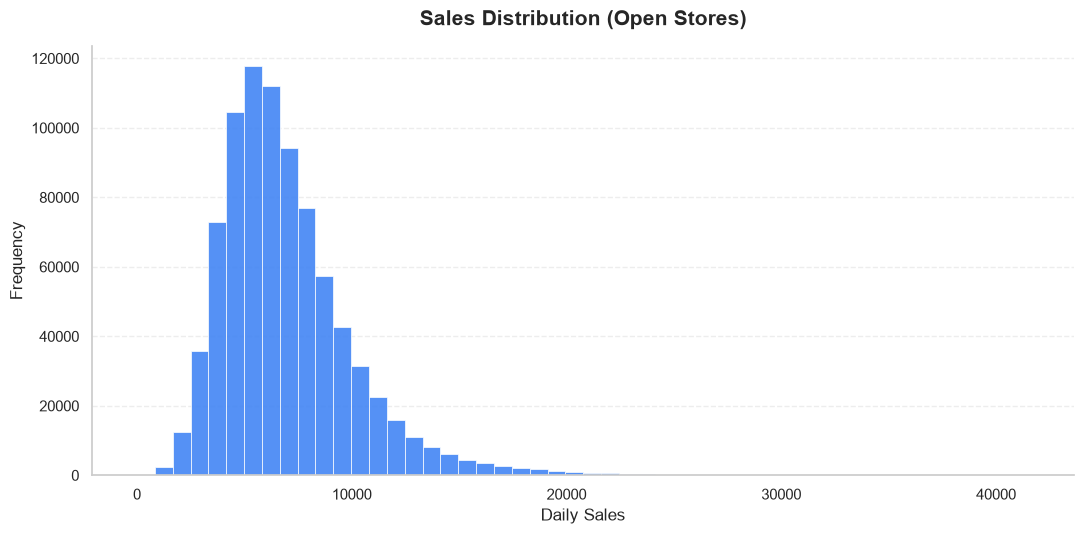

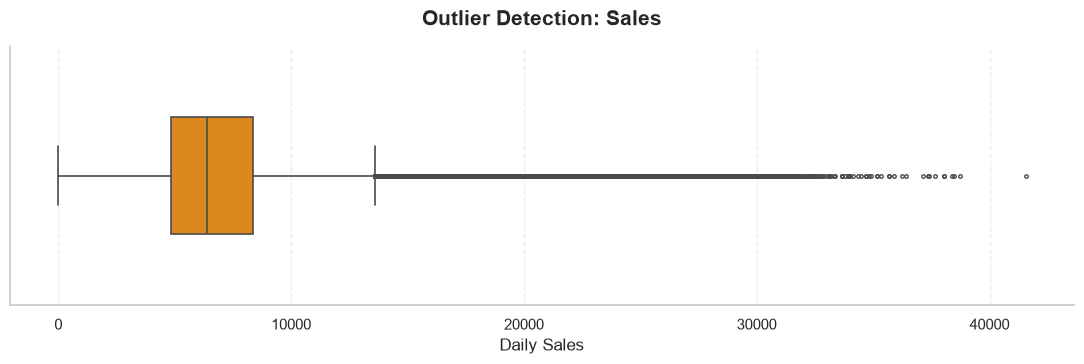

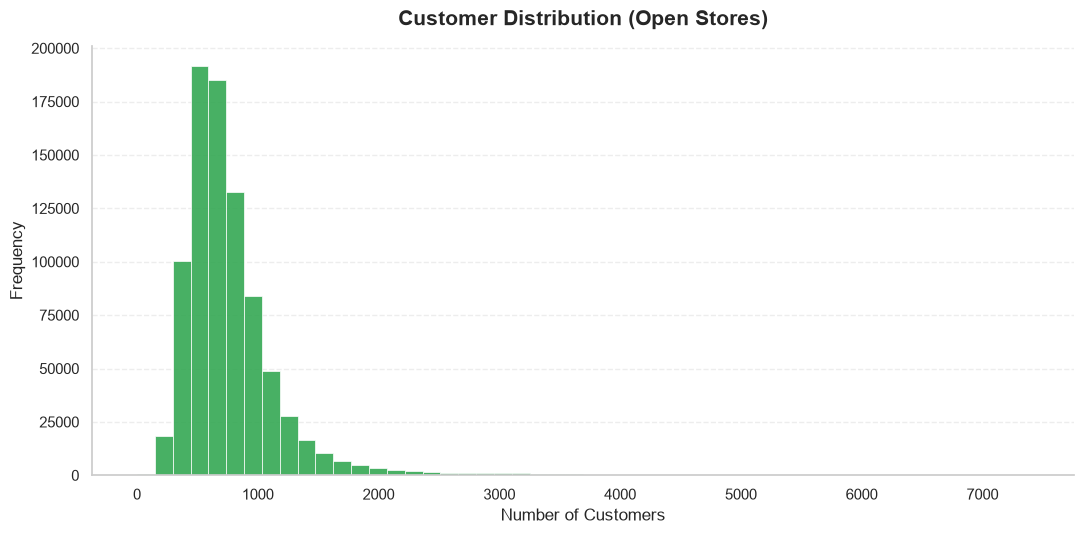

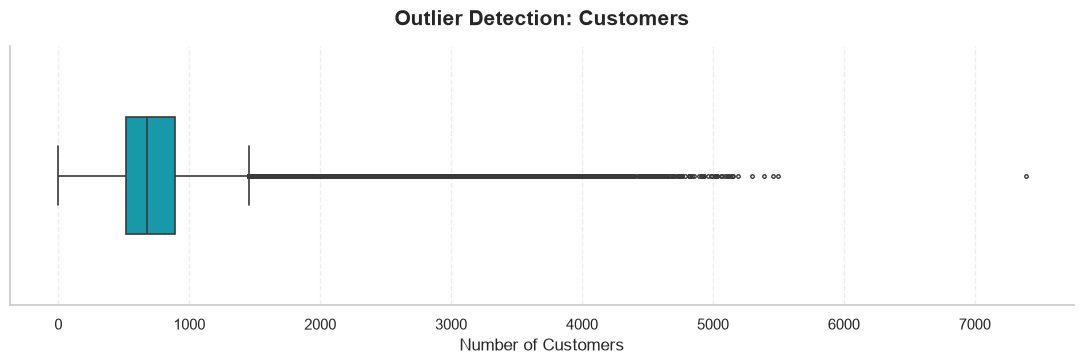

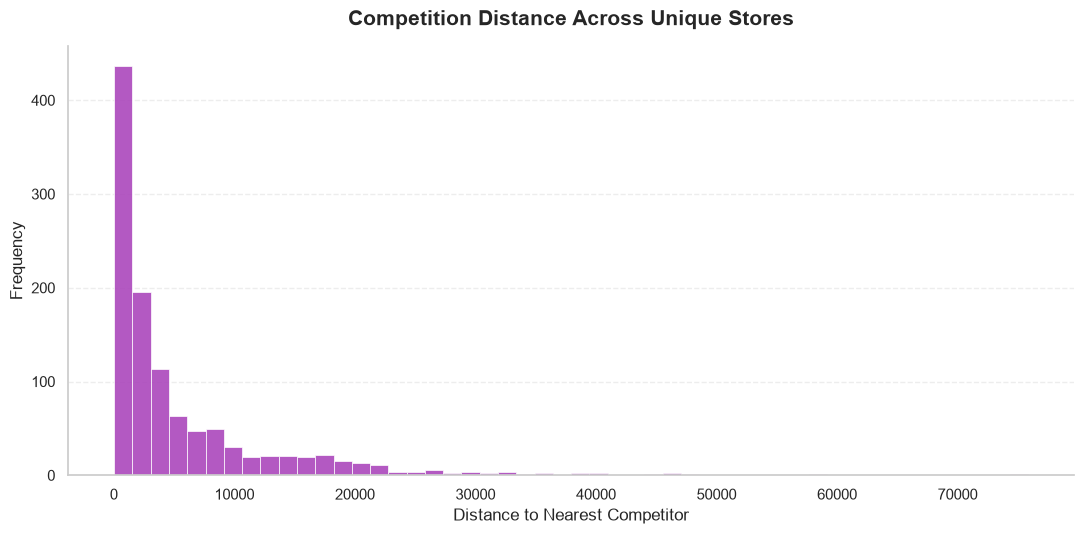

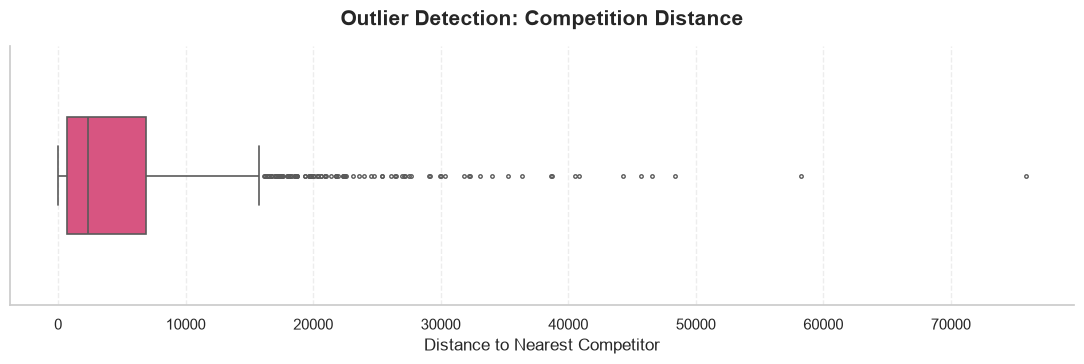

2026-10-31 09:23:11,593 | INFO | Project6_EDA | Section 8 completed. IQR outlier analysis performed for open-store sales, customers and unique-store competition distance where available.



Section 8 completed successfully.
Interpretation: IQR outliers are potential extreme observations, not automatically incorrect records.
No original rows or values were deleted or modified.


In [214]:

# ============================================================
# NUMERICAL OUTLIER INVESTIGATION
# Colorful and Professional Visualizations
# ============================================================
# Objectives:
# 1. Analyze Sales, Customers and CompetitionDistance.
# 2. Calculate IQR-based outlier boundaries.
# 3. Display colorful histograms and boxplots.
# 4. Use open-store records for Sales and Customers.
# 5. Analyze CompetitionDistance at unique-store level.
# 6. Preserve original data without deleting outliers.
# ============================================================

# STEP 1: Validate required columns
required_columns = ["Sales", "Customers", "Open"]

missing_required = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_required:
    raise ValueError(
        f"Required columns missing: {missing_required}"
    )

if "Store" not in train_df.columns:
    raise ValueError("Store column is missing.")

# Professional color palette
COLORS = {
    "sales": "#4285F4",       # Blue
    "customers": "#34A853",   # Green
    "competition": "#AB47BC", # Purple
    "box_sales": "#FB8C00",   # Orange
    "box_customers": "#00ACC1",
    "box_competition": "#EC407A"
}

sns.set_theme(style="whitegrid", context="notebook")

# STEP 2: Prepare analysis data
open_mask = train_df["Open"].eq(1)

open_sales = pd.to_numeric(
    train_df.loc[open_mask, "Sales"],
    errors="coerce"
).dropna()

open_customers = pd.to_numeric(
    train_df.loc[open_mask, "Customers"],
    errors="coerce"
).dropna()

# Competition distance is a store-level variable.
# Keep only one record per store.
if "CompetitionDistance" in train_df.columns:
    store_distance = (
        train_df[["Store", "CompetitionDistance"]]
        .drop_duplicates(subset=["Store"])
        .copy()
    )

    store_distance["CompetitionDistance"] = pd.to_numeric(
        store_distance["CompetitionDistance"],
        errors="coerce"
    )

    competition_distance = (
        store_distance["CompetitionDistance"].dropna()
    )

# STEP 3: Calculate IQR-based outlier statistics
def calculate_iqr_outliers(series, variable_name):

    values = pd.to_numeric(
        series, errors="coerce"
    ).dropna()

    if values.empty:
        return {
            "Variable": variable_name,
            "Valid_Observations": 0,
            "Q1": np.nan,
            "Q3": np.nan,
            "IQR": np.nan,
            "Lower_Bound": np.nan,
            "Upper_Bound": np.nan,
            "Outlier_Count": 0,
            "Outlier_Percentage": np.nan
        }

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    return {
        "Variable": variable_name,
        "Valid_Observations": len(values),
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(
            outlier_count / len(values) * 100, 2
        )
    }


outlier_results = [
    calculate_iqr_outliers(
        open_sales, "Sales (Open Stores)"
    ),
    calculate_iqr_outliers(
        open_customers, "Customers (Open Stores)"
    )
]

if "CompetitionDistance" in train_df.columns:
    outlier_results.append(
        calculate_iqr_outliers(
            competition_distance,
            "CompetitionDistance (Unique Stores)"
        )
    )

outlier_summary = pd.DataFrame(outlier_results)

print("=" * 85)
print("NUMERICAL OUTLIER SUMMARY")
print("=" * 85)

display(
    outlier_summary.style
    .format({
        "Q1": "{:,.2f}",
        "Q3": "{:,.2f}",
        "IQR": "{:,.2f}",
        "Lower_Bound": "{:,.2f}",
        "Upper_Bound": "{:,.2f}",
        "Outlier_Percentage": "{:.2f}%"
    }, na_rep="N/A")
    .background_gradient(
        subset=["Outlier_Percentage"],
        cmap="YlOrRd"
    )
)

# STEP 4: Prepare plotting information
plot_data = [
    {
        "name": "Sales",
        "values": open_sales,
        "hist_color": COLORS["sales"],
        "box_color": COLORS["box_sales"],
        "xlabel": "Daily Sales",
        "title": "Sales Distribution (Open Stores)"
    },
    {
        "name": "Customers",
        "values": open_customers,
        "hist_color": COLORS["customers"],
        "box_color": COLORS["box_customers"],
        "xlabel": "Number of Customers",
        "title": "Customer Distribution (Open Stores)"
    }
]

if "CompetitionDistance" in train_df.columns:
    plot_data.append({
        "name": "Competition Distance",
        "values": competition_distance,
        "hist_color": COLORS["competition"],
        "box_color": COLORS["box_competition"],
        "xlabel": "Distance to Nearest Competitor",
        "title": "Competition Distance Across Unique Stores"
    })

# STEP 5: Create colorful histograms and boxplots
for item in plot_data:

    values = item["values"]

    if values.empty:
        print(
            f"Skipping {item['name']}: no valid observations."
        )
        continue

    # --------------------------------------------------------
    # Graph 1: Colorful Histogram
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(11, 5.5))

    sns.histplot(
        values,
        bins=50,
        color=item["hist_color"],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.90,
        ax=ax
    )

    ax.set_title(
        item["title"],
        fontsize=15,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel(item["xlabel"], fontsize=12)
    ax.set_ylabel("Frequency", fontsize=12)

    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.grid(axis="x", visible=False)

    sns.despine()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Graph 2: Colorful Boxplot
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(11, 3.8))

    sns.boxplot(
        x=values,
        color=item["box_color"],
        width=0.45,
        fliersize=2.5,
        linewidth=1.2,
        ax=ax
    )

    ax.set_title(
        f"Outlier Detection: {item['name']}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel(item["xlabel"], fontsize=12)

    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.grid(axis="y", visible=False)

    sns.despine()
    plt.tight_layout()
    plt.show()

# STEP 6: Log the results
logger.info(
    "Section 8 completed. IQR outlier analysis performed "
    "for open-store sales, customers and unique-store "
    "competition distance where available."
)

print("\nSection 8 completed successfully.")
print(
    "Interpretation: IQR outliers are potential extreme "
    "observations, not automatically incorrect records."
)
print(
    "No original rows or values were deleted or modified."
)



### Key Insights — Numerical Outlier Investigation

The numerical outlier analysis revealed the following patterns:

1. **Sales Distribution:** Daily sales across open-store records exhibit a right-skewed distribution. A smaller number of observations have substantially higher sales.

2. **Customer Distribution:** Daily customer counts are also right-skewed. Some store-days experience considerably higher customer traffic than others.

3. **Competition Distance:** Competition distance varies considerably across stores, with some stores located much farther from their nearest recorded competitor.

4. **IQR-Based Detection:** The IQR method identifies statistically extreme observations using the 1.5 × IQR rule. These observations are potential outliers and are not automatically considered incorrect records.

5. **Outlier Handling Decision:** Original Sales, Customers, and CompetitionDistance values have been preserved. Genuine high-demand observations and valid store-location differences should not be removed without business justification.

6. **Future Modeling Treatment:** Outlier flags may be retained as additional information. Log transformation or robust scaling can be evaluated during preprocessing where appropriate. Any capping or removal must be supported by a separate investigation.

### Missing-Value and Outlier Treatment Strategy

| Variable | Missing-Value / Outlier Treatment |
|---|---|
| Promo2SinceWeek | Treat missing values as structurally not applicable when Promo2 = 0. |
| Promo2SinceYear | Treat missing values as structurally not applicable when Promo2 = 0. |
| PromoInterval | Use a meaningful category such as No_Promo2 during preprocessing. |
| CompetitionDistance | Preserve missingness information and use an appropriate imputation strategy, such as a training-set median, during model preprocessing. |
| CompetitionOpenSinceMonth/Year | Preserve missingness indicators and handle unavailable metadata separately during preprocessing. |
| Open | Investigate the 11 missing test records for Store 622. Do not assume an opening status without evidence. |
| Sales and Customers | Retain valid extreme observations and investigate their business context before considering any transformation. |

### Data Cleaning Decision

The original datasets are preserved during exploratory analysis to avoid introducing unsupported assumptions or losing potentially meaningful business information.

Missing-value imputation, categorical handling, missingness indicators, and any justified outlier treatment will be implemented in the dedicated preprocessing pipeline before model training. Imputation statistics must be learned from training data only and then applied consistently to validation and test data.

**Conclusion:** Missing values and potential outliers have been identified and classified. Their treatment will be based on the meaning of each feature rather than applying a single automatic deletion or imputation rule.


### 9. **Data Quality Visualizations**

This section presents visual summaries of important data-quality checks performed on the merged datasets.

The visualizations will:

1. Compare missing-value percentages across training and test columns.
2. Display the overall data completeness of both datasets.
3. Examine duplicate records and duplicate Store-Date combinations in the training dataset.
4. Check duplicate Store-Date combinations in the test dataset.

These visualizations will support the earlier data-quality checks and help identify areas requiring attention before further exploratory analysis.

Missing values and duplicate records will be reported without automatically modifying the datasets.

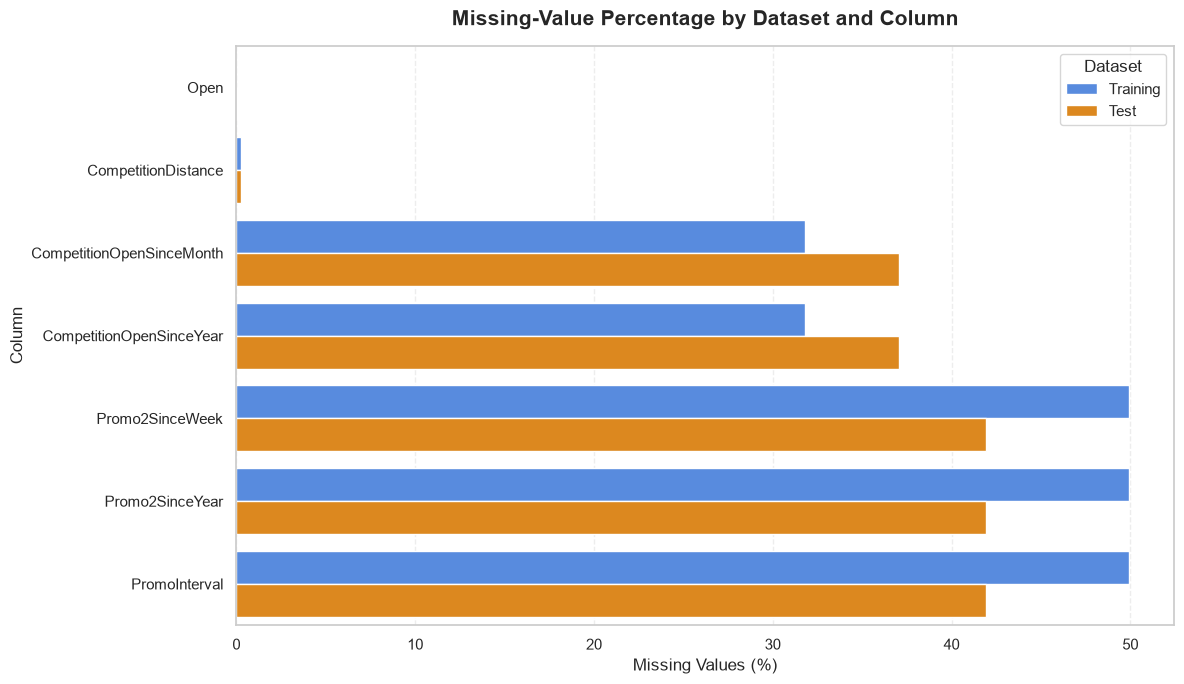

OVERALL DATA COMPLETENESS


,Dataset,Total_Cells,Complete_Cells,Missing_Cells,Completeness_Percentage,Missing_Percentage
0,Training,19326971,17153540,2173431,88.7544,11.2456
1,Test,739584,657349,82235,88.8809,11.1191


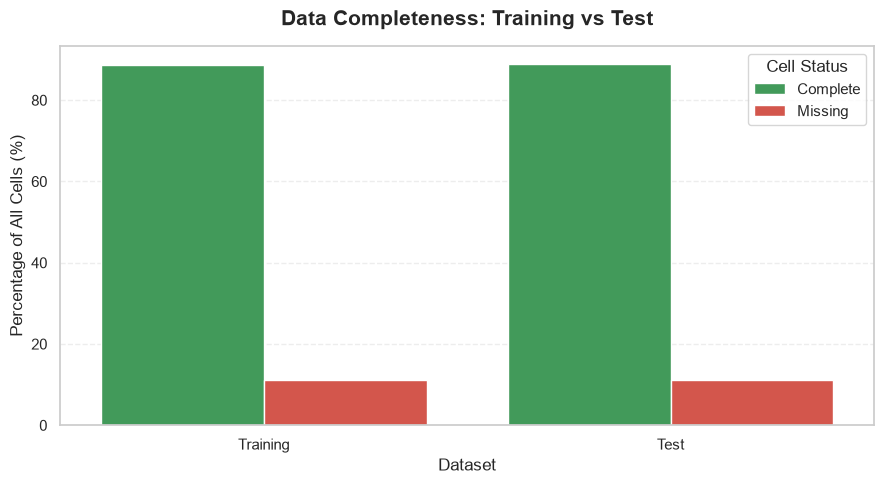


DUPLICATE RECORD CHECK


,Dataset,Exact_Duplicate_Rows,Duplicate_Store_Date_Pairs
0,Training,0,0
1,Test,0,0


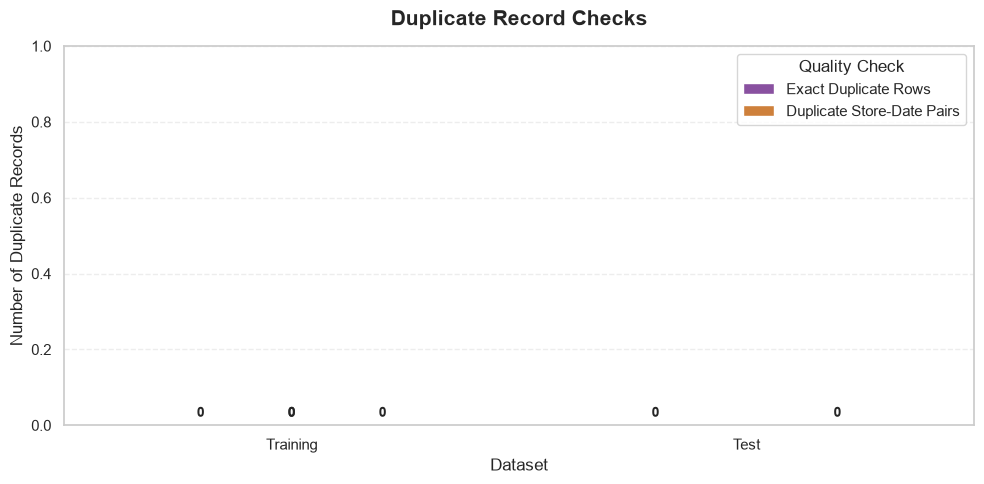

2026-10-31 09:23:13,658 | INFO | Project6_EDA | Section 9 completed. Training missing cells=2173431; Test missing cells=82235; Training exact duplicates=0; Test exact duplicates=0



Section 9 completed successfully.
No missing values or duplicate records were automatically removed or modified.


In [215]:

# ============================================================
# DATA QUALITY VISUALIZATIONS
# ============================================================
# Objectives:
# 1. Visualize missing-value percentages.
# 2. Compare data completeness between datasets.
# 3. Check exact duplicate records.
# 4. Check duplicate Store-Date combinations.
# 5. Preserve original data.
# ============================================================

# STEP 1: Define professional colors
QUALITY_COLORS = {
    "training": "#4285F4",
    "test": "#FB8C00",
    "complete": "#34A853",
    "missing": "#EA4335",
    "duplicate": "#AB47BC"
}

sns.set_theme(style="whitegrid", context="notebook")

# STEP 2: Prepare missing-value percentage data
def get_missing_percentages(dataframe, dataset_name):
    return pd.DataFrame({
        "Column": dataframe.columns,
        "Missing_Percentage": (
            dataframe.isna().mean().values * 100
        ),
        "Dataset": dataset_name
    })


train_missing_plot = get_missing_percentages(
    train_df, "Training"
)

test_missing_plot = get_missing_percentages(
    test_df, "Test"
)

missing_plot_data = pd.concat(
    [train_missing_plot, test_missing_plot],
    ignore_index=True
)

# Keep columns that have missing values in at least one dataset.
columns_with_missing = (
    missing_plot_data.groupby("Column")[
        "Missing_Percentage"
    ].max()
)

columns_with_missing = columns_with_missing[
    columns_with_missing > 0
].sort_values(ascending=True).index.tolist()

# STEP 3: Colorful missing-value percentage chart
if columns_with_missing:

    fig, ax = plt.subplots(figsize=(12, 7))

    chart_data = missing_plot_data[
        missing_plot_data["Column"].isin(
            columns_with_missing
        )
    ]

    sns.barplot(
        data=chart_data,
        x="Missing_Percentage",
        y="Column",
        hue="Dataset",
        palette={
            "Training": QUALITY_COLORS["training"],
            "Test": QUALITY_COLORS["test"]
        },
        ax=ax
    )

    ax.set_title(
        "Missing-Value Percentage by Dataset and Column",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Missing Values (%)", fontsize=12)
    ax.set_ylabel("Column", fontsize=12)
    ax.legend(title="Dataset")

    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.grid(axis="y", visible=False)

    plt.tight_layout()
    plt.show()

else:
    print("No missing values found in either dataset.")

# STEP 4: Visualize overall data completeness
def calculate_completeness(dataframe, dataset_name):
    total_cells = dataframe.shape[0] * dataframe.shape[1]
    missing_cells = int(dataframe.isna().sum().sum())
    complete_cells = total_cells - missing_cells

    return {
        "Dataset": dataset_name,
        "Total_Cells": total_cells,
        "Complete_Cells": complete_cells,
        "Missing_Cells": missing_cells,
        "Completeness_Percentage": (
            complete_cells / total_cells * 100
            if total_cells else np.nan
        ),
        "Missing_Percentage": (
            missing_cells / total_cells * 100
            if total_cells else np.nan
        )
    }


completeness_df = pd.DataFrame([
    calculate_completeness(train_df, "Training"),
    calculate_completeness(test_df, "Test")
])

print("=" * 80)
print("OVERALL DATA COMPLETENESS")
print("=" * 80)

display(
    completeness_df.round(4)
)

# Plot complete vs missing cells as percentages.
completeness_plot = completeness_df.melt(
    id_vars="Dataset",
    value_vars=[
        "Completeness_Percentage",
        "Missing_Percentage"
    ],
    var_name="Cell_Status",
    value_name="Percentage"
)

completeness_plot["Cell_Status"] = (
    completeness_plot["Cell_Status"].map({
        "Completeness_Percentage": "Complete",
        "Missing_Percentage": "Missing"
    })
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=completeness_plot,
    x="Dataset",
    y="Percentage",
    hue="Cell_Status",
    palette={
        "Complete": QUALITY_COLORS["complete"],
        "Missing": QUALITY_COLORS["missing"]
    },
    ax=ax
)

ax.set_title(
    "Data Completeness: Training vs Test",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Dataset", fontsize=12)
ax.set_ylabel("Percentage of All Cells (%)", fontsize=12)
ax.legend(title="Cell Status")

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

# STEP 5: Check exact duplicate rows and Store-Date pairs
def duplicate_quality_summary(dataframe, dataset_name):

    exact_duplicates = int(
        dataframe.duplicated().sum()
    )

    if {"Store", "Date"}.issubset(dataframe.columns):
        duplicate_store_dates = int(
            dataframe.duplicated(
                subset=["Store", "Date"]
            ).sum()
        )
    else:
        duplicate_store_dates = None

    return {
        "Dataset": dataset_name,
        "Exact_Duplicate_Rows": exact_duplicates,
        "Duplicate_Store_Date_Pairs": duplicate_store_dates
    }


duplicate_summary = pd.DataFrame([
    duplicate_quality_summary(train_df, "Training"),
    duplicate_quality_summary(test_df, "Test")
])

print("\n" + "=" * 80)
print("DUPLICATE RECORD CHECK")
print("=" * 80)

display(duplicate_summary)


# STEP 6: Visualize duplicate counts clearly
# Zero values are explicitly annotated because zero-height
# bars are otherwise difficult to see.

duplicate_plot = duplicate_summary.melt(
    id_vars="Dataset",
    value_vars=[
        "Exact_Duplicate_Rows",
        "Duplicate_Store_Date_Pairs"
    ],
    var_name="Check",
    value_name="Duplicate_Count"
)

duplicate_plot["Check"] = duplicate_plot["Check"].map({
    "Exact_Duplicate_Rows": "Exact Duplicate Rows",
    "Duplicate_Store_Date_Pairs": "Duplicate Store-Date Pairs"
})

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=duplicate_plot,
    x="Dataset",
    y="Duplicate_Count",
    hue="Check",
    palette={
        "Exact Duplicate Rows": "#8E44AD",
        "Duplicate Store-Date Pairs": "#E67E22"
    },
    ax=ax
)

ax.set_title(
    "Duplicate Record Checks",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Dataset", fontsize=12)
ax.set_ylabel("Number of Duplicate Records", fontsize=12)

# Keep a small positive range so zero labels have room to display.
ax.set_ylim(0, max(1, duplicate_plot["Duplicate_Count"].max() * 1.15))

# Annotate every bar position, including zero-count bars.
for patch in ax.patches:
    height = patch.get_height()

    ax.annotate(
        f"{int(height):,}",
        (
            patch.get_x() + patch.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        xytext=(0, 4),
        textcoords="offset points"
    )

ax.legend(title="Quality Check")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


# STEP 7: Log data-quality findings
logger.info(
    "Section 9 completed. Training missing cells=%d; "
    "Test missing cells=%d; Training exact duplicates=%d; "
    "Test exact duplicates=%d",
    int(train_df.isna().sum().sum()),
    int(test_df.isna().sum().sum()),
    int(train_df.duplicated().sum()),
    int(test_df.duplicated().sum())
)

print("\nSection 9 completed successfully.")
print(
    "No missing values or duplicate records were "
    "automatically removed or modified."
)


### **Key Insights — Data Quality Visualizations**

1. **Missing Values:** Missing values are concentrated in competition-related metadata and Promo2-related fields. The Promo2 metadata fields are missing when `Promo2 = 0`, indicating that these values are generally non-applicable rather than automatically representing data errors.

2. **Data Completeness:** The training dataset has approximately 88.75% complete cells, while the test dataset has approximately 88.88% complete cells. These percentages describe all dataset cells and include structurally non-applicable metadata.

3. **Duplicate Records:** No exact duplicate rows or duplicate Store-Date combinations were detected in either the training or test dataset. This supports the uniqueness of the observed store-date records.

4. **Data Handling:** Missing values and duplicate checks have been documented without automatically deleting records or filling values. Missing `Open` values in the test dataset and missing competition information require careful treatment before forecasting.

**Conclusion:** The duplicate-record checks show no detected duplication, while missing values remain the main data-quality consideration. Their meaning must be evaluated at the variable level before any imputation or feature engineering decisions are made.

## Part B — Univariate Analysis

### 10. **Distribution of Promotions in Training and Test Data**

This section examines the distribution of promotional and non-promotional records in the training and test datasets.

The analysis will:

1. Count records with `Promo = 0` and `Promo = 1` in each dataset.
2. Calculate the percentage of records in each promotion category.
3. Compare the promotion distributions between training and test data.
4. Visualize the category counts and percentage distributions using colorful charts.

This is a univariate analysis because it examines the distribution of a single variable, `Promo`, separately within each dataset. The results will help identify whether promotional records are represented differently in the training and test periods.

The distribution of promotional records alone does not establish whether promotions increase sales. Their relationship with sales and customer traffic will be investigated in the subsequent bivariate analysis.

PROMOTION DISTRIBUTION SUMMARY


,Dataset,Promo,Promotion_Status,Record_Count,Percentage
0,Training,0,No Promotion,"629,129",61.85%
1,Training,1,Promotion,"388,080",38.15%
2,Test,0,No Promotion,"24,824",60.42%
3,Test,1,Promotion,"16,264",39.58%


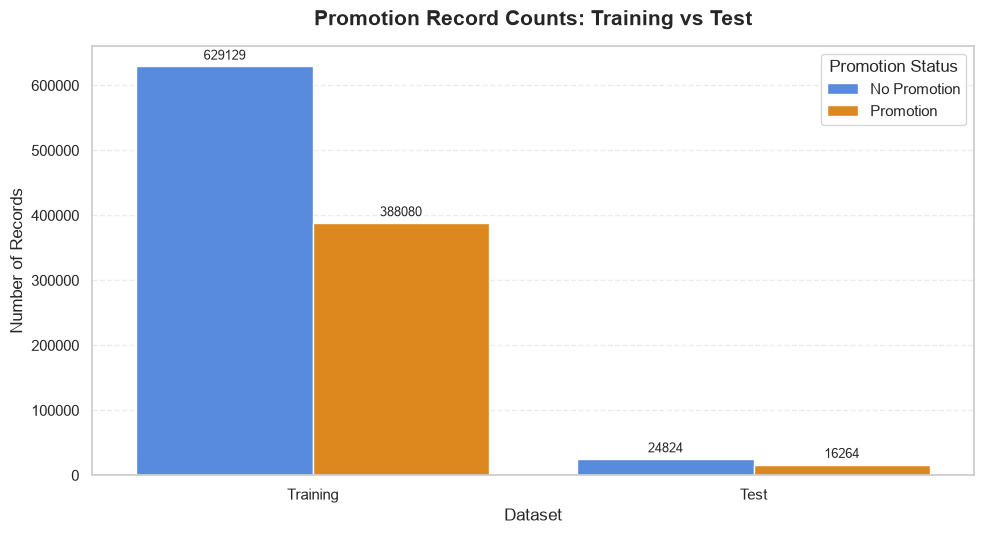

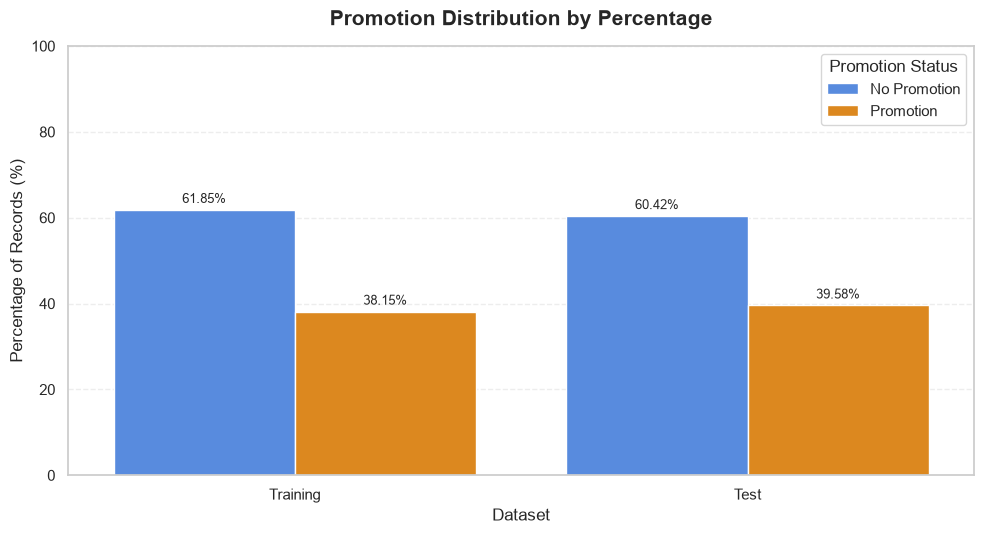

2026-10-31 09:23:14,094 | INFO | Project6_EDA | Section 10 completed. Promotion distribution analyzed for training and test datasets.



Section 10 completed successfully.
Interpretation reminder: This section describes promotion frequency, not promotional effectiveness.


In [216]:

# ============================================================
# DISTRIBUTION OF PROMOTIONS IN TRAINING AND TEST
# UNIVARIATE ANALYSIS
# ============================================================
# Objectives:
# 1. Count Promo=0 and Promo=1 records.
# 2. Calculate category percentages.
# 3. Compare training and test distributions.
# 4. Create colorful count and percentage charts.
# ============================================================

# STEP 1: Validate the Promo column
for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    if "Promo" not in dataframe.columns:
        raise ValueError(
            f"Promo column is missing from {dataset_name} data."
        )

    invalid_promo = ~dataframe["Promo"].isin([0, 1])

    if invalid_promo.any():
        raise ValueError(
            f"{dataset_name} contains unexpected Promo values. "
            "Inspect the column before continuing."
        )

# STEP 2: Calculate counts and percentages
promo_summaries = []

for dataset_name, dataframe in [
    ("Training", train_df),
    ("Test", test_df)
]:
    counts = dataframe["Promo"].value_counts().reindex(
        [0, 1], fill_value=0
    )

    total_records = len(dataframe)

    for promo_value in [0, 1]:
        count = int(counts.loc[promo_value])

        percentage = (
            count / total_records * 100
            if total_records else 0
        )

        promo_summaries.append({
            "Dataset": dataset_name,
            "Promo": promo_value,
            "Promotion_Status": (
                "No Promotion" if promo_value == 0
                else "Promotion"
            ),
            "Record_Count": count,
            "Percentage": round(percentage, 2)
        })

promo_summary_df = pd.DataFrame(promo_summaries)

print("=" * 80)
print("PROMOTION DISTRIBUTION SUMMARY")
print("=" * 80)

display(
    promo_summary_df.style.format({
        "Record_Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    }).background_gradient(
        subset=["Percentage"],
        cmap="Blues"
    )
)

# STEP 3: Colorful count chart
promo_palette = {
    "No Promotion": "#4285F4",
    "Promotion": "#FB8C00"
}

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=promo_summary_df,
    x="Dataset",
    y="Record_Count",
    hue="Promotion_Status",
    palette=promo_palette,
    ax=ax
)

ax.set_title(
    "Promotion Record Counts: Training vs Test",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Dataset", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)
ax.legend(title="Promotion Status")

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

# Display record counts above bars.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

# STEP 4: Colorful percentage comparison chart
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=promo_summary_df,
    x="Dataset",
    y="Percentage",
    hue="Promotion_Status",
    palette=promo_palette,
    ax=ax
)

ax.set_title(
    "Promotion Distribution by Percentage",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Dataset", fontsize=12)
ax.set_ylabel("Percentage of Records (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.legend(title="Promotion Status")

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

# STEP 5: Log findings
logger.info(
    "Section 10 completed. Promotion distribution analyzed "
    "for training and test datasets."
)

print("\nSection 10 completed successfully.")
print(
    "Interpretation reminder: This section describes "
    "promotion frequency, not promotional effectiveness."
)


### 11. **Key Distribution Findings — Promotion Analysis**

The univariate analysis of the `Promo` variable reveals the following findings:

1. **Training Dataset:** Out of 1,017,209 records, 629,129 records (61.85%) correspond to non-promotional days, while 388,080 records (38.15%) correspond to promotional days.

2. **Test Dataset:** Out of 41,088 records, 24,824 records (60.42%) correspond to non-promotional days, while 16,264 records (39.58%) correspond to promotional days.

3. **Comparison Between Datasets:** Promotional records account for 39.58% of the test dataset, compared with 38.15% of the training dataset. This represents a difference of approximately 1.43 percentage points.

4. **Distribution Consistency:** The training and test datasets have broadly similar promotion distributions. This provides useful context when evaluating how well the historical training data represents the later test period.

5. **Interpretation:** This analysis describes how frequently promotions occur. It does not establish whether promotions increase sales or customer traffic. Their relationship with sales and customers will be investigated in the next bivariate analysis.

**Conclusion:** Both datasets contain a substantial proportion of promotional records, and their promotion distributions are reasonably similar. Further analysis is required to understand the association between promotions, sales, and customer traffic.

## Part C — **Bivariate and Temporal Analysis**

### 12. **Impact of Promotions on Sales and Customers**

This section investigates the relationship between promotional activity and retail performance using the `Promo`, `Sales`, and `Customers` variables.

The analysis will:

1. Compare the number of open-store records with and without promotions.
2. Calculate mean and median sales for promotional and non-promotional records.
3. Calculate mean and median customer counts for both groups.
4. Estimate the percentage difference in average sales and customer counts.
5. Visualize the differences using colorful comparison charts.

Only records where `Open = 1` will be included in the primary comparison. This reduces the influence of store closures on sales and customer statistics.

The results are descriptive associations. Differences between promotional and non-promotional days may also reflect weekdays, holidays, seasonal patterns, and store characteristics. Therefore, the analysis will not treat the observed differences as proof of a causal promotional effect.

PROMOTION IMPACT ANALYSIS: OPEN STORES ONLY
Total open-store records analyzed: 844,392

SUMMARY STATISTICS


,Promotion_Status,Record_Count,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,No Promotion,"467,496","5,929.41","5,459.00",696.86,610.00
1,Promotion,"376,896","8,228.28","7,649.00",844.43,757.00



PERCENTAGE DIFFERENCES
Mean sales difference: +38.77%
Mean customer difference: +21.18%


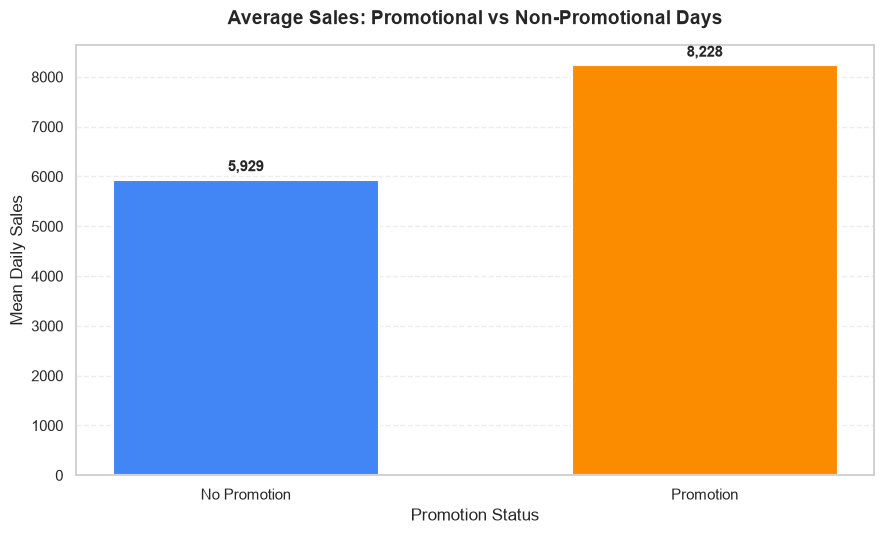

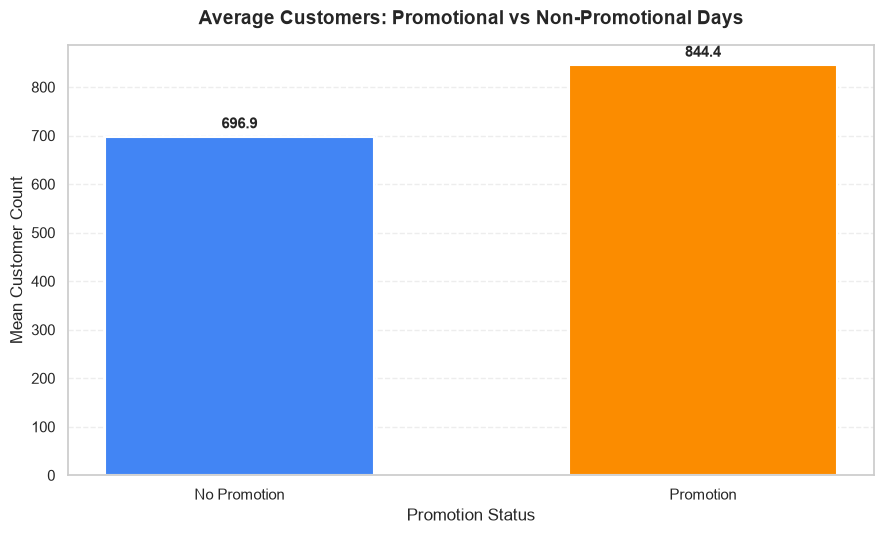

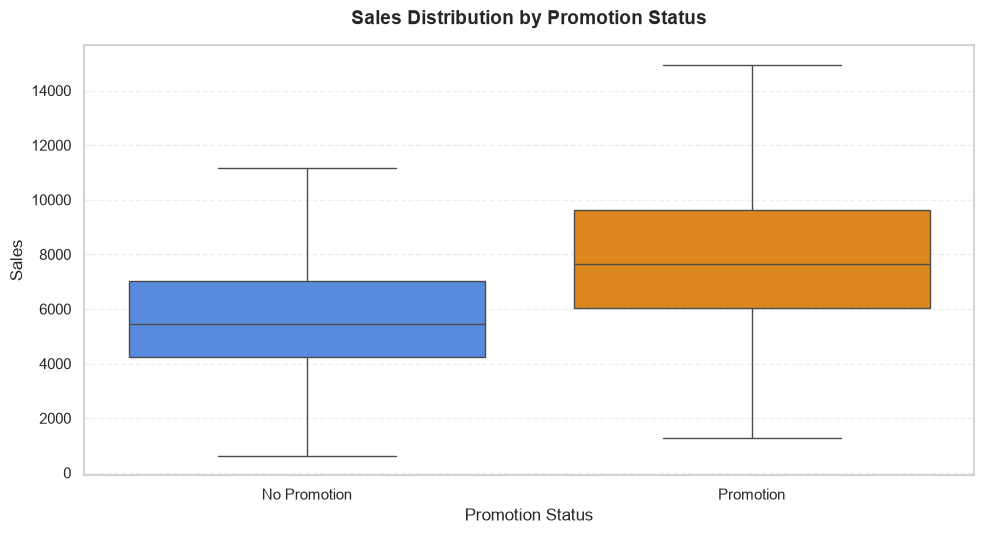

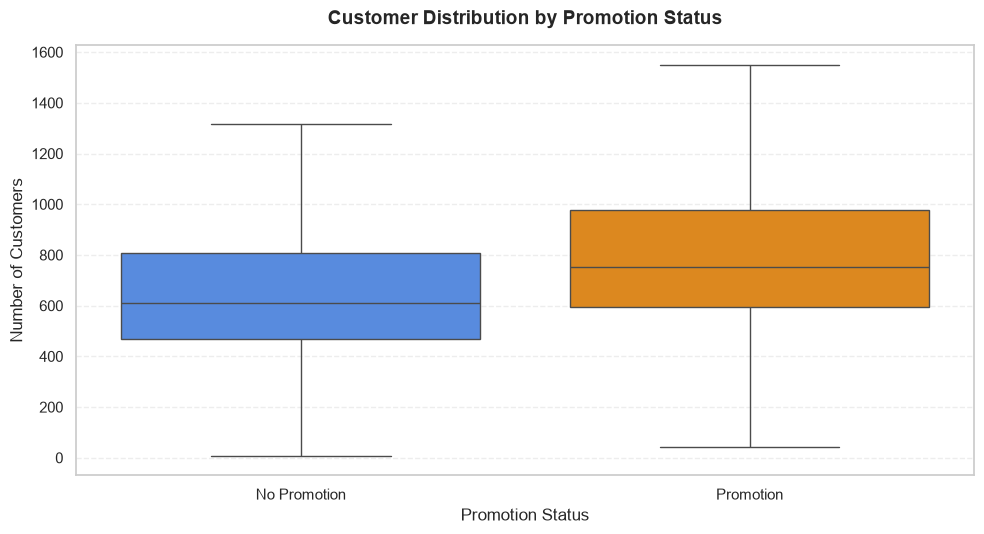

2026-10-31 09:23:15,549 | INFO | Project6_EDA | Section 12 completed. Open-store records=844392; mean sales difference=38.77%; mean customer difference=21.18%



Section 12 completed successfully.
Note: Observed differences are associations, not proof of causal promotional effects.


In [217]:

# ============================================================
# IMPACT OF PROMOTIONS ON SALES AND CUSTOMERS
# BIVARIATE ANALYSIS
# ============================================================
# Objectives:
# 1. Compare sales and customer counts by Promo status.
# 2. Calculate means, medians and percentage differences.
# 3. Create colorful comparison charts.
# 4. Use only records where stores are open.
# 5. Interpret findings as associations, not causal effects.
# ============================================================

# STEP 1: Validate required columns
required_columns = ["Promo", "Sales", "Customers", "Open"]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Select open-store records
promotion_analysis_df = train_df.loc[
    train_df["Open"].eq(1),
    ["Promo", "Sales", "Customers"]
].copy()

# Remove rows with missing values in variables needed here.
promotion_analysis_df = promotion_analysis_df.dropna(
    subset=["Promo", "Sales", "Customers"]
)

promotion_analysis_df["Promotion_Status"] = (
    promotion_analysis_df["Promo"].map({
        0: "No Promotion",
        1: "Promotion"
    })
)

print("=" * 85)
print("PROMOTION IMPACT ANALYSIS: OPEN STORES ONLY")
print("=" * 85)

print(
    f"Total open-store records analyzed: "
    f"{len(promotion_analysis_df):,}"
)

# STEP 3: Calculate summary statistics
promotion_summary = (
    promotion_analysis_df
    .groupby("Promotion_Status", observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reindex(["No Promotion", "Promotion"])
    .reset_index()
)

# STEP 4: Calculate percentage differences
no_promo = promotion_summary.loc[
    promotion_summary["Promotion_Status"] == "No Promotion"
].iloc[0]

promo = promotion_summary.loc[
    promotion_summary["Promotion_Status"] == "Promotion"
].iloc[0]

sales_difference_pct = (
    (promo["Mean_Sales"] - no_promo["Mean_Sales"])
    / no_promo["Mean_Sales"] * 100
    if no_promo["Mean_Sales"] != 0 else np.nan
)

customers_difference_pct = (
    (promo["Mean_Customers"] - no_promo["Mean_Customers"])
    / no_promo["Mean_Customers"] * 100
    if no_promo["Mean_Customers"] != 0 else np.nan
)

print("\nSUMMARY STATISTICS")
display(
    promotion_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

print("\n" + "=" * 85)
print("PERCENTAGE DIFFERENCES")
print("=" * 85)

print(
    f"Mean sales difference: {sales_difference_pct:+.2f}%"
)

print(
    f"Mean customer difference: "
    f"{customers_difference_pct:+.2f}%"
)

# STEP 5: Colorful mean sales comparison
promotion_colors = {
    "No Promotion": "#4285F4",
    "Promotion": "#FB8C00"
}

fig, ax = plt.subplots(figsize=(9, 5.5))

sales_values = [
    no_promo["Mean_Sales"],
    promo["Mean_Sales"]
]

bars = ax.bar(
    ["No Promotion", "Promotion"],
    sales_values,
    color=[
        promotion_colors["No Promotion"],
        promotion_colors["Promotion"]
    ],
    width=0.58,
    edgecolor="white",
    linewidth=1.5
)

ax.set_title(
    "Average Sales: Promotional vs Non-Promotional Days",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Promotion Status", fontsize=12)
ax.set_ylabel("Mean Daily Sales", fontsize=12)

ax.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in sales_values],
    padding=4,
    fontsize=11,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# STEP 6: Colorful mean customer comparison
customer_values = [
    no_promo["Mean_Customers"],
    promo["Mean_Customers"]
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    ["No Promotion", "Promotion"],
    customer_values,
    color=[
        promotion_colors["No Promotion"],
        promotion_colors["Promotion"]
    ],
    width=0.58,
    edgecolor="white",
    linewidth=1.5
)

ax.set_title(
    "Average Customers: Promotional vs Non-Promotional Days",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Promotion Status", fontsize=12)
ax.set_ylabel("Mean Customer Count", fontsize=12)

ax.bar_label(
    bars,
    labels=[f"{value:,.1f}" for value in customer_values],
    padding=4,
    fontsize=11,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# STEP 7: Compare distributions with boxplots.
# A reproducible sample improves plotting performance.
plot_sample = promotion_analysis_df.sample(
    n=min(50000, len(promotion_analysis_df)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=plot_sample,
    x="Promotion_Status",
    y="Sales",
    order=["No Promotion", "Promotion"],
    hue="Promotion_Status",
    hue_order=["No Promotion", "Promotion"],
    palette=promotion_colors,
    showfliers=False,
    legend=False,
    ax=ax
)

ax.set_title(
    "Sales Distribution by Promotion Status",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Promotion Status", fontsize=12)
ax.set_ylabel("Sales", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=plot_sample,
    x="Promotion_Status",
    y="Customers",
    order=["No Promotion", "Promotion"],
    hue="Promotion_Status",
    hue_order=["No Promotion", "Promotion"],
    palette=promotion_colors,
    showfliers=False,
    legend=False,
    ax=ax
)

ax.set_title(
    "Customer Distribution by Promotion Status",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Promotion Status", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

# STEP 8: Log the results
logger.info(
    "Section 12 completed. Open-store records=%d; "
    "mean sales difference=%.2f%%; "
    "mean customer difference=%.2f%%",
    len(promotion_analysis_df),
    sales_difference_pct,
    customers_difference_pct
)

print("\nSection 12 completed successfully.")
print(
    "Note: Observed differences are associations, "
    "not proof of causal promotional effects."
)


### 13. **Key Insights — Promotion Impact**

The bivariate analysis compared sales and customer traffic between promotional and non-promotional records for open stores.

1. **Higher Average Sales:** Mean sales were 8,228.28 on promotional records, compared with 5,929.41 on non-promotional records. This represents an observed increase of approximately 38.77%.

2. **Higher Average Customer Traffic:** Mean customer counts were 844.43 on promotional records and 696.86 on non-promotional records, representing an observed increase of approximately 21.18%.

3. **Median Comparison:** Median sales were 7,649 during promotional records versus 5,459 without promotions. Median customer counts were 757 and 610, respectively. These differences indicate that the observed pattern is also present when comparing medians rather than only means.

4. **Distributional Differences:** The boxplots allow comparison of the central distributions of sales and customer counts. Extreme points are hidden for visual clarity, but no observations were deleted from the underlying data.

5. **Business Interpretation:** Promotional records are associated with higher sales and customer traffic in the observed dataset. However, differences in weekdays, holidays, seasonality, store types, and individual store characteristics may contribute to this pattern.

**Conclusion:** Promotional records show higher average and median sales and customer counts. Further analysis is needed to understand how these relationships change around holidays and across different store characteristics. These descriptive results should not be interpreted as proof of a causal promotional effect.

### 14. **Sales Before, During, and After Holidays**

This section examines how retail sales vary around state holidays in the training dataset.

The analysis will:

1. Identify holiday dates using the `StateHoliday` variable.
2. Compare sales on open-store records during holidays with sales in the surrounding periods.
3. Calculate record counts, unique stores, mean sales, median sales, and mean customer counts for each period.
4. Visualize sales across the defined holiday periods using colorful charts.
5. Report the number of open-store records in each group to provide context for interpreting the comparisons.

For this analysis, a seven-calendar-day window before and after each identified holiday will be used. If a date falls within overlapping holiday windows, it will be assigned to the nearest holiday date; ties will be assigned consistently to the earlier holiday. Dates outside these windows will be classified as other days.

These comparisons are descriptive. Holiday-related differences may also be influenced by store closures, weekdays, promotions, and seasonal effects.

HOLIDAY DATE IDENTIFICATION
Unique holiday dates identified: 37
First holiday date: 2013-01-01
Last holiday date : 2015-06-04

SALES AND CUSTOMER SUMMARY BY HOLIDAY PHASE


,Holiday_Phase,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers
0,Before Holiday,"140,935","1,115","7,533.11","6,908.00",807.54
1,During Holiday,"9,194","1,115","7,728.29","7,110.50",893.80
2,After Holiday,"162,896","1,115","7,074.08","6,546.00",773.79
3,Other Days,"531,367","1,115","6,752.60","6,175.00",745.18


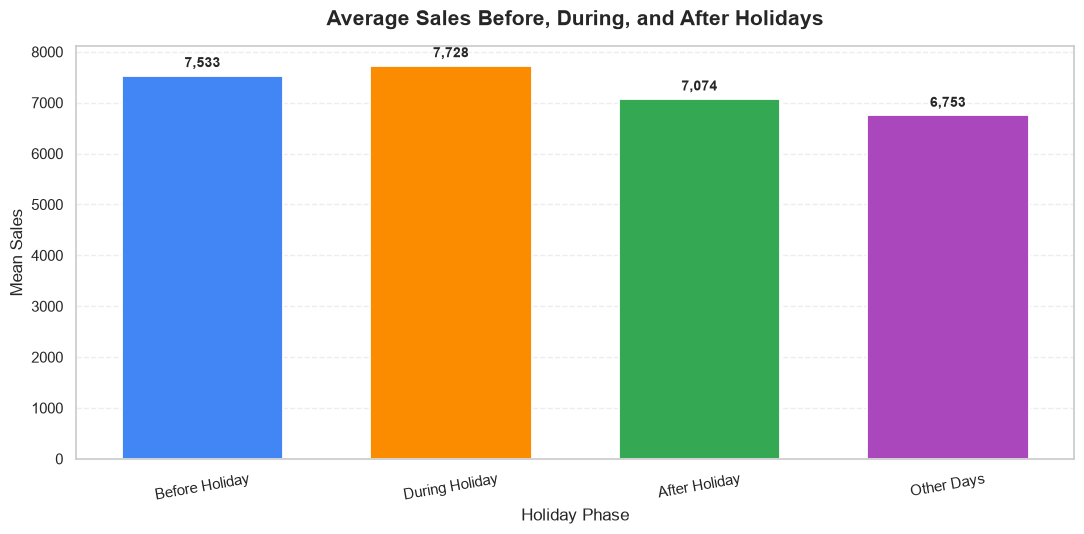

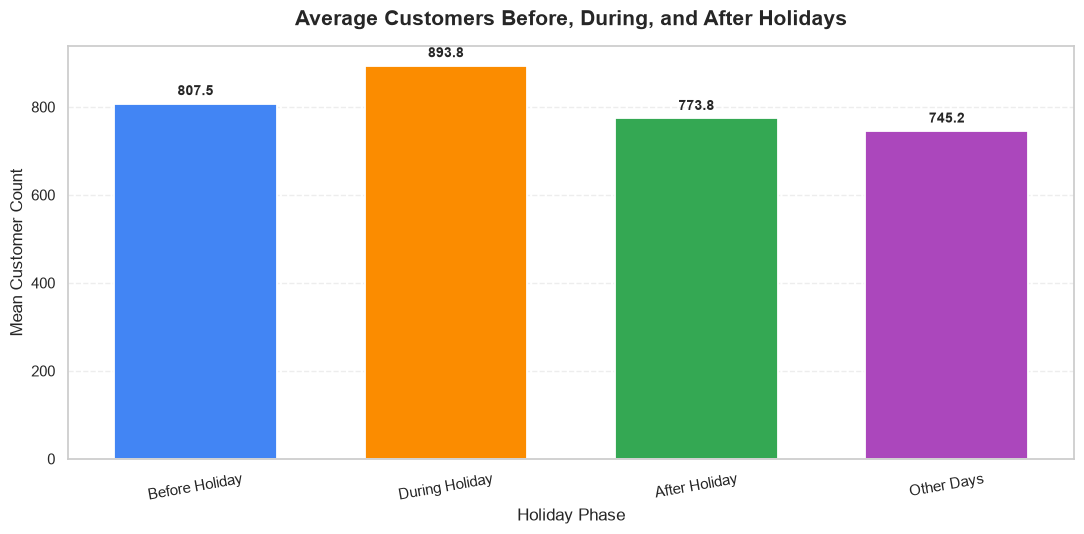

2026-10-31 09:23:16,355 | INFO | Project6_EDA | Section 14 completed. Identified 37 unique holiday dates; analyzed 844392 open-store records.



Section 14 completed successfully.
Interpretation: These are descriptive comparisons. Holiday effects are not isolated from other factors.


In [218]:

# ============================================================
# SALES BEFORE, DURING, AND AFTER HOLIDAYS
# ============================================================
# Holiday definition:
# StateHoliday values other than 0 indicate holiday dates.
# Window: 7 calendar days before and after each holiday.
# Overlapping windows: assign each date to nearest holiday.
# Ties: assign to the earlier holiday.
# Analysis: open-store records only.
# ============================================================

# STEP 1: Validate required columns
required_columns = [
    "Date", "StateHoliday", "Sales", "Customers",
    "Open", "Store"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Prepare data without modifying train_df
holiday_df = train_df[
    required_columns + (
        ["Promo"] if "Promo" in train_df.columns else []
    )
].copy()

holiday_df["Date"] = pd.to_datetime(
    holiday_df["Date"], errors="coerce"
)

# Normalize StateHoliday values.
# Both numeric 0 and string "0" are treated as non-holidays.
state_holiday = (
    holiday_df["StateHoliday"]
    .astype("string")
    .str.strip()
    .str.lower()
)

non_holiday_values = {"0", "0.0", "", "nan", "none", "<na>"}

holiday_mask = (
    state_holiday.notna()
    & ~state_holiday.isin(non_holiday_values)
)

holiday_dates = pd.DatetimeIndex(
    holiday_df.loc[holiday_mask, "Date"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

if len(holiday_dates) == 0:
    raise ValueError(
        "No holiday dates were identified from StateHoliday. "
        "Check the column values before proceeding."
    )

print("=" * 80)
print("HOLIDAY DATE IDENTIFICATION")
print("=" * 80)

print(f"Unique holiday dates identified: {len(holiday_dates):,}")
print(f"First holiday date: {holiday_dates.min().date()}")
print(f"Last holiday date : {holiday_dates.max().date()}")

# STEP 3: Assign each date to its nearest holiday.
# Search is performed over unique dates for efficiency.
unique_train_dates = pd.DatetimeIndex(
    holiday_df["Date"].dropna().drop_duplicates().sort_values()
)

# Each unique date starts as Other Days.
date_phase = pd.Series(
    "Other Days",
    index=unique_train_dates
)

# Calculate distances from every date to every holiday.
# There are relatively few holiday dates compared with daily records.
distance_matrix = np.abs(
    (
        unique_train_dates.values[:, None]
        - holiday_dates.values[None, :]
    ).astype("timedelta64[D]").astype(int)
)

nearest_positions = distance_matrix.argmin(axis=1)
nearest_distances = distance_matrix[
    np.arange(len(unique_train_dates)),
    nearest_positions
]

# Determine nearest holiday and distance for each date.
nearest_holiday = holiday_dates.take(nearest_positions)

# Assign phases according to distance from the nearest holiday.
for date, holiday_date, distance in zip(
    unique_train_dates,
    nearest_holiday,
    nearest_distances
):
    if distance == 0:
        date_phase.loc[date] = "During Holiday"
    elif 1 <= distance <= 7:
        if date < holiday_date:
            date_phase.loc[date] = "Before Holiday"
        else:
            date_phase.loc[date] = "After Holiday"

# STEP 4: Attach phases and select open-store records
holiday_df["Holiday_Phase"] = (
    holiday_df["Date"].map(date_phase)
)

open_holiday_df = holiday_df.loc[
    holiday_df["Open"].eq(1)
    & holiday_df["Date"].notna()
    & holiday_df["Sales"].notna()
].copy()

phase_order = [
    "Before Holiday",
    "During Holiday",
    "After Holiday",
    "Other Days"
]

open_holiday_df["Holiday_Phase"] = pd.Categorical(
    open_holiday_df["Holiday_Phase"],
    categories=phase_order,
    ordered=True
)

# STEP 5: Calculate descriptive statistics
holiday_summary = (
    open_holiday_df
    .groupby(
        "Holiday_Phase",
        observed=False
    )
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean")
    )
    .reindex(phase_order)
    .reset_index()
)

print("\n" + "=" * 80)
print("SALES AND CUSTOMER SUMMARY BY HOLIDAY PHASE")
print("=" * 80)

display(
    holiday_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

# STEP 6: Colorful mean sales chart
holiday_colors = {
    "Before Holiday": "#4285F4",
    "During Holiday": "#FB8C00",
    "After Holiday": "#34A853",
    "Other Days": "#AB47BC"
}

sales_chart_data = holiday_summary.dropna(
    subset=["Mean_Sales"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.bar(
    sales_chart_data["Holiday_Phase"].astype(str),
    sales_chart_data["Mean_Sales"],
    color=[
        holiday_colors[str(phase)]
        for phase in sales_chart_data["Holiday_Phase"]
    ],
    width=0.65,
    edgecolor="white",
    linewidth=1.3
)

ax.set_title(
    "Average Sales Before, During, and After Holidays",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Holiday Phase", fontsize=12)
ax.set_ylabel("Mean Sales", fontsize=12)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in sales_chart_data["Mean_Sales"]
    ],
    padding=4,
    fontsize=10,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# STEP 7: Colorful mean customer chart
customer_chart_data = holiday_summary.dropna(
    subset=["Mean_Customers"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.bar(
    customer_chart_data["Holiday_Phase"].astype(str),
    customer_chart_data["Mean_Customers"],
    color=[
        holiday_colors[str(phase)]
        for phase in customer_chart_data["Holiday_Phase"]
    ],
    width=0.65,
    edgecolor="white",
    linewidth=1.3
)

ax.set_title(
    "Average Customers Before, During, and After Holidays",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Holiday Phase", fontsize=12)
ax.set_ylabel("Mean Customer Count", fontsize=12)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.1f}"
        for value in customer_chart_data["Mean_Customers"]
    ],
    padding=4,
    fontsize=10,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# STEP 8: Log findings
logger.info(
    "Section 14 completed. Identified %d unique holiday dates; "
    "analyzed %d open-store records.",
    len(holiday_dates),
    len(open_holiday_df)
)

print("\nSection 14 completed successfully.")
print(
    "Interpretation: These are descriptive comparisons. "
    "Holiday effects are not isolated from other factors."
)


### 15. **Key Insights — Holiday Analysis**

The analysis compared sales and customer traffic during the seven-day periods before and after identified state holidays, on the holiday dates themselves, and on other days. Only open-store records were included.

1. **Higher Sales During Holidays:** Mean sales during holidays were 7,728.29, compared with 6,752.60 on other days. This represents an observed difference of approximately 14.45%.

2. **Higher Sales Before Holidays:** Mean sales before holidays were 7,533.11, approximately 11.56% higher than the mean on other days. This pattern is consistent with increased retail activity in the days leading up to holidays.

3. **Sales After Holidays:** Mean sales after holidays were 7,074.08, approximately 4.76% higher than on other days. The difference is smaller than the observed differences before and during holidays.

4. **Customer Traffic:** Mean customer counts were highest during holidays at 893.80, followed by 807.54 before holidays, 773.79 after holidays, and 745.18 on other days. This indicates that the holiday periods in this dataset are associated with higher customer traffic.

5. **Interpretation and Limitations:** The number of records varies substantially between groups. Store closures, weekday composition, promotional activity, and seasonality may influence the results. The comparisons therefore describe observed associations and do not isolate the causal effect of holidays.

**Conclusion:** In the observed open-store records, mean sales and customer counts were highest on identified holiday dates, followed by the pre-holiday period. Further seasonal analysis will help determine how these patterns vary across months and major retail periods.

### 16. **Seasonal Sales Behavior: Monthly Trends, Christmas, and Easter**

This section examines temporal patterns in retail sales and customer traffic across months and selected seasonal periods.

The analysis will:

1. Calculate monthly mean sales and customer counts for each year.
2. Compare monthly sales trends across 2013, 2014, and 2015.
3. Examine sales and customer traffic during the Christmas period, defined as December 20–31.
4. Examine sales and customer traffic during the Easter period, defined as seven calendar days before through seven calendar days after Easter Sunday.
5. Compare these event-window observations with other open-store records.
6. Visualize monthly trends and seasonal-period comparisons using colorful charts.

Only records where stores are open will be included in the primary sales and customer comparisons. Because the training dataset ends on July 31, 2015, the 2015 monthly trend represents only the available portion of that year.

These comparisons are descriptive. Differences between months and seasonal periods may also reflect promotions, holidays, weekdays, and store-level characteristics.

SEASONAL SALES ANALYSIS — DATA OVERVIEW
Eligible open-store records: 844,392
Unique stores: 1,115
Date range: 2013-01-01 to 2015-07-31

MONTHLY SALES AND CUSTOMER SUMMARY


,Year,Month,Month_Name,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers
0,2013,1,January,"28,869","1,112","6,239.64","5,749.00",705.96
1,2013,2,February,"26,683","1,112","6,428.60","5,913.00",721.23
2,2013,3,March,"27,892","1,112","7,212.83","6,656.00",787.66
3,2013,4,April,"27,880","1,113","6,579.32","6,032.00",749.01
4,2013,5,May,"26,202","1,113","7,076.22","6,547.00",790.93
5,2013,6,June,"27,942","1,113","6,467.05","5,970.00",732.70
6,2013,7,July,"30,166","1,115","6,923.15","6,291.00",758.21
7,2013,8,August,"30,025","1,115","6,595.93","6,063.00",743.19
8,2013,9,September,"27,981","1,115","6,363.39","5,843.00",727.28
9,2013,10,October,"28,990","1,115","6,473.35","5,962.00",737.19


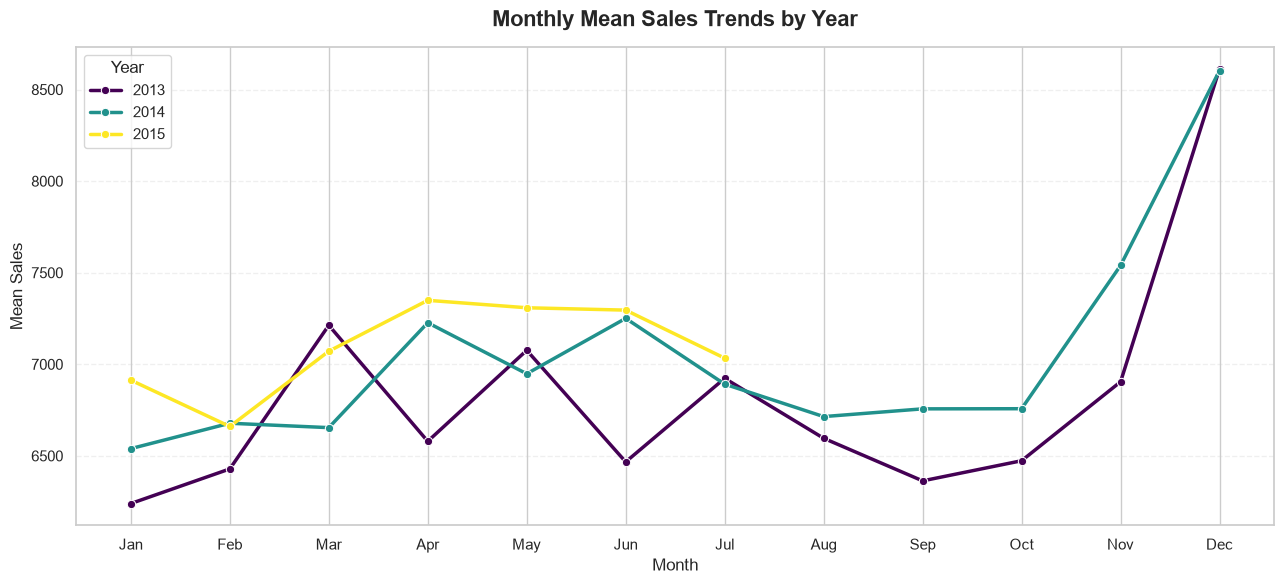

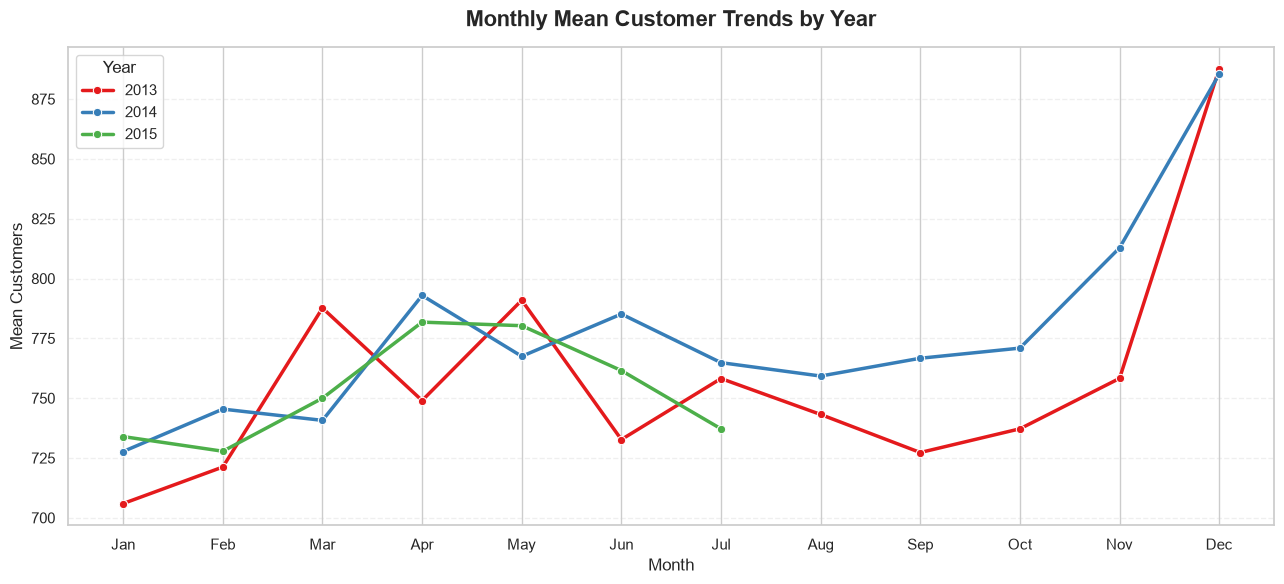


CHRISTMAS AND EASTER PERIOD COMPARISON


,Seasonal_Period,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,Other Days,"794,005","1,115","6,904.41","6,338.00",758.00,673.00
1,Christmas Period,"16,574","1,115","7,977.34","7,151.00",861.90,745.00
2,Easter Period,"33,813","1,115","7,654.74","6,959.00",825.13,730.00


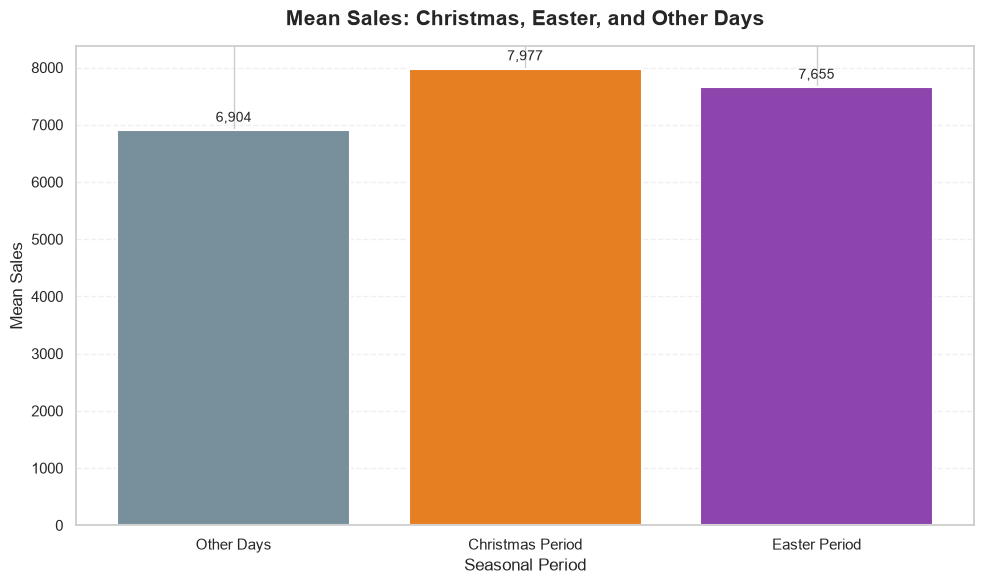

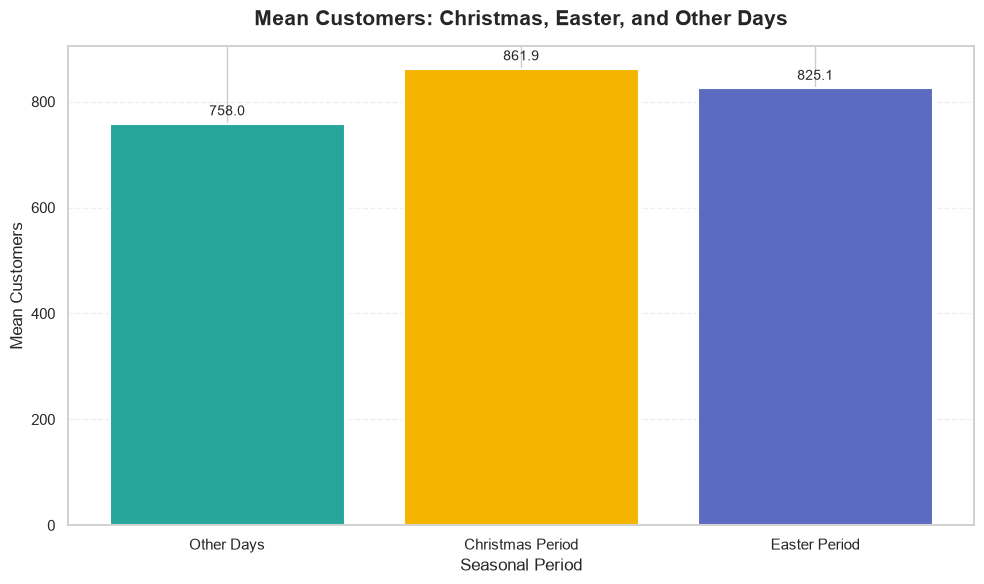


SEASONAL DIFFERENCES COMPARED WITH OTHER DAYS


,Seasonal_Period,Sales_Difference_Percent,Customers_Difference_Percent
1,Christmas Period,+15.54%,+13.71%
2,Easter Period,+10.87%,+8.86%


2026-10-31 09:23:17,579 | INFO | Project6_EDA | Section 16 seasonal analysis completed. Eligible records=844392; unique stores=1115.



Section 16 seasonal analysis completed successfully.
Check all tables and charts before writing the final insights.


In [219]:

# ============================================================
# SEASONAL SALES BEHAVIOR
# Monthly Trends, Christmas, and Easter
# ============================================================
# Objectives:
# 1. Analyze monthly sales and customer trends by year.
# 2. Compare Christmas-period performance.
# 3. Compare Easter-period performance.
# 4. Display colorful, professional visualizations.
# 5. Generate summary tables for interpretation.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 1: Verify required columns
required_columns = [
    "Store", "Date", "Sales", "Customers", "Open"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing from train_df: {missing_columns}"
    )

# STEP 2: Prepare the analysis dataset
# Keep Store so that Unique_Stores is calculated correctly.
seasonal_df = train_df[required_columns].copy()

# Ensure Date and numerical columns have suitable data types.
seasonal_df["Date"] = pd.to_datetime(
    seasonal_df["Date"], errors="coerce"
)

for col in ["Sales", "Customers", "Open"]:
    seasonal_df[col] = pd.to_numeric(
        seasonal_df[col], errors="coerce"
    )

# Use only open-store records with valid dates, sales, and customers.
seasonal_df = seasonal_df.loc[
    seasonal_df["Open"].eq(1)
    & seasonal_df["Date"].notna()
    & seasonal_df["Sales"].notna()
    & seasonal_df["Customers"].notna()
].copy()

# STEP 3: Create calendar features
seasonal_df["Year"] = seasonal_df["Date"].dt.year
seasonal_df["Month"] = seasonal_df["Date"].dt.month

seasonal_df["Month_Name"] = seasonal_df["Date"].dt.month_name()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

seasonal_df["Month_Name"] = pd.Categorical(
    seasonal_df["Month_Name"],
    categories=month_order,
    ordered=True
)

print("=" * 75)
print("SEASONAL SALES ANALYSIS — DATA OVERVIEW")
print("=" * 75)

print(f"Eligible open-store records: {len(seasonal_df):,}")
print(f"Unique stores: {seasonal_df['Store'].nunique():,}")
print(
    f"Date range: {seasonal_df['Date'].min().date()} "
    f"to {seasonal_df['Date'].max().date()}"
)

# ============================================================
# PART A: MONTHLY SALES AND CUSTOMER TRENDS
# ============================================================

# STEP 4: Calculate monthly averages by year
monthly_summary = (
    seasonal_df
    .groupby(
        ["Year", "Month", "Month_Name"],
        observed=True
    )
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean")
    )
    .reset_index()
    .sort_values(["Year", "Month"])
)

print("\n" + "=" * 75)
print("MONTHLY SALES AND CUSTOMER SUMMARY")
print("=" * 75)

display(
    monthly_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales"],
        cmap="YlGnBu"
    )
)

# STEP 5: Plot monthly mean sales by year
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_summary,
    x="Month",
    y="Mean_Sales",
    hue="Year",
    marker="o",
    linewidth=2.5,
    palette="viridis"
)

plt.title(
    "Monthly Mean Sales Trends by Year",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Mean Sales", fontsize=12)

plt.xticks(
    ticks=range(1, 13),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# STEP 6: Plot monthly mean customers by year
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_summary,
    x="Month",
    y="Mean_Customers",
    hue="Year",
    marker="o",
    linewidth=2.5,
    palette="Set1"
)

plt.title(
    "Monthly Mean Customer Trends by Year",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Mean Customers", fontsize=12)

plt.xticks(
    ticks=range(1, 13),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# ============================================================
# PART B: CHRISTMAS AND EASTER ANALYSIS
# ============================================================

# STEP 7: Define Easter Sunday dates for the study period.
# Easter dates are calendar dates, not dates inferred from sales.
easter_dates = {
    2013: pd.Timestamp("2013-03-31"),
    2014: pd.Timestamp("2014-04-20"),
    2015: pd.Timestamp("2015-04-05")
}

# STEP 8: Classify seasonal periods
# Christmas: December 20–31 inclusive.
# Easter: seven days before through seven days after Easter Sunday.
seasonal_df["Seasonal_Period"] = "Other Days"

christmas_mask = (
    (seasonal_df["Date"].dt.month == 12)
    & (seasonal_df["Date"].dt.day >= 20)
)

seasonal_df.loc[
    christmas_mask, "Seasonal_Period"
] = "Christmas Period"

# Build the Easter window mask using the correct Easter date for each year.
easter_mask = pd.Series(
    False, index=seasonal_df.index
)

for year, easter_sunday in easter_dates.items():
    window_start = easter_sunday - pd.Timedelta(days=7)
    window_end = easter_sunday + pd.Timedelta(days=7)

    year_mask = (
        seasonal_df["Date"].dt.year.eq(year)
        & seasonal_df["Date"].between(
            window_start, window_end, inclusive="both"
        )
    )

    easter_mask = easter_mask | year_mask

seasonal_df.loc[
    easter_mask, "Seasonal_Period"
] = "Easter Period"

# STEP 9: Calculate summary statistics by seasonal period.
# Unique_Stores now uses the actual Store column.
seasonal_order = [
    "Other Days",
    "Christmas Period",
    "Easter Period"
]

seasonal_df["Seasonal_Period"] = pd.Categorical(
    seasonal_df["Seasonal_Period"],
    categories=seasonal_order,
    ordered=True
)

seasonal_summary = (
    seasonal_df
    .groupby("Seasonal_Period", observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reindex(seasonal_order)
    .reset_index()
)

print("\n" + "=" * 75)
print("CHRISTMAS AND EASTER PERIOD COMPARISON")
print("=" * 75)

display(
    seasonal_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales"],
        cmap="YlOrRd"
    )
)

# STEP 10: Plot mean sales by seasonal period
sales_colors = ["#78909C", "#E67E22", "#8E44AD"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    seasonal_summary["Seasonal_Period"].astype(str),
    seasonal_summary["Mean_Sales"],
    color=sales_colors,
    edgecolor="white",
    linewidth=1.5
)

ax.set_title(
    "Mean Sales: Christmas, Easter, and Other Days",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Seasonal Period", fontsize=12)
ax.set_ylabel("Mean Sales", fontsize=12)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in seasonal_summary["Mean_Sales"]
    ],
    padding=4,
    fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# STEP 11: Plot mean customers by seasonal period
customer_colors = ["#26A69A", "#F4B400", "#5C6BC0"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    seasonal_summary["Seasonal_Period"].astype(str),
    seasonal_summary["Mean_Customers"],
    color=customer_colors,
    edgecolor="white",
    linewidth=1.5
)

ax.set_title(
    "Mean Customers: Christmas, Easter, and Other Days",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Seasonal Period", fontsize=12)
ax.set_ylabel("Mean Customers", fontsize=12)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.1f}"
        for value in seasonal_summary["Mean_Customers"]
    ],
    padding=4,
    fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ============================================================
# PART C: AUTOMATIC COMPARISON WITH OTHER DAYS
# ============================================================

# STEP 12: Calculate percentage differences against Other Days.
baseline_rows = seasonal_summary.loc[
    seasonal_summary["Seasonal_Period"] == "Other Days"
]

if baseline_rows.empty:
    print(
        "\nWarning: No Other Days baseline was available "
        "for percentage comparisons."
    )
else:
    baseline = baseline_rows.iloc[0]

    comparison_rows = seasonal_summary.loc[
        seasonal_summary["Seasonal_Period"] != "Other Days"
    ].copy()

    comparison_rows["Sales_Difference_Percent"] = (
        (
            comparison_rows["Mean_Sales"]
            - baseline["Mean_Sales"]
        )
        / baseline["Mean_Sales"]
        * 100
    )

    comparison_rows["Customers_Difference_Percent"] = (
        (
            comparison_rows["Mean_Customers"]
            - baseline["Mean_Customers"]
        )
        / baseline["Mean_Customers"]
        * 100
    )

    print("\n" + "=" * 75)
    print("SEASONAL DIFFERENCES COMPARED WITH OTHER DAYS")
    print("=" * 75)

    display(
        comparison_rows[
            [
                "Seasonal_Period",
                "Sales_Difference_Percent",
                "Customers_Difference_Percent"
            ]
        ].style.format({
            "Sales_Difference_Percent": "{:+.2f}%",
            "Customers_Difference_Percent": "{:+.2f}%"
        }).background_gradient(
            subset=[
                "Sales_Difference_Percent",
                "Customers_Difference_Percent"
            ],
            cmap="RdYlGn"
        )
    )

# STEP 13: Log completion.
logger.info(
    "Section 16 seasonal analysis completed. "
    "Eligible records=%d; unique stores=%d.",
    len(seasonal_df),
    seasonal_df["Store"].nunique()
)

print("\nSection 16 seasonal analysis completed successfully.")
print("Check all tables and charts before writing the final insights.")


### 17. **Key Insights — Seasonal Sales Analysis**

**1. Monthly Sales Patterns**

- December recorded the highest mean sales in both 2013 and 2014, at 8,613.46 and 8,603.81, respectively.
- January had the lowest monthly mean sales in 2013, at 6,239.64. In 2014, January also had the lowest monthly mean sales, at 6,539.40.
- In the available January–July 2015 data, April recorded the highest monthly mean sales at 7,349.11.
- The 2015 results cover only seven months and should not be compared directly with full-year results.

**2. Customer Traffic Patterns**

Mean customer counts were highest in December in both 2013 and 2014, at 887.67 and 885.43, respectively. This coincided with the high December sales observed in those years.

**3. Christmas Period**

The Christmas period was defined as December 20–31.

- Mean sales were 7,977.34 during Christmas, compared with 6,904.41 on other days, an observed increase of 15.54%.
- Mean customers were 861.90 during Christmas, compared with 758.00 on other days, an observed increase of 13.71%.

**4. Easter Period**

The Easter period was defined as seven days before through seven days after Easter Sunday.

- Mean sales were 7,654.74, approximately 10.87% higher than on other days.
- Mean customers were 825.13, approximately 8.86% higher than on other days.

**5. Business Interpretation**

The results suggest that Christmas and Easter periods are associated with higher mean sales and customer traffic. December also showed high mean sales and customer counts in 2013 and 2014. Retail businesses could investigate these patterns when planning inventory, staffing, and promotional activities.

**6. Limitations**

These comparisons are descriptive and do not prove that seasonal events caused higher sales. Promotions, weekdays, holidays, store characteristics, and other factors may influence the results. The number of records differs across periods, and some months contain fewer open-store records because not every store contributes open-day observations.

**Conclusion:** The seasonal analysis identifies potentially useful calendar patterns for retail forecasting. These patterns should be evaluated alongside promotions, holidays, customer traffic, and store-level characteristics in subsequent analyses.

### 18. **Relationship Between Sales and Customers**

This section investigates the relationship between sales and customer traffic across open stores.

The analysis will:

1. Calculate Pearson and Spearman correlation coefficients between Sales and Customers.
2. Visualize their relationship using a scatter plot and a fitted trend line.
3. Divide observations into customer-count groups and compare their mean sales.
4. Identify whether higher customer traffic tends to coincide with higher sales.
5. Interpret the findings while considering store-level differences and other influencing factors.

Only open-store records with valid sales and customer values will be included. All eligible records will be used to calculate correlations, while a reproducible sample will be used for the scatter plot to improve readability.

Correlation measures association and does not establish causation.

SALES AND CUSTOMERS: DATA OVERVIEW
Eligible open-store records: 844,392
Mean Sales: 6,955.51
Mean Customers: 762.73

CORRELATION RESULTS
Pearson correlation:  0.8236
Spearman correlation: 0.8319
Interpretation: very strong positive linear association.


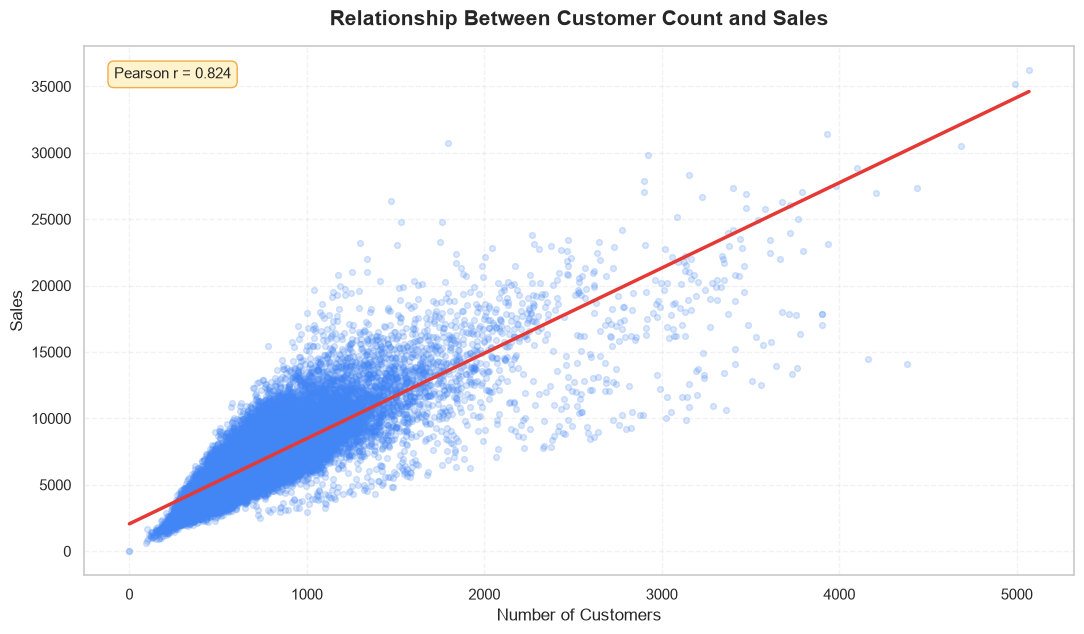


SALES BY CUSTOMER-COUNT GROUP


,Customer_Group,Record_Count,Min_Customers,Max_Customers,Mean_Customers,Mean_Sales,Median_Sales
0,"(-0.001, 408.0]","84,797",0,408,334.78,"3,405.55","3,375.00"
1,"(408.0, 486.0]","84,323",409,486,449.66,"4,598.26","4,533.00"
2,"(486.0, 550.0]","85,460",487,550,519.31,"5,228.13","5,130.00"
3,"(550.0, 611.0]","83,816",551,611,580.97,"5,751.11","5,620.00"
4,"(611.0, 676.0]","84,751",612,676,643.44,"6,274.88","6,135.00"
5,"(676.0, 748.0]","83,555",677,748,711.62,"6,819.03","6,659.00"
6,"(748.0, 838.0]","84,484",749,838,791.68,"7,432.41","7,228.00"
7,"(838.0, 960.0]","84,618",839,960,895.08,"8,178.43","7,882.00"
8,"(960.0, 1177.0]","84,458",961,"1,177","1,054.70","9,326.43","9,017.00"
9,"(1177.0, 7388.0]","84,130","1,178","7,388","1,651.82","12,583.03","11,861.00"


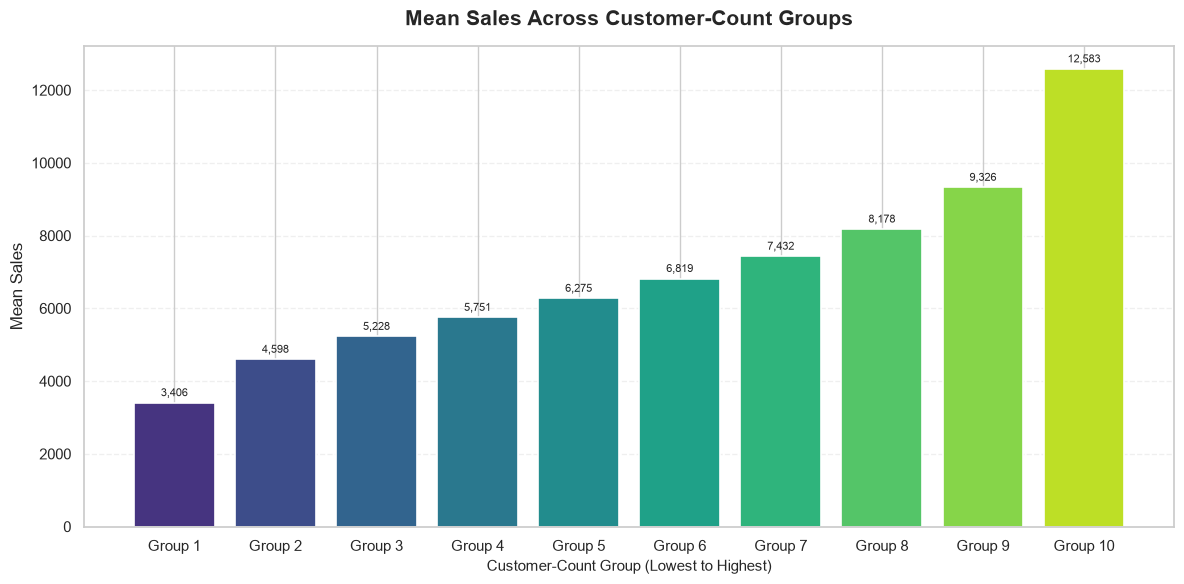

2026-10-31 09:23:18,412 | INFO | Project6_EDA | Section 18 completed. Pearson=0.8236, Spearman=0.8319, eligible_records=844392



Section 18 completed successfully.
Remember: correlation indicates association, not proof of causation.


In [220]:

# ============================================================
# RELATIONSHIP BETWEEN SALES AND CUSTOMERS
# ============================================================
# Objectives:
# 1. Prepare valid open-store records.
# 2. Calculate Pearson and Spearman correlations.
# 3. Visualize Sales versus Customers.
# 4. Compare mean sales across customer-count groups.
# 5. Log the analysis results.
# ============================================================

# STEP 1: Verify required columns
required_columns = ["Sales", "Customers", "Open"]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Create a separate analysis DataFrame
relationship_df = train_df[
    ["Sales", "Customers", "Open"]
].copy()

# Convert values to numeric format safely
for col in ["Sales", "Customers", "Open"]:
    relationship_df[col] = pd.to_numeric(
        relationship_df[col], errors="coerce"
    )

# Keep only open-store records with valid values
relationship_df = relationship_df.loc[
    relationship_df["Open"].eq(1)
    & relationship_df["Sales"].notna()
    & relationship_df["Customers"].notna()
].copy()

if len(relationship_df) < 2:
    raise ValueError(
        "Not enough valid records to calculate correlation."
    )

print("=" * 75)
print("SALES AND CUSTOMERS: DATA OVERVIEW")
print("=" * 75)

print(f"Eligible open-store records: {len(relationship_df):,}")
print(f"Mean Sales: {relationship_df['Sales'].mean():,.2f}")
print(f"Mean Customers: {relationship_df['Customers'].mean():,.2f}")

# STEP 3: Calculate Pearson and Spearman correlations
pearson_corr = relationship_df[
    ["Sales", "Customers"]
].corr(method="pearson").loc["Sales", "Customers"]

spearman_corr = relationship_df[
    ["Sales", "Customers"]
].corr(method="spearman").loc["Sales", "Customers"]

print("\n" + "=" * 75)
print("CORRELATION RESULTS")
print("=" * 75)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

# Descriptive interpretation of Pearson correlation
abs_corr = abs(pearson_corr)

if abs_corr < 0.20:
    strength = "very weak"
elif abs_corr < 0.40:
    strength = "weak"
elif abs_corr < 0.60:
    strength = "moderate"
elif abs_corr < 0.80:
    strength = "strong"
else:
    strength = "very strong"

if pearson_corr > 0:
    direction = "positive"
elif pearson_corr < 0:
    direction = "negative"
else:
    direction = "no linear"

print(
    f"Interpretation: {strength} {direction} "
    "linear association."
)

# STEP 4: Scatter plot with fitted trend line
# Use a fixed random_state so the sample is reproducible.
plot_sample = relationship_df.sample(
    n=min(25000, len(relationship_df)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(11, 6.5))

sns.regplot(
    data=plot_sample,
    x="Customers",
    y="Sales",
    scatter_kws={
        "alpha": 0.20,
        "s": 18,
        "color": "#4285F4"
    },
    line_kws={
        "color": "#E53935",
        "linewidth": 2.5
    },
    ci=None,
    ax=ax
)

ax.set_title(
    "Relationship Between Customer Count and Sales",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Customers", fontsize=12)
ax.set_ylabel("Sales", fontsize=12)

ax.text(
    0.03,
    0.96,
    f"Pearson r = {pearson_corr:.3f}",
    transform=ax.transAxes,
    va="top",
    fontsize=11,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "#FFF3CD",
        "edgecolor": "#F0AD4E"
    }
)

ax.grid(axis="both", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# STEP 5: Group observations by customer count
# qcut creates groups based on customer-count ranks.
# duplicates='drop' handles repeated quantile boundaries.
relationship_df["Customer_Group"] = pd.qcut(
    relationship_df["Customers"],
    q=10,
    duplicates="drop"
)

customer_group_summary = (
    relationship_df
    .groupby("Customer_Group", observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Min_Customers=("Customers", "min"),
        Max_Customers=("Customers", "max"),
        Mean_Customers=("Customers", "mean"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("SALES BY CUSTOMER-COUNT GROUP")
print("=" * 75)

display(
    customer_group_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Min_Customers": "{:,.0f}",
        "Max_Customers": "{:,.0f}",
        "Mean_Customers": "{:,.2f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales"],
        cmap="YlGnBu"
    )
)

# STEP 6: Visualize mean sales across customer groups
group_labels = [
    f"Group {i + 1}"
    for i in range(len(customer_group_summary))
]

group_colors = plt.cm.viridis(
    np.linspace(0.15, 0.90, len(customer_group_summary))
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    group_labels,
    customer_group_summary["Mean_Sales"],
    color=group_colors,
    edgecolor="white",
    linewidth=1.2
)

ax.set_title(
    "Mean Sales Across Customer-Count Groups",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Customer-Count Group (Lowest to Highest)",
    fontsize=11
)

ax.set_ylabel("Mean Sales", fontsize=12)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in customer_group_summary["Mean_Sales"]
    ],
    padding=3,
    fontsize=8
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# STEP 7: Log the results
logger.info(
    "Section 18 completed. Pearson=%.4f, Spearman=%.4f, "
    "eligible_records=%d",
    pearson_corr,
    spearman_corr,
    len(relationship_df)
)

print("\nSection 18 completed successfully.")
print(
    "Remember: correlation indicates association, "
    "not proof of causation."
)


### 19. **Key Insights — Relationship Between Sales and Customers**

**1. Strong Positive Correlation**

The Pearson correlation coefficient between Sales and Customers was **0.8236**, indicating a very strong positive linear association. The Spearman correlation coefficient was **0.8319**, also indicating a very strong positive association in the ranked observations.

**2. Customer Traffic and Sales**

The analysis included 844,392 valid open-store records. Mean sales were 6,955.51, while mean customer traffic was 762.73 customers per open-store record.

**3. Sales Across Customer-Count Groups**

Mean sales increased consistently across the ten customer-count groups. The lowest customer-count group recorded mean sales of 3,405.55, while the highest group recorded mean sales of 12,583.03. This pattern supports the observation that records with higher customer traffic generally have higher sales.

**4. Business Interpretation**

Customer traffic is an important variable to consider when developing a retail sales forecasting model. Customer counts may help explain sales variation and can be useful for understanding store performance.

**5. Limitations**

Correlation does not establish causation. Store size, product availability, promotions, weekdays, holidays, and seasonal effects may influence both sales and customer traffic. Customer counts may also be unavailable or unknown at the time a future forecast is generated, so their availability must be considered when designing the forecasting model.

**Conclusion:** Sales and customer counts show a very strong positive association in the observed training data. Customer traffic should be investigated further alongside calendar effects, promotions, and store characteristics.

### 20. **Weekday and Weekend Sales Behavior**

This section examines how retail sales and customer traffic vary across weekdays and weekends.

The analysis will:

1. Compare mean and median sales on weekdays and weekends.
2. Compare mean customer counts between the two groups.
3. Analyze mean sales and customer counts across individual days of the week.
4. Visualize daily and weekday-versus-weekend patterns using colorful charts.
5. Interpret the results while considering promotions, holidays, and store-level differences.

For this analysis, Monday through Friday will be classified as weekdays, while Saturday and Sunday will be classified as weekends. Only open-store records with valid dates, sales, and customer counts will be included.

The comparisons are descriptive and do not establish that the day of the week alone causes differences in sales.


WEEKDAY AND WEEKEND ANALYSIS
Valid open-store records: 844,392
Date range: 2013-01-01 to 2015-07-31

WEEKDAY VS WEEKEND SUMMARY


,Day_Type,Record_Count,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,Weekday,"696,741","7,172.41","6,559.00",780.43,694.00
1,Weekend,"147,651","5,932.02","5,442.00",679.19,576.00



Weekend vs weekday mean sales: -17.29%
Weekend vs weekday mean customers: -12.97%


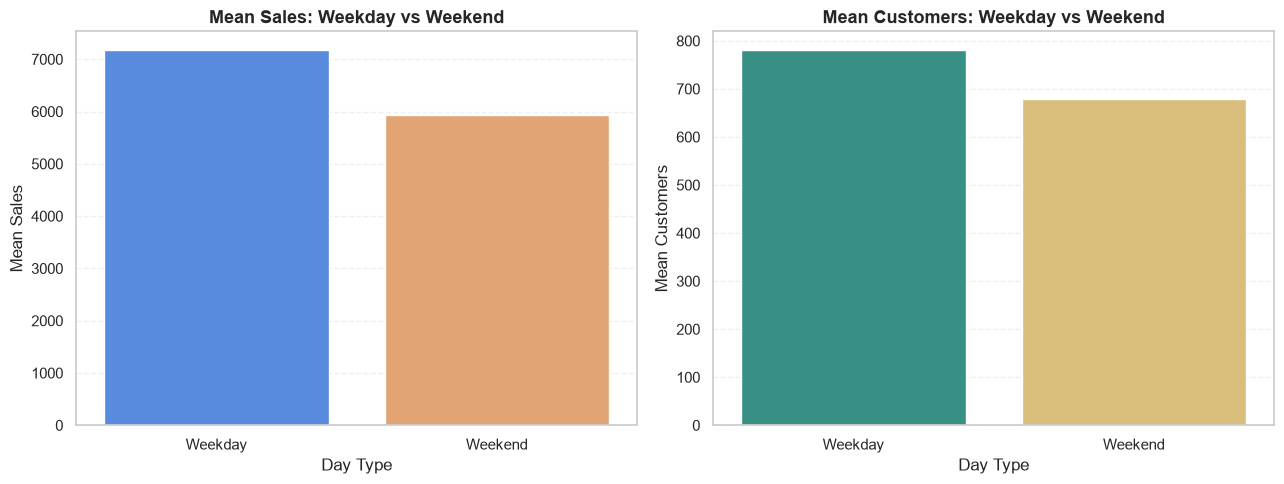


SUMMARY BY DAY OF WEEK


,Day_Name,Record_Count,Mean_Sales,Median_Sales,Mean_Customers
0,Monday,"137,560","8,216.07","7,539.00",855.44
1,Tuesday,"143,961","7,088.11","6,502.00",769.99
2,Wednesday,"141,936","6,728.12","6,210.00",740.60
3,Thursday,"134,644","6,767.31","6,246.00",755.57
4,Friday,"138,640","7,072.68","6,580.00",781.77
5,Saturday,"144,058","5,874.84","5,425.00",660.18
6,Sunday,"3,593","8,224.72","6,876.00","1,441.53"


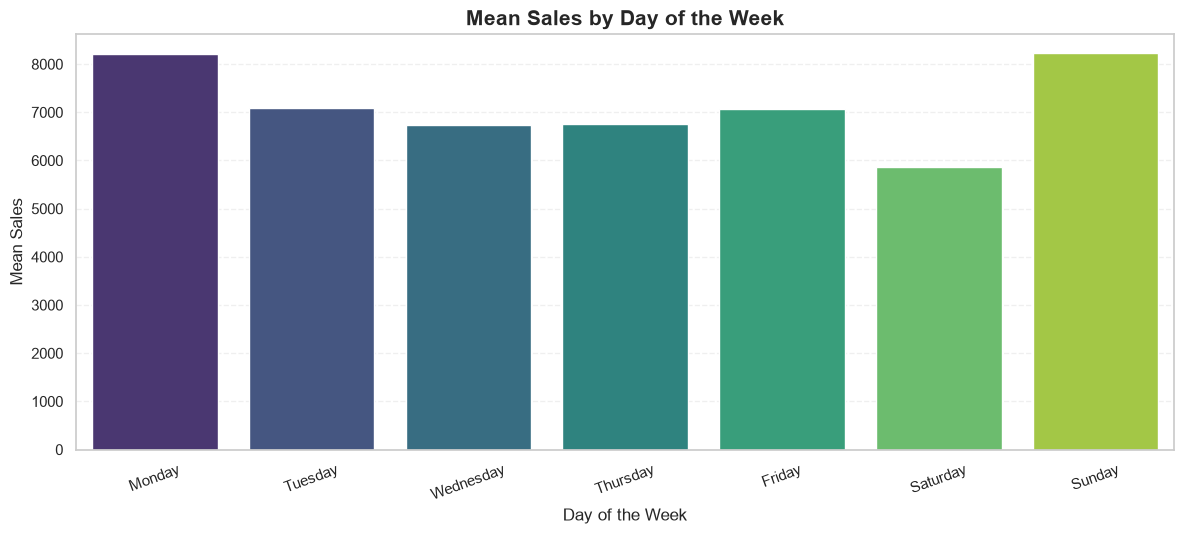

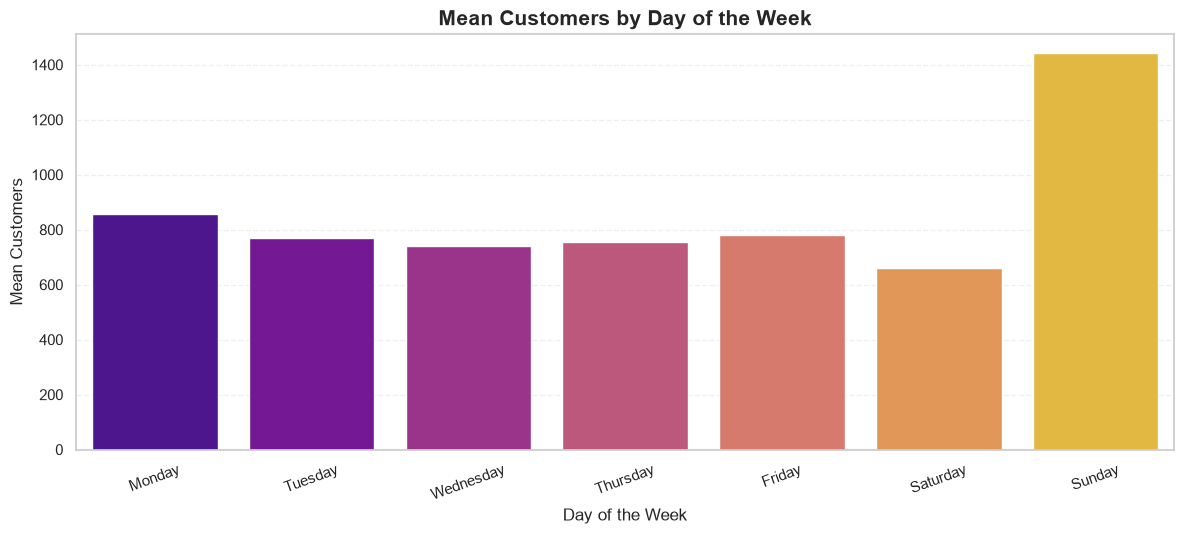

2026-10-31 09:23:19,440 | INFO | Project6_EDA | Section 20 completed: 844392 valid open-store records.



Section 20 analysis completed successfully.
Use the actual output tables to write the key insights.


In [221]:

# ============================================================
# WEEKDAY AND WEEKEND SALES BEHAVIOR
# Corrected and simplified version
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Check required columns
required_columns = ["Date", "Sales", "Customers", "Open"]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in train_df: {missing_columns}"
    )

# STEP 2: Prepare data
weekday_df = train_df[required_columns].copy()

weekday_df["Date"] = pd.to_datetime(
    weekday_df["Date"], errors="coerce"
)

for col in ["Sales", "Customers", "Open"]:
    weekday_df[col] = pd.to_numeric(
        weekday_df[col], errors="coerce"
    )

# Analyze open stores with valid sales and customer values
weekday_df = weekday_df.loc[
    (weekday_df["Open"] == 1)
    & weekday_df["Date"].notna()
    & weekday_df["Sales"].notna()
    & weekday_df["Customers"].notna()
].copy()

if weekday_df.empty:
    raise ValueError(
        "No valid open-store records found. Check train_df."
    )

# STEP 3: Derive weekday information from Date
day_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_df["Day_Number"] = weekday_df["Date"].dt.day_of_week
weekday_df["Day_Name"] = weekday_df["Date"].dt.day_name()

weekday_df["Day_Type"] = np.where(
    weekday_df["Day_Number"] < 5,
    "Weekday",
    "Weekend"
)

print("=" * 65)
print("WEEKDAY AND WEEKEND ANALYSIS")
print("=" * 65)
print(f"Valid open-store records: {len(weekday_df):,}")
print(f"Date range: {weekday_df['Date'].min().date()} to "
      f"{weekday_df['Date'].max().date()}")

# ============================================================
# PART A: WEEKDAY VS WEEKEND
# ============================================================

# STEP 4: Summary by day type
day_type_summary = (
    weekday_df.groupby("Day_Type")
    .agg(
        Record_Count=("Sales", "size"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reindex(["Weekday", "Weekend"])
    .reset_index()
)

print("\nWEEKDAY VS WEEKEND SUMMARY")

display(
    day_type_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

# STEP 5: Calculate percentage differences safely
summary_indexed = day_type_summary.set_index("Day_Type")

if {"Weekday", "Weekend"}.issubset(summary_indexed.index):
    weekday_sales = summary_indexed.loc["Weekday", "Mean_Sales"]
    weekend_sales = summary_indexed.loc["Weekend", "Mean_Sales"]

    weekday_customers = summary_indexed.loc[
        "Weekday", "Mean_Customers"
    ]
    weekend_customers = summary_indexed.loc[
        "Weekend", "Mean_Customers"
    ]

    sales_diff_pct = (
        (weekend_sales - weekday_sales) / weekday_sales * 100
        if weekday_sales != 0 else np.nan
    )

    customers_diff_pct = (
        (weekend_customers - weekday_customers)
        / weekday_customers * 100
        if weekday_customers != 0 else np.nan
    )

    print(f"\nWeekend vs weekday mean sales: {sales_diff_pct:+.2f}%")
    print(
        "Weekend vs weekday mean customers: "
        f"{customers_diff_pct:+.2f}%"
    )
else:
    print(
        "\nWarning: Both weekdays and weekends were not found. "
        "Check the date coverage."
    )

# STEP 6: Plot mean sales and customers by day type
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=day_type_summary,
    x="Day_Type",
    y="Mean_Sales",
    hue="Day_Type",
    palette=["#4285F4", "#F4A261"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Mean Sales: Weekday vs Weekend",
                  fontsize=13, fontweight="bold")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Mean Sales")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

sns.barplot(
    data=day_type_summary,
    x="Day_Type",
    y="Mean_Customers",
    hue="Day_Type",
    palette=["#2A9D8F", "#E9C46A"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Mean Customers: Weekday vs Weekend",
                  fontsize=13, fontweight="bold")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("Mean Customers")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# PART B: ANALYSIS BY INDIVIDUAL DAY
# ============================================================

# STEP 7: Summarize each day
daily_summary = (
    weekday_df.groupby("Day_Name")
    .agg(
        Record_Count=("Sales", "size"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean")
    )
    .reindex(day_names)
    .rename_axis("Day_Name")
    .reset_index()
)

print("\nSUMMARY BY DAY OF WEEK")

display(
    daily_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales"],
        cmap="YlOrRd"
    )
)

# STEP 8: Plot mean sales for each day
plt.figure(figsize=(12, 5.5))

sns.barplot(
    data=daily_summary,
    x="Day_Name",
    y="Mean_Sales",
    hue="Day_Name",
    palette="viridis",
    legend=False
)

plt.title("Mean Sales by Day of the Week",
          fontsize=15, fontweight="bold")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Sales")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 9: Plot mean customers for each day
plt.figure(figsize=(12, 5.5))

sns.barplot(
    data=daily_summary,
    x="Day_Name",
    y="Mean_Customers",
    hue="Day_Name",
    palette="plasma",
    legend=False
)

plt.title("Mean Customers by Day of the Week",
          fontsize=15, fontweight="bold")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Customers")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 10: Log completion, if the project logger exists
if "logger" in globals():
    logger.info(
        "Section 20 completed: %d valid open-store records.",
        len(weekday_df)
    )

print("\nSection 20 analysis completed successfully.")
print("Use the actual output tables to write the key insights.")


###  Key Insights — Weekday and Weekend Sales Behavior

**1. Weekday Versus Weekend Sales**

The analysis included 844,392 valid open-store records. Weekdays recorded mean sales of 7,172.41, compared with 5,932.02 on weekends. Weekend mean sales were approximately 17.29% lower than weekday mean sales.

**2. Customer Traffic**

Mean customer counts were 780.43 on weekdays and 679.19 on weekends. Weekend mean customer traffic was approximately 12.97% lower than weekday traffic.

**3. Differences Across Individual Days**

Monday recorded mean sales of 8,216.07, while Saturday recorded mean sales of 5,874.84. Sunday showed mean sales of 8,224.72, but this result was based on only 3,593 open-store records. Sunday also had a mean customer count of 1,441.53, substantially higher than the other days.

**4. Interpretation of Sunday Results**

The Sunday results should be interpreted cautiously because the number of open-store observations was much smaller than for the other days. The stores operating on Sundays may differ from the broader store population. Therefore, the Sunday average should not be treated as a typical result for all stores.

**5. Business Interpretation**

The observed results suggest that sales and customer traffic differ between weekdays and weekends. Retail planning could consider day-of-week patterns when forecasting demand and allocating staff or inventory. However, promotions, holidays, store operating schedules, and store characteristics may also affect these differences.

**Conclusion:** Weekdays showed higher average sales and customer traffic than weekends in the observed open-store records. Sunday results require additional caution because of the small number of observations. These findings can help guide further store-level analysis.

### 21. **All-Weekday-Open Stores and Their Weekend Sales Behavior**

This section identifies stores that remained open on every observed weekday (Monday to Friday) during the training period.

The analysis will:

1. Identify stores that were open on every observed Monday-to-Friday record.
2. Compare their weekend opening frequency with other stores.
3. Compare weekend Sales and Customers between the two store groups.
4. Examine the number of stores and observations included in each group.
5. Visualize the differences in weekend retail performance.

Only valid open-store observations with available Sales and Customers will be used to calculate weekend performance.

**Important:** A store is classified as all-weekday-open only when its Open indicator equals 1 on every observed Monday-to-Friday record in the training period. This is a strict definition and may exclude stores closed on weekdays due to holidays or other reasons.

The analysis is descriptive and does not establish that weekday opening patterns cause differences in weekend Sales.

ALL-WEEKDAY-OPEN STORES AND WEEKEND SALES ANALYSIS

Total stores evaluated: 1,115
Stores open on every observed weekday: 10
Other stores: 1,105

WEEKEND PERFORMANCE COMPARISON


,Store_Group,Unique_Stores,Total_Weekend_Records,Weekend_Open_Records,Mean_Weekend_Sales,Mean_Weekend_Customers,Weekend_Open_Rate_Percent
0,All-Weekday-Open,10,"2,680","2,680","11,627.11","2,215.32",100.00%
1,Not-All-Weekday-Open,"1,105","286,780","144,971","5,826.74",650.79,50.55%



Weekend Sales difference (All-Weekday-Open vs Other Stores): +99.55%


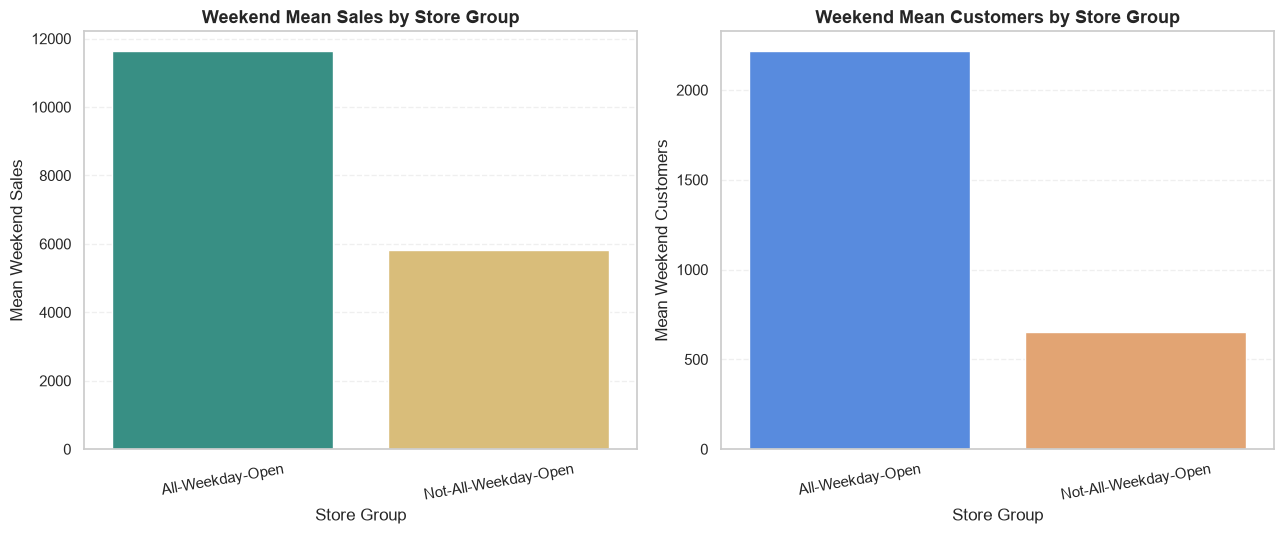

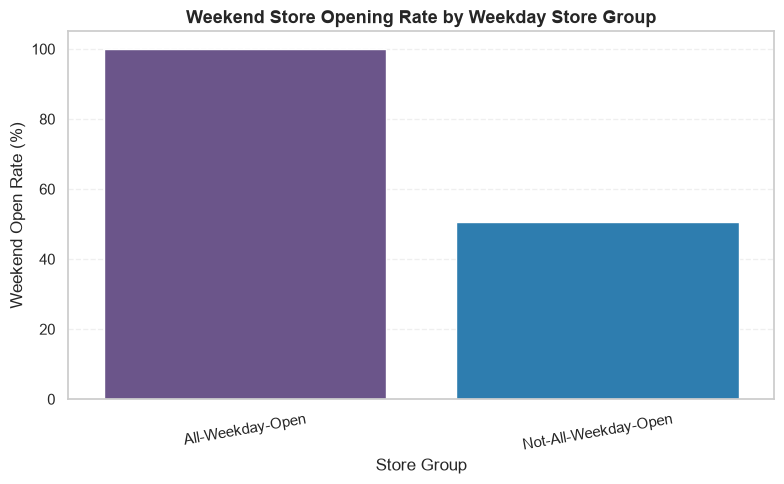

2026-10-31 09:23:20,131 | INFO | Project6_EDA | All-weekday-open store analysis completed. Stores evaluated=1115.



All-weekday-open store analysis completed successfully.
Interpret the results as descriptive comparisons, not causal effects.


In [222]:

# ============================================================
# ALL-WEEKDAY-OPEN STORES AND WEEKEND SALES ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Validate required columns
required_columns = [
    "Store", "Date", "DayOfWeek",
    "Open", "Sales", "Customers"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# STEP 2: Prepare a separate analysis DataFrame
weekday_store_df = train_df[required_columns].copy()

weekday_store_df["Date"] = pd.to_datetime(
    weekday_store_df["Date"],
    errors="coerce"
)

for col in ["Open", "Sales", "Customers", "DayOfWeek"]:
    weekday_store_df[col] = pd.to_numeric(
        weekday_store_df[col],
        errors="coerce"
    )

weekday_store_df = weekday_store_df.dropna(
    subset=["Store", "Date", "DayOfWeek", "Open"]
).copy()

# Derive weekday from actual date:
# Monday = 0, Tuesday = 1, ..., Sunday = 6
weekday_store_df["Day_Number"] = (
    weekday_store_df["Date"].dt.day_of_week
)

# STEP 3: Separate weekdays and weekends
weekday_records = weekday_store_df.loc[
    weekday_store_df["Day_Number"].between(0, 4)
].copy()

weekend_records = weekday_store_df.loc[
    weekday_store_df["Day_Number"].isin([5, 6])
].copy()

# STEP 4: Identify stores open on every observed weekday
weekday_store_summary = (
    weekday_records
    .groupby("Store")
    .agg(
        Observed_Weekday_Records=("Open", "size"),
        Weekday_Open_Records=("Open", lambda x: x.eq(1).sum())
    )
    .reset_index()
)

weekday_store_summary["Weekday_Open_Rate"] = (
    weekday_store_summary["Weekday_Open_Records"]
    / weekday_store_summary["Observed_Weekday_Records"]
)

# Strict definition: 100% weekday opening rate
weekday_store_summary["Store_Group"] = np.where(
    weekday_store_summary["Weekday_Open_Rate"].eq(1),
    "All-Weekday-Open",
    "Not-All-Weekday-Open"
)

# STEP 5: Attach store groups to weekend records
weekend_analysis = weekend_records.merge(
    weekday_store_summary[
        ["Store", "Store_Group"]
    ],
    on="Store",
    how="inner",
    validate="many_to_one"
)

# STEP 6: Calculate weekend performance
# Opening rate uses all weekend records.
# Sales and Customers averages use open weekend records only.

weekend_summary = (
    weekend_analysis
    .groupby("Store_Group")
    .agg(
        Unique_Stores=("Store", "nunique"),
        Total_Weekend_Records=("Store", "size"),
        Weekend_Open_Records=("Open", lambda x: x.eq(1).sum()),
        Mean_Weekend_Sales=(
            "Sales",
            lambda x: x[
                weekend_analysis.loc[x.index, "Open"].eq(1)
            ].mean()
        ),
        Mean_Weekend_Customers=(
            "Customers",
            lambda x: x[
                weekend_analysis.loc[x.index, "Open"].eq(1)
            ].mean()
        )
    )
    .reset_index()
)

weekend_summary["Weekend_Open_Rate_Percent"] = (
    weekend_summary["Weekend_Open_Records"]
    / weekend_summary["Total_Weekend_Records"]
    * 100
)

print("=" * 80)
print("ALL-WEEKDAY-OPEN STORES AND WEEKEND SALES ANALYSIS")
print("=" * 80)

print(
    f"\nTotal stores evaluated: "
    f"{weekday_store_summary['Store'].nunique():,}"
)

print(
    "Stores open on every observed weekday: "
    f"{(weekday_store_summary['Store_Group'] == 'All-Weekday-Open').sum():,}"
)

print(
    "Other stores: "
    f"{(weekday_store_summary['Store_Group'] == 'Not-All-Weekday-Open').sum():,}"
)

print("\nWEEKEND PERFORMANCE COMPARISON")

display(
    weekend_summary.style.format({
        "Unique_Stores": "{:,.0f}",
        "Total_Weekend_Records": "{:,.0f}",
        "Weekend_Open_Records": "{:,.0f}",
        "Mean_Weekend_Sales": "{:,.2f}",
        "Mean_Weekend_Customers": "{:,.2f}",
        "Weekend_Open_Rate_Percent": "{:.2f}%"
    }).background_gradient(
        subset=[
            "Mean_Weekend_Sales",
            "Mean_Weekend_Customers"
        ],
        cmap="YlGnBu"
    )
)

# STEP 7: Calculate percentage difference in weekend Sales
sales_comparison = weekend_summary.set_index("Store_Group")

if (
    "All-Weekday-Open" in sales_comparison.index
    and "Not-All-Weekday-Open" in sales_comparison.index
):
    all_weekday_sales = sales_comparison.loc[
        "All-Weekday-Open", "Mean_Weekend_Sales"
    ]

    other_sales = sales_comparison.loc[
        "Not-All-Weekday-Open", "Mean_Weekend_Sales"
    ]

    if pd.notna(other_sales) and other_sales != 0:
        weekend_sales_difference = (
            (all_weekday_sales - other_sales)
            / other_sales
        ) * 100

        print(
            "\nWeekend Sales difference "
            "(All-Weekday-Open vs Other Stores): "
            f"{weekend_sales_difference:+.2f}%"
        )
    else:
        print("\nWeekend Sales percentage comparison is unavailable.")

else:
    print(
        "\nBoth store groups are required for a weekend Sales comparison."
    )

# STEP 8: Visualize weekend Sales and Customers
plot_data = weekend_summary.melt(
    id_vars="Store_Group",
    value_vars=[
        "Mean_Weekend_Sales",
        "Mean_Weekend_Customers"
    ],
    var_name="Metric",
    value_name="Average_Value"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.barplot(
    data=weekend_summary,
    x="Store_Group",
    y="Mean_Weekend_Sales",
    hue="Store_Group",
    palette=["#2A9D8F", "#E9C46A"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Weekend Mean Sales by Store Group",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Store Group")
axes[0].set_ylabel("Mean Weekend Sales")
axes[0].tick_params(axis="x", rotation=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

sns.barplot(
    data=weekend_summary,
    x="Store_Group",
    y="Mean_Weekend_Customers",
    hue="Store_Group",
    palette=["#4285F4", "#F4A261"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Weekend Mean Customers by Store Group",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Store Group")
axes[1].set_ylabel("Mean Weekend Customers")
axes[1].tick_params(axis="x", rotation=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 9: Visualize weekend opening rates
plt.figure(figsize=(8, 5))

sns.barplot(
    data=weekend_summary,
    x="Store_Group",
    y="Weekend_Open_Rate_Percent",
    hue="Store_Group",
    palette=["#6A4C93", "#1982C4"],
    legend=False
)

plt.title(
    "Weekend Store Opening Rate by Weekday Store Group",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Store Group")
plt.ylabel("Weekend Open Rate (%)")
plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 10: Log completion
if "logger" in globals():
    logger.info(
        "All-weekday-open store analysis completed. "
        "Stores evaluated=%d.",
        weekday_store_summary["Store"].nunique()
    )

print("\nAll-weekday-open store analysis completed successfully.")
print(
    "Interpret the results as descriptive comparisons, "
    "not causal effects."
)


### 22. Key Insights — All-Weekday-Open Stores and Weekend Sales Behavior

**1. Identification of All-Weekday-Open Stores**

- A total of **1,115 stores** were evaluated.
- Only **10 stores** remained open on every observed Monday-to-Friday record.
- The remaining **1,105 stores** did not meet this strict all-weekday-open definition.

**2. Weekend Sales Comparison**

- All-Weekday-Open stores recorded mean weekend Sales of **11,627.11**.
- Not-All-Weekday-Open stores recorded mean weekend Sales of **5,826.74**.
- The all-weekday-open group showed approximately **99.55% higher mean weekend Sales** than the other group.

**3. Weekend Customer Traffic**

- All-Weekday-Open stores recorded mean weekend Customers of **2,215.32**.
- Not-All-Weekday-Open stores recorded mean weekend Customers of **650.79**.
- The all-weekday-open group had approximately **240.40% higher mean weekend customer traffic**.

**4. Weekend Store Opening Rate**

- All-Weekday-Open stores had a weekend opening rate of **100.00%**.
- Not-All-Weekday-Open stores had a weekend opening rate of **50.55%**.

This indicates a substantial difference in weekend operating patterns between the two groups.

**5. Business Interpretation**

Stores that remained consistently open during observed weekdays also showed higher average weekend Sales and customer traffic. This pattern suggests that store operating schedules may be relevant when examining weekend retail performance.

**6. Limitations**

- Only 10 stores qualified as all-weekday-open, so the results should be interpreted cautiously.
- The comparison groups differ considerably in size.
- Weekend Sales and Customers averages were calculated using open-store observations only.
- Other factors, including Store Type, Assortment, promotions, holidays, and location, may influence the observed differences.
- The analysis is descriptive and does not establish that weekday opening causes higher weekend Sales.

**Conclusion:** The 10 all-weekday-open stores recorded approximately 99.55% higher mean weekend Sales and 240.40% higher mean weekend customer traffic compared with the other stores. However, the small group size and differences in operating patterns limit generalization. These findings provide useful context for further store-level and weekend demand analysis.

### 23. **Sales by Store Type and Assortment**

This section examines sales and customer traffic across different store types and assortment levels.

The analysis will:

1. Compare mean and median sales across store types.
2. Compare mean customer counts across store types.
3. Analyze sales across assortment levels.
4. Examine the combined relationship between Store Type and Assortment.
5. Visualize the results using colorful charts and summary tables.

Only open-store records with valid sales and customer values will be included. Store type and assortment categories will be taken from the merged training dataset.

These comparisons are descriptive. Differences may also reflect store size, location, promotions, holidays, and operating patterns.

STORE TYPE AND ASSORTMENT ANALYSIS
Eligible open-store records: 844,392
Unique stores: 1,115

STORE TYPE SUMMARY


,StoreType,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,a,"457,077",602,"6,925.17","6,285.00",795.36,720.00
1,b,"15,563",17,"10,231.41","9,130.00","2,021.82","1,839.00"
2,c,"112,978",148,"6,932.51","6,407.00",815.47,756.00
3,d,"258,774",348,"6,822.14","6,395.00",606.34,577.00


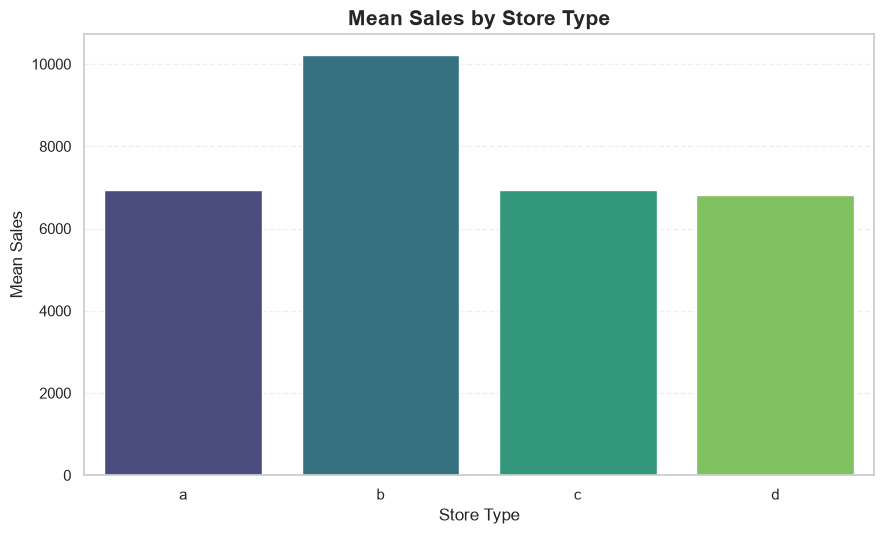

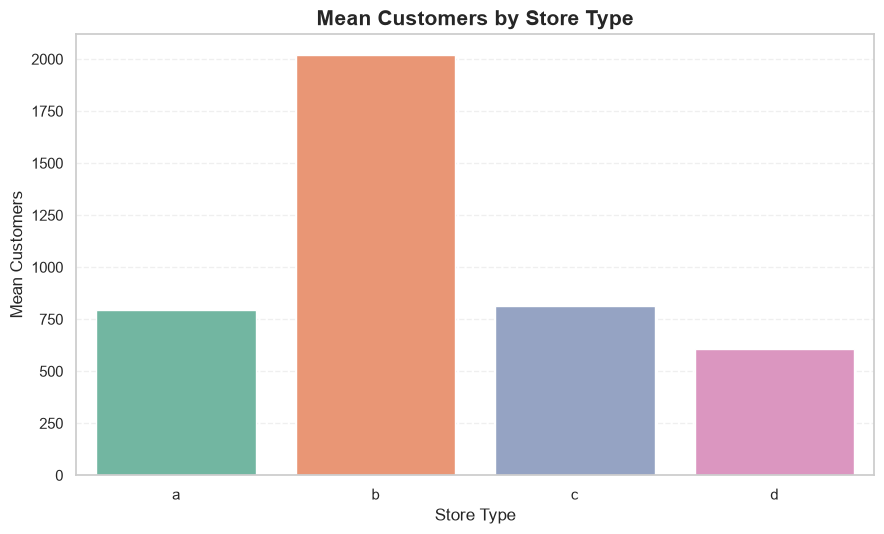


ASSORTMENT SUMMARY


,Assortment,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,a,"444,909",593,"6,621.02","6,082.00",747.94,673.00
1,b,"8,212",9,"8,639.35","8,081.00","2,066.80","1,894.00"
2,c,"391,271",513,"7,300.53","6,675.00",752.17,672.00


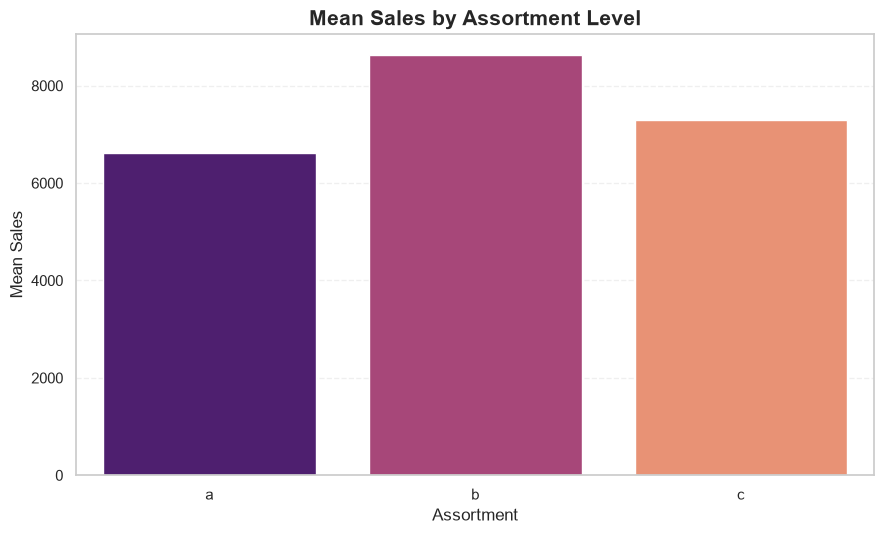


STORE TYPE × ASSORTMENT SUMMARY


,StoreType,Assortment,Record_Count,Unique_Stores,Mean_Sales,Mean_Customers
0,a,a,"286,053",381,"6,537.62",759.24
1,a,c,"171,024",221,"7,573.38",855.77
2,b,a,"6,409",7,"11,133.99","1,804.98"
3,b,b,"8,212",9,"8,639.35","2,066.80"
4,b,c,942,1,"17,969.56","3,105.05"
5,c,a,"58,561",77,"6,834.93",839.86
6,c,c,"54,417",71,"7,037.53",789.21
7,d,a,"93,886",128,"6,433.62",584.02
8,d,c,"164,888",220,"7,043.36",619.05


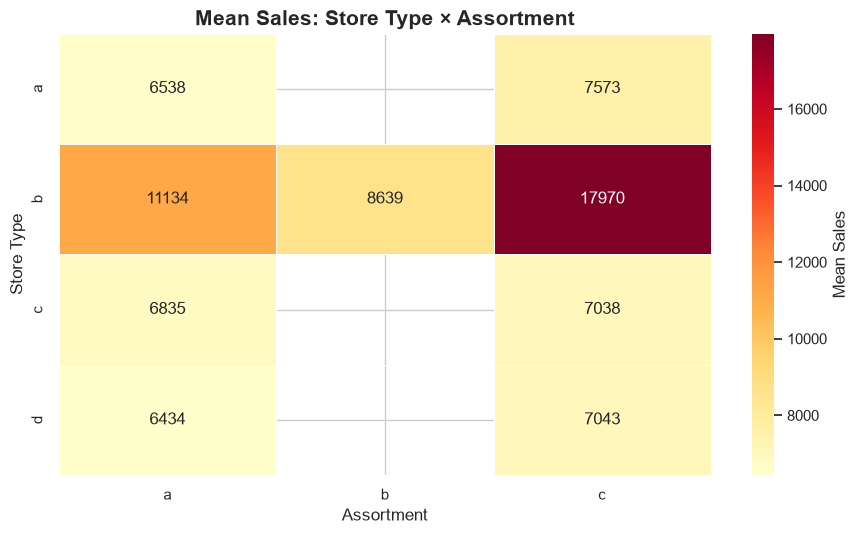

2026-10-31 09:23:21,297 | INFO | Project6_EDA | Section 23 completed. Eligible records=844392; unique stores=1115.



Section 23 completed successfully.
Interpret results using the displayed tables and charts.


In [223]:

# ============================================================
# SALES BY STORE TYPE AND ASSORTMENT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Verify required columns
required_columns = [
    "Store", "StoreType", "Assortment",
    "Sales", "Customers", "Open"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns in train_df: "
        f"{missing_columns}. Check the merged dataset."
    )

# STEP 2: Prepare analysis data
store_analysis_df = train_df[required_columns].copy()

for col in ["Sales", "Customers", "Open"]:
    store_analysis_df[col] = pd.to_numeric(
        store_analysis_df[col], errors="coerce"
    )

# Keep valid observations from open stores
store_analysis_df = store_analysis_df.loc[
    store_analysis_df["Open"].eq(1)
    & store_analysis_df["Sales"].notna()
    & store_analysis_df["Customers"].notna()
    & store_analysis_df["StoreType"].notna()
    & store_analysis_df["Assortment"].notna()
].copy()

if store_analysis_df.empty:
    raise ValueError(
        "No valid records remain for Store Type and Assortment analysis."
    )

print("=" * 75)
print("STORE TYPE AND ASSORTMENT ANALYSIS")
print("=" * 75)

print(f"Eligible open-store records: {len(store_analysis_df):,}")
print(f"Unique stores: {store_analysis_df['Store'].nunique():,}")

# STEP 3: Summary by Store Type
store_type_summary = (
    store_analysis_df
    .groupby("StoreType", observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reset_index()
    .sort_values("StoreType")
)

print("\nSTORE TYPE SUMMARY")

display(
    store_type_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

# STEP 4: Plot mean sales by Store Type
plt.figure(figsize=(9, 5.5))

sns.barplot(
    data=store_type_summary,
    x="StoreType",
    y="Mean_Sales",
    hue="StoreType",
    palette="viridis",
    legend=False
)

plt.title(
    "Mean Sales by Store Type",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Store Type")
plt.ylabel("Mean Sales")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 5: Plot mean customers by Store Type
plt.figure(figsize=(9, 5.5))

sns.barplot(
    data=store_type_summary,
    x="StoreType",
    y="Mean_Customers",
    hue="StoreType",
    palette="Set2",
    legend=False
)

plt.title(
    "Mean Customers by Store Type",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Store Type")
plt.ylabel("Mean Customers")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 6: Summary by Assortment
assortment_summary = (
    store_analysis_df
    .groupby("Assortment", observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reset_index()
    .sort_values("Assortment")
)

print("\nASSORTMENT SUMMARY")

display(
    assortment_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlOrRd"
    )
)

# STEP 7: Plot mean sales by Assortment
plt.figure(figsize=(9, 5.5))

sns.barplot(
    data=assortment_summary,
    x="Assortment",
    y="Mean_Sales",
    hue="Assortment",
    palette="magma",
    legend=False
)

plt.title(
    "Mean Sales by Assortment Level",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Assortment")
plt.ylabel("Mean Sales")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 8: Compare Store Type and Assortment together
combined_summary = (
    store_analysis_df
    .groupby(
        ["StoreType", "Assortment"],
        observed=True
    )
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Mean_Customers=("Customers", "mean")
    )
    .reset_index()
)

print("\nSTORE TYPE × ASSORTMENT SUMMARY")

display(
    combined_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales"],
        cmap="YlGnBu"
    )
)

# STEP 9: Heatmap of mean sales
sales_pivot = combined_summary.pivot(
    index="StoreType",
    columns="Assortment",
    values="Mean_Sales"
)

plt.figure(figsize=(9, 5.5))

sns.heatmap(
    sales_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Mean Sales"}
)

plt.title(
    "Mean Sales: Store Type × Assortment",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Assortment")
plt.ylabel("Store Type")
plt.tight_layout()
plt.show()

# STEP 10: Log completion if logger is available
if "logger" in globals():
    logger.info(
        "Section 23 completed. Eligible records=%d; unique stores=%d.",
        len(store_analysis_df),
        store_analysis_df["Store"].nunique()
    )

print("\nSection 23 completed successfully.")
print("Interpret results using the displayed tables and charts.")


###  Key Insights — Sales by Store Type and Assortment

**1. Sales Across Store Types**

- Store Type B recorded the highest mean sales at 10,231.41, followed by Store Type C at 6,932.51, Store Type A at 6,925.17, and Store Type D at 6,822.14.
- Store Type B also had the highest mean customer count at 2,021.82.
- Store Type B represented only 17 stores and 15,563 open-store records, compared with 602 stores for Type A. Its high average should therefore be interpreted in light of the smaller group size.

**2. Sales Across Assortment Levels**

- Assortment C recorded the highest mean sales among the assortment groups with broad store coverage, at 7,300.53.
- Assortment A recorded mean sales of 6,621.02.
- Assortment B recorded mean sales of 8,639.35 and the highest mean customer count at 2,066.80, but it represented only nine stores. This small group limits generalization.

**3. Combined Store Type and Assortment Patterns**

- The Store Type B and Assortment C combination recorded mean sales of 17,969.56, but it represented only one store. This result must not be generalized to all stores of that type.
- Store Type A with Assortment C recorded mean sales of 7,573.38 across 221 stores.
- Store Type D with Assortment C recorded mean sales of 7,043.36 across 220 stores.

**4. Business Interpretation**

The observed averages differ across store types and assortment categories. These differences suggest that store characteristics should be considered when analyzing retail performance and developing sales forecasts.

**5. Limitations**

The analysis uses open-store daily records, so stores with more eligible records contribute more observations to the overall averages. Some store-type and assortment combinations have very few stores. The results are descriptive and do not establish that store type or assortment alone causes higher sales.

**Conclusion:** Store Type B and Assortment B have high observed mean sales, but both represent relatively small groups. Results from combinations with broad store coverage provide a more reliable basis for further investigation.


### 24. **Competition Distance and Its Relationship with Sales**

This section examines the relationship between the distance to the nearest competitor and average store Sales.

The analysis includes:

1. Calculating store-level average Sales.
2. Measuring Pearson and Spearman correlations between CompetitionDistance and average Sales.
3. Comparing average Sales across competition-distance groups.
4. Identifying stores with missing competition-distance information.
5. Visualizing the relationship between competitor distance and store performance.

Only valid open-store observations with available CompetitionDistance information will be considered for the correlation and distance-group comparisons.

The findings are descriptive and do not establish a causal relationship between competitor distance and Sales.


COMPETITION DISTANCE AND SALES ANALYSIS
Total stores analyzed: 1,115
Stores with missing distance: 3
Stores with valid distance: 1,112

CORRELATION RESULTS
----------------------------------------------------------------------
Pearson correlation:  -0.0424
Spearman correlation: -0.0280

SALES BY COMPETITION DISTANCE GROUP
----------------------------------------------------------------------


,Distance_Group,Store_Count,Mean_Competition_Distance,Mean_Sales,Median_Sales
0,Nearest,278,319.93,7331.50,6707.26
1,Second,278,1471.26,6881.74,6357.90
2,Third,278,4073.53,6698.75,6486.33
3,Farthest,278,15754.89,6841.75,6686.74


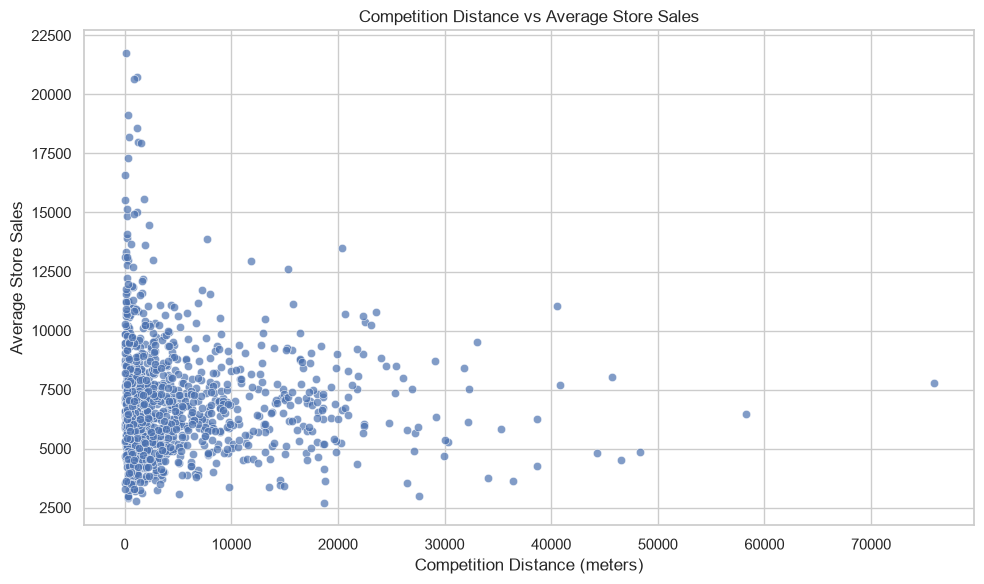

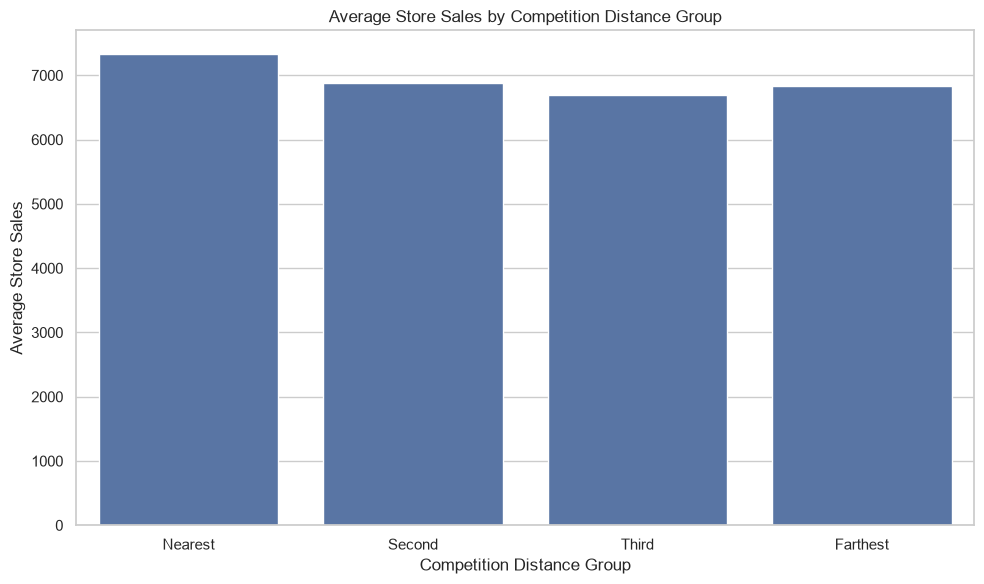

2026-10-31 09:23:21,731 | INFO | Project6_EDA | Section 24 completed. Stores=1115, valid_distance_stores=1112, Pearson=-0.0424, Spearman=-0.0280



Section 24 analysis completed successfully.
Correlation indicates association, not causation.


In [224]:

# ============================================================
# SECTION 24: COMPETITION DISTANCE AND SALES ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Check required columns

required_columns = [
    "Store", "Sales", "Open", "CompetitionDistance"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# STEP 2: Prepare analysis data

distance_df = train_df[required_columns].copy()

for col in ["Sales", "Open", "CompetitionDistance"]:
    distance_df[col] = pd.to_numeric(
        distance_df[col], errors="coerce"
    )

# STEP 3: Keep valid open-store observations

distance_df = distance_df[
    (distance_df["Open"] == 1) &
    (distance_df["Sales"].notna())
].copy()

# STEP 4: Calculate store-level average Sales
# CompetitionDistance is store-level metadata.
# Therefore, calculate one average Sales value per store.

store_distance_df = (
    distance_df.groupby("Store")
    .agg(
        Average_Sales=("Sales", "mean"),
        CompetitionDistance=("CompetitionDistance", "first")
    )
    .reset_index()
)

# STEP 5: Separate missing and available distances

missing_distance_count = (
    store_distance_df["CompetitionDistance"].isna().sum()
)

valid_distance_df = store_distance_df.dropna(
    subset=["CompetitionDistance", "Average_Sales"]
).copy()

print("=" * 70)
print("COMPETITION DISTANCE AND SALES ANALYSIS")
print("=" * 70)

print(f"Total stores analyzed: {len(store_distance_df):,}")
print(f"Stores with missing distance: {missing_distance_count:,}")
print(f"Stores with valid distance: {len(valid_distance_df):,}")

# STEP 6: Calculate correlations

pearson_corr = valid_distance_df[
    "CompetitionDistance"
].corr(valid_distance_df["Average_Sales"], method="pearson")

spearman_corr = valid_distance_df[
    "CompetitionDistance"
].corr(valid_distance_df["Average_Sales"], method="spearman")

print("\nCORRELATION RESULTS")
print("-" * 70)
print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

# STEP 7: Create competition-distance groups

valid_distance_df["Distance_Group"] = pd.qcut(
    valid_distance_df["CompetitionDistance"],
    q=4,
    labels=[
        "Nearest",
        "Second",
        "Third",
        "Farthest"
    ],
    duplicates="drop"
)

distance_summary = (
    valid_distance_df.groupby(
        "Distance_Group",
        observed=False
    )
    .agg(
        Store_Count=("Store", "nunique"),
        Mean_Competition_Distance=(
            "CompetitionDistance", "mean"
        ),
        Mean_Sales=("Average_Sales", "mean"),
        Median_Sales=("Average_Sales", "median")
    )
    .reset_index()
)

print("\nSALES BY COMPETITION DISTANCE GROUP")
print("-" * 70)
display(distance_summary.round(2))

# STEP 8: Visualize competition distance vs average Sales

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=valid_distance_df,
    x="CompetitionDistance",
    y="Average_Sales",
    alpha=0.7
)

plt.title(
    "Competition Distance vs Average Store Sales"
)
plt.xlabel("Competition Distance (meters)")
plt.ylabel("Average Store Sales")
plt.tight_layout()
plt.show()

# STEP 9: Visualize Sales across distance groups

plt.figure(figsize=(10, 6))

sns.barplot(
    data=distance_summary,
    x="Distance_Group",
    y="Mean_Sales"
)

plt.title("Average Store Sales by Competition Distance Group")
plt.xlabel("Competition Distance Group")
plt.ylabel("Average Store Sales")
plt.tight_layout()
plt.show()

# STEP 10: Log results

if "logger" in globals():
    logger.info(
        "Section 24 completed. Stores=%d, "
        "valid_distance_stores=%d, Pearson=%.4f, Spearman=%.4f",
        len(store_distance_df),
        len(valid_distance_df),
        pearson_corr,
        spearman_corr
    )

print("\nSection 24 analysis completed successfully.")
print("Correlation indicates association, not causation.")



### Key Insights — Competition Distance and Sales Analysis

**1. Availability of Competition Distance Information**

- A total of 1,115 stores were analyzed.
- CompetitionDistance information was available for 1,112 stores.
- Only 3 stores had missing CompetitionDistance values.

**2. Very Weak Negative Correlation**

- Pearson correlation between CompetitionDistance and average Sales was -0.0424.
- Spearman correlation was -0.0280.
- Both values indicate a very weak negative association between competitor distance and average store Sales.

**3. Sales Across Competition Distance Groups**

- Stores in the Nearest group recorded the highest average Sales of 7,331.50.
- The Second group recorded average Sales of 6,881.74.
- The Third group recorded the lowest average Sales of 6,698.75.
- The Farthest group recorded average Sales of 6,841.75.

**4. No Clear Increasing or Decreasing Sales Pattern**

- Average Sales did not increase consistently as CompetitionDistance increased.
- Although the Nearest group had the highest average Sales, the Farthest group did not have the lowest average Sales.
- This suggests that competitor distance alone does not explain differences in store performance.

**5. Interpretation of the Visualizations**

- The scatter plot helps visualize the relationship between CompetitionDistance and average Sales across stores.
- The distance-group bar chart shows differences in average Sales across the four competitor-distance groups.
- The overall relationship appears weak, indicating that other factors may also influence store Sales.

**Conclusion:**

CompetitionDistance has a very weak negative association with average store Sales in this dataset. The distance-group comparison also shows no consistent trend between competitor distance and Sales. Therefore, competitor distance alone may not be a strong indicator of store performance. These findings are descriptive and do not establish a causal relationship.


### 25. **Missing-to-Available Competition Distance Analysis**

This section investigates whether any store initially had missing competition-distance information but later had a valid competition-distance value in the training dataset.
The analysis will:

1. Identify stores with missing CompetitionDistance values.
2. Examine whether the same stores have valid distance values on later dates.
3. Compare the earliest and latest available records for each store.
4. Identify stores showing a missing-to-available transition, if any.
5. Summarize the findings using a store-level table.

**Important Data Consideration:**

CompetitionDistance is store-level metadata in the Rossmann dataset and is generally repeated across daily records for each store. Therefore, missing values should be examined at the store level rather than interpreted automatically as a competitor opening event.

A missing-to-available transition, if found, indicates a change in data availability. It does not by itself prove that a new competitor opened or that an existing competitor reopened.

**Limitation:** The dataset does not provide a dated history of competitor-distance updates or separate competitor reopening events. Consequently, this analysis can identify changes in recorded data availability but cannot establish the actual date of a competitor opening or reopening.

**Objective:** Determine whether any stores have a missing-to-available CompetitionDistance pattern and document the result transparently.

In [225]:

# ============================================================
# MISSING-TO-AVAILABLE COMPETITION DISTANCE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# STEP 1: Verify required columns

required_columns = [
    "Store",
    "Date",
    "CompetitionDistance"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Prepare a copy of required data

competition_history = train_df[
    required_columns
].copy()

competition_history["Date"] = pd.to_datetime(
    competition_history["Date"],
    errors="coerce"
)

competition_history["CompetitionDistance"] = pd.to_numeric(
    competition_history["CompetitionDistance"],
    errors="coerce"
)

competition_history = competition_history.dropna(
    subset=["Store", "Date"]
)

competition_history = competition_history.sort_values(
    ["Store", "Date"]
)

# STEP 3: Analyze competition distance history store-wise

store_history = (
    competition_history
    .groupby("Store")
    .agg(
        Total_Records=("CompetitionDistance", "size"),
        Missing_Records=(
            "CompetitionDistance",
            lambda x: x.isna().sum()
        ),
        Available_Records=(
            "CompetitionDistance",
            lambda x: x.notna().sum()
        ),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max")
    )
    .reset_index()
)

# STEP 4: Identify first and last valid distance dates

first_valid_dates = (
    competition_history
    .dropna(subset=["CompetitionDistance"])
    .groupby("Store")
    .first()
    .reset_index()[["Store", "Date", "CompetitionDistance"]]
    .rename(columns={
        "Date": "First_Valid_Date",
        "CompetitionDistance": "First_Valid_Distance"
    })
)

last_valid_dates = (
    competition_history
    .dropna(subset=["CompetitionDistance"])
    .groupby("Store")
    .last()
    .reset_index()[["Store", "Date", "CompetitionDistance"]]
    .rename(columns={
        "Date": "Last_Valid_Date",
        "CompetitionDistance": "Last_Valid_Distance"
    })
)

store_history = store_history.merge(
    first_valid_dates,
    on="Store",
    how="left"
)

store_history = store_history.merge(
    last_valid_dates,
    on="Store",
    how="left"
)

# STEP 5: Identify missing-to-available transitions

store_history["Missing_To_Available"] = (
    store_history["Missing_Records"].gt(0)
    & store_history["Available_Records"].gt(0)
    & store_history["First_Valid_Date"].gt(
        store_history["First_Date"]
    )
)

transition_stores = store_history.loc[
    store_history["Missing_To_Available"]
].copy()

# STEP 6: Display overall data availability

print("=" * 75)
print("MISSING-TO-AVAILABLE COMPETITION DISTANCE ANALYSIS")
print("=" * 75)

print(
    f"Total stores analyzed: "
    f"{store_history['Store'].nunique():,}"
)

print(
    f"Stores with completely missing distance: "
    f"{(store_history['Available_Records'] == 0).sum():,}"
)

print(
    f"Stores with available distance records: "
    f"{(store_history['Available_Records'] > 0).sum():,}"
)

print(
    f"Stores with missing-to-available transition: "
    f"{len(transition_stores):,}"
)

# STEP 7: Display transition details

print("\n" + "=" * 75)
print("STORES WITH MISSING-TO-AVAILABLE TRANSITIONS")
print("=" * 75)

if not transition_stores.empty:

    display(
        transition_stores[
            [
                "Store",
                "Total_Records",
                "Missing_Records",
                "Available_Records",
                "First_Date",
                "First_Valid_Date",
                "First_Valid_Distance",
                "Last_Valid_Date",
                "Last_Valid_Distance"
            ]
        ].style.format({
            "Total_Records": "{:,.0f}",
            "Missing_Records": "{:,.0f}",
            "Available_Records": "{:,.0f}",
            "First_Valid_Distance": "{:,.2f}",
            "Last_Valid_Distance": "{:,.2f}"
        })
    )

else:

    print(
        "No missing-to-available transition was identified "
        "in the training dataset."
    )

# STEP 8: Display stores with completely missing distance

completely_missing_stores = store_history.loc[
    store_history["Available_Records"] == 0,
    ["Store", "Total_Records", "Missing_Records"]
]

print("\n" + "=" * 75)
print("STORES WITH COMPLETELY MISSING COMPETITION DISTANCE")
print("=" * 75)

display(completely_missing_stores)

# STEP 9: Log the analysis

if "logger" in globals():

    logger.info(
        "Missing-to-Available Competition Distance Analysis completed. "
        "Total stores=%d; Transition stores=%d.",
        len(store_history),
        len(transition_stores)
    )

print("\nSection 25 analysis completed.")
print(
    "Note: A change in recorded data availability does not prove "
    "that a competitor opened or reopened."
)


MISSING-TO-AVAILABLE COMPETITION DISTANCE ANALYSIS
Total stores analyzed: 1,115
Stores with completely missing distance: 3
Stores with available distance records: 1,112
Stores with missing-to-available transition: 0

STORES WITH MISSING-TO-AVAILABLE TRANSITIONS
No missing-to-available transition was identified in the training dataset.

STORES WITH COMPLETELY MISSING COMPETITION DISTANCE


,Store,Total_Records,Missing_Records
290,291,942,942
621,622,942,942
878,879,758,758


2026-10-31 09:23:21,991 | INFO | Project6_EDA | Missing-to-Available Competition Distance Analysis completed. Total stores=1115; Transition stores=0.



Section 25 analysis completed.
Note: A change in recorded data availability does not prove that a competitor opened or reopened.



### Key Insights: Missing-to-Available Competition Distance Analysis

1. A total of 1,115 stores were analyzed to examine the availability of CompetitionDistance information over time.

2. CompetitionDistance information was available for 1,112 stores, while 3 stores had completely missing values throughout their recorded observations.

3. The three stores with completely missing CompetitionDistance information were Store 291, Store 622, and Store 879.

4. No store showed a missing-to-available transition in the training dataset. This indicates that no store had missing CompetitionDistance records followed by valid distance records during the observed period.

5. The missing values appear to be consistent at the store level rather than changing over time in the available training records.

6. The results do not provide evidence of a competitor opening or reopening event. Missing CompetitionDistance information should not be interpreted as proof that a competitor was absent.

**Conclusion:**

CompetitionDistance was consistently available for most stores. Only three stores had completely missing information, and no missing-to-available transition was observed. These missing values should be handled carefully during the data preprocessing stage.


### 26. **Competitor Opening Analysis**

This section investigates how store-level sales and customer traffic differ before and after the recorded opening of a nearby competitor.

The analysis will:

1. Identify stores with valid competitor opening month and year.
2. Construct the competitor opening date for each store.
3. Compare store performance during the 12 months before and 12 months after the recorded opening date.
4. Calculate store-level mean sales and customer counts for both periods.
5. Visualize the observed differences.

Only stores with sufficient training observations in both comparison periods will be included in the paired analysis.

**Dataset limitation:** The available Rossmann dataset contains competitor opening month and year information but does not provide a separate competitor reopening date or reopening event. Therefore, this section analyzes recorded competitor openings only.

The results are descriptive and cannot establish that competitor openings caused changes in sales.

COMPETITOR OPENING DATA CHECK
Total stores in metadata: 1,115
Stores with valid competitor opening date: 761
Stores without valid opening date: 354

PAIRED STORE COMPARISON
Stores with observations in both periods: 188


,Opening_Phase,Mean_Store_Sales,Mean_Store_Customers
0,Before Opening,"7,466.30",803.87
1,After Opening,"7,137.26",764.33



Observed changes after competitor opening:
Mean store sales change: -4.41%
Mean store customer change: -4.92%


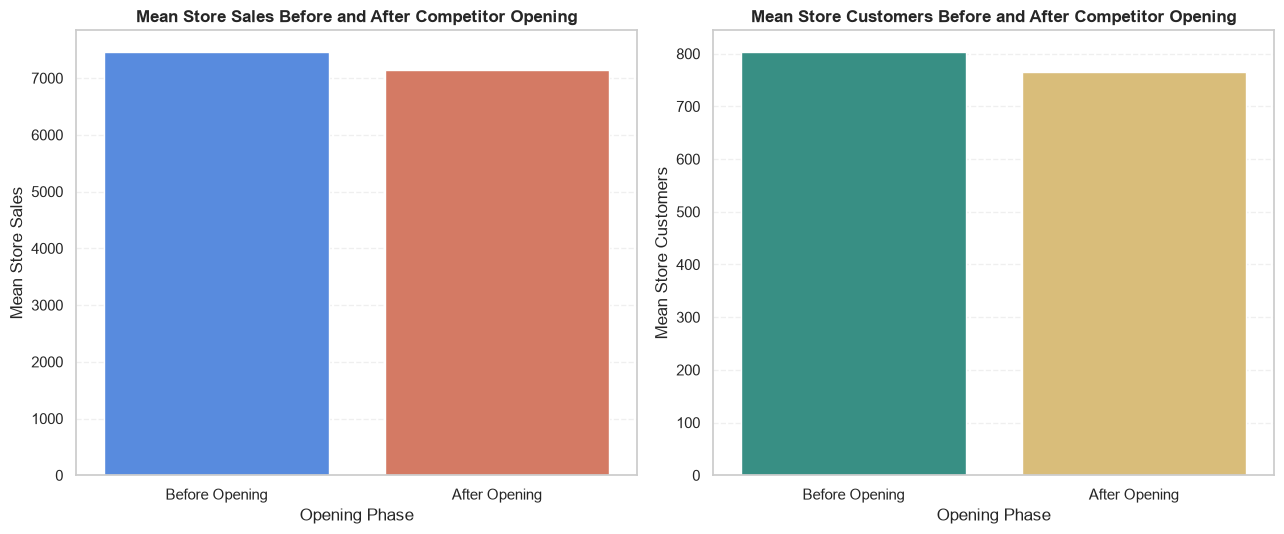

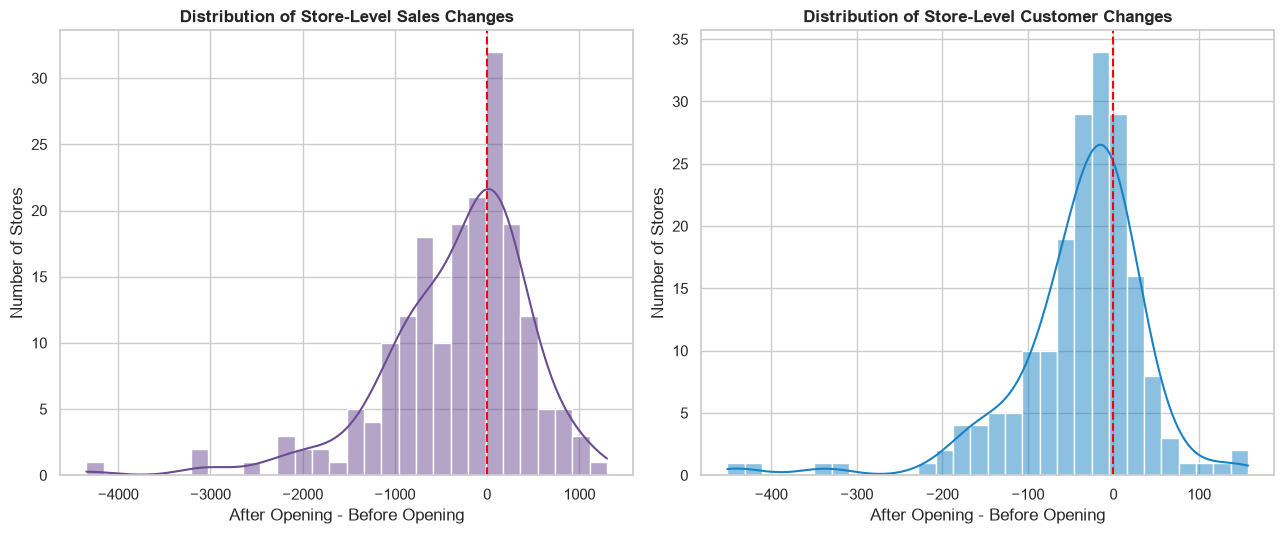

2026-10-31 09:23:22,966 | INFO | Project6_EDA | Section 26 completed. Paired stores=188; sales change=-4.41%; customer change=-4.92%.



Section 26 competitor opening analysis completed.
Note: The dataset does not provide a separate competitor reopening date.


In [226]:

# ============================================================
# COMPETITOR OPENING ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Verify required columns
required_columns = [
    "Store",
    "Date",
    "Sales",
    "Customers",
    "Open",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# STEP 2: Create a separate analysis DataFrame
opening_df = train_df[required_columns].copy()

opening_df["Date"] = pd.to_datetime(
    opening_df["Date"], errors="coerce"
)

numeric_columns = [
    "Sales",
    "Customers",
    "Open",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear"
]

for col in numeric_columns:
    opening_df[col] = pd.to_numeric(
        opening_df[col], errors="coerce"
    )

# STEP 3: Create one competitor opening date per store
store_metadata = (
    opening_df[
        [
            "Store",
            "CompetitionOpenSinceMonth",
            "CompetitionOpenSinceYear"
        ]
    ]
    .drop_duplicates()
)

# Ensure each store has consistent opening metadata
metadata_counts = (
    store_metadata.groupby("Store")
    .size()
)

if (metadata_counts > 1).any():
    raise ValueError(
        "Inconsistent competitor opening metadata found "
        "for one or more stores."
    )

# Keep only valid month and year values
valid_metadata = store_metadata.loc[
    store_metadata["CompetitionOpenSinceMonth"].between(1, 12)
    & store_metadata["CompetitionOpenSinceYear"].notna()
    & (store_metadata["CompetitionOpenSinceYear"] > 0)
].copy()

# Construct competitor opening date
valid_metadata["Competition_Open_Date"] = pd.to_datetime(
    {
        "year": valid_metadata[
            "CompetitionOpenSinceYear"
        ].astype(int),
        "month": valid_metadata[
            "CompetitionOpenSinceMonth"
        ].astype(int),
        "day": 1
    },
    errors="coerce"
)

valid_metadata = valid_metadata.dropna(
    subset=["Competition_Open_Date"]
)

print("=" * 75)
print("COMPETITOR OPENING DATA CHECK")
print("=" * 75)

print(f"Total stores in metadata: {store_metadata['Store'].nunique():,}")
print(
    "Stores with valid competitor opening date: "
    f"{valid_metadata['Store'].nunique():,}"
)
print(
    "Stores without valid opening date: "
    f"{store_metadata['Store'].nunique() - valid_metadata['Store'].nunique():,}"
)

# STEP 4: Merge opening date with daily training data
opening_df = opening_df.merge(
    valid_metadata[
        ["Store", "Competition_Open_Date"]
    ],
    on="Store",
    how="inner",
    validate="many_to_one"
)

# Keep valid open-store observations
opening_df = opening_df.loc[
    opening_df["Open"].eq(1)
    & opening_df["Date"].notna()
    & opening_df["Sales"].notna()
    & opening_df["Customers"].notna()
].copy()

# STEP 5: Define 12-month before and after windows
# Before: opening date minus 12 months up to the day before opening.
# After: opening date through the following 12 months.
opening_df["Before_Start"] = (
    opening_df["Competition_Open_Date"]
    - pd.DateOffset(months=12)
)

opening_df["After_End"] = (
    opening_df["Competition_Open_Date"]
    + pd.DateOffset(months=12)
)

before_mask = (
    (opening_df["Date"] >= opening_df["Before_Start"])
    & (opening_df["Date"] < opening_df["Competition_Open_Date"])
)

after_mask = (
    (opening_df["Date"] >= opening_df["Competition_Open_Date"])
    & (opening_df["Date"] < opening_df["After_End"])
)

opening_df["Opening_Phase"] = np.select(
    [before_mask, after_mask],
    ["Before Opening", "After Opening"],
    default="Outside Comparison Window"
)

comparison_df = opening_df.loc[
    opening_df["Opening_Phase"].isin(
        ["Before Opening", "After Opening"]
    )
].copy()

# STEP 6: Calculate store-level performance by phase
store_phase_summary = (
    comparison_df
    .groupby(["Store", "Opening_Phase"])
    .agg(
        Record_Count=("Sales", "size"),
        Mean_Sales=("Sales", "mean"),
        Mean_Customers=("Customers", "mean")
    )
    .reset_index()
)

# Require both periods for a fair paired comparison
sales_pivot = store_phase_summary.pivot(
    index="Store",
    columns="Opening_Phase",
    values="Mean_Sales"
)

customers_pivot = store_phase_summary.pivot(
    index="Store",
    columns="Opening_Phase",
    values="Mean_Customers"
)

required_phases = ["Before Opening", "After Opening"]

paired_stores = (
    sales_pivot.dropna(subset=required_phases).index
    .intersection(
        customers_pivot.dropna(subset=required_phases).index
    )
)

if len(paired_stores) == 0:
    raise ValueError(
        "No stores have valid observations in both periods. "
        "The 12-month comparison window may need adjustment."
    )

# Calculate paired store-level differences
paired_results = pd.DataFrame(index=paired_stores)

paired_results["Sales_Before"] = sales_pivot.loc[
    paired_stores, "Before Opening"
]

paired_results["Sales_After"] = sales_pivot.loc[
    paired_stores, "After Opening"
]

paired_results["Customers_Before"] = customers_pivot.loc[
    paired_stores, "Before Opening"
]

paired_results["Customers_After"] = customers_pivot.loc[
    paired_stores, "After Opening"
]

paired_results["Sales_Difference"] = (
    paired_results["Sales_After"]
    - paired_results["Sales_Before"]
)

paired_results["Customers_Difference"] = (
    paired_results["Customers_After"]
    - paired_results["Customers_Before"]
)

print("\n" + "=" * 75)
print("PAIRED STORE COMPARISON")
print("=" * 75)

print(
    "Stores with observations in both periods: "
    f"{len(paired_results):,}"
)

# STEP 7: Overall paired-store summary
phase_summary = pd.DataFrame({
    "Opening_Phase": [
        "Before Opening",
        "After Opening"
    ],
    "Mean_Store_Sales": [
        paired_results["Sales_Before"].mean(),
        paired_results["Sales_After"].mean()
    ],
    "Mean_Store_Customers": [
        paired_results["Customers_Before"].mean(),
        paired_results["Customers_After"].mean()
    ]
})

display(
    phase_summary.style.format({
        "Mean_Store_Sales": "{:,.2f}",
        "Mean_Store_Customers": "{:,.2f}"
    }).background_gradient(
        subset=[
            "Mean_Store_Sales",
            "Mean_Store_Customers"
        ],
        cmap="YlGnBu"
    )
)

# STEP 8: Calculate percentage differences
before_sales = paired_results["Sales_Before"].mean()
after_sales = paired_results["Sales_After"].mean()

before_customers = paired_results["Customers_Before"].mean()
after_customers = paired_results["Customers_After"].mean()

sales_change_pct = (
    (after_sales - before_sales) / before_sales * 100
    if before_sales != 0 else np.nan
)

customers_change_pct = (
    (after_customers - before_customers)
    / before_customers * 100
    if before_customers != 0 else np.nan
)

print("\nObserved changes after competitor opening:")
print(f"Mean store sales change: {sales_change_pct:+.2f}%")
print(
    "Mean store customer change: "
    f"{customers_change_pct:+.2f}%"
)

# STEP 9: Visualize mean store sales before and after
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.barplot(
    data=phase_summary,
    x="Opening_Phase",
    y="Mean_Store_Sales",
    hue="Opening_Phase",
    palette=["#4285F4", "#E76F51"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Mean Store Sales Before and After Competitor Opening",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("Opening Phase")
axes[0].set_ylabel("Mean Store Sales")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

sns.barplot(
    data=phase_summary,
    x="Opening_Phase",
    y="Mean_Store_Customers",
    hue="Opening_Phase",
    palette=["#2A9D8F", "#E9C46A"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Mean Store Customers Before and After Competitor Opening",
    fontsize=12,
    fontweight="bold"
)
axes[1].set_xlabel("Opening Phase")
axes[1].set_ylabel("Mean Store Customers")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 10: Visualize store-level paired differences
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.histplot(
    paired_results["Sales_Difference"],
    bins=30,
    kde=True,
    color="#6A4C93",
    ax=axes[0]
)

axes[0].axvline(
    0, color="red", linestyle="--", linewidth=1.5
)

axes[0].set_title(
    "Distribution of Store-Level Sales Changes",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("After Opening - Before Opening")
axes[0].set_ylabel("Number of Stores")

sns.histplot(
    paired_results["Customers_Difference"],
    bins=30,
    kde=True,
    color="#1982C4",
    ax=axes[1]
)

axes[1].axvline(
    0, color="red", linestyle="--", linewidth=1.5
)

axes[1].set_title(
    "Distribution of Store-Level Customer Changes",
    fontsize=12,
    fontweight="bold"
)
axes[1].set_xlabel("After Opening - Before Opening")
axes[1].set_ylabel("Number of Stores")

plt.tight_layout()
plt.show()

# STEP 11: Log completion
if "logger" in globals():
    logger.info(
        "Section 26 completed. Paired stores=%d; "
        "sales change=%.2f%%; customer change=%.2f%%.",
        len(paired_results),
        sales_change_pct,
        customers_change_pct
    )

print("\nSection 26 competitor opening analysis completed.")
print(
    "Note: The dataset does not provide a separate "
    "competitor reopening date."
)


### Key Insights — Competitor Opening Analysis

**1. Availability of Competitor Opening Information**

Out of 1,115 stores, 761 had valid competitor opening month and year information. The remaining 354 stores did not have valid opening-date information and were excluded from this analysis.

**2. Paired Store Coverage**

Only 188 stores had valid open-store observations in both the 12-month period before and the 12-month period after the recorded competitor opening date. Therefore, the comparison represents a subset of stores rather than the entire dataset.

**3. Change in Mean Store Sales**

Mean store-level sales decreased from 7,466.30 before the recorded competitor opening to 7,137.26 afterward. This represents an observed decrease of approximately 4.41%.

**4. Change in Mean Customer Traffic**

Mean customer counts decreased from 803.87 before the recorded competitor opening to 764.33 afterward. This represents an observed decrease of approximately 4.92%.

**5. Business Interpretation**

The paired-store comparison shows lower average sales and customer traffic in the observed period after the recorded competitor opening. This pattern may be consistent with increased competition, but other factors such as seasonality, promotions, holidays, economic conditions, and store-level changes may also explain the difference.

**6. Limitations**

The competitor opening information contains only month and year, so the first day of each month was used as an approximate opening date. In addition, only 188 stores had observations in both comparison windows. The dataset does not contain a separate competitor reopening date. Therefore, the analysis cannot establish a causal effect of competitor openings or analyze competitor reopenings.

**Conclusion:** The observed paired-store results show a 4.41% decrease in mean sales and a 4.92% decrease in mean customer traffic after the recorded competitor opening date. These findings are exploratory and should be interpreted cautiously because of limited store coverage and approximate opening dates.

### 27. **Store-Level Promotion Effectiveness**

This section evaluates promotion effectiveness at the individual store level.

The analysis will:

1. Calculate mean sales and customer counts for each store during promotional and non-promotional periods.
2. Identify stores with valid observations in both conditions.
3. Calculate store-level sales and customer percentage uplift during promotions.
4. Summarize the average and median promotion uplift across stores.
5. Visualize promotion effectiveness and differences between stores.

Only open-store records with valid sales, customer counts, and promotion information will be included. Stores must have observations under both promotional and non-promotional conditions for the paired comparison.

The results are descriptive and do not establish that promotions alone caused changes in sales.

STORE-LEVEL PROMOTION EFFECTIVENESS
Eligible open-store records: 844,392
Unique stores: 1,115

PAIRED STORE COVERAGE
Stores with both promotional and non-promotional records: 1,115

PAIRED STORE PERFORMANCE SUMMARY


,Condition,Mean_Store_Sales,Mean_Store_Customers
0,Without Promotion,"5,906.57",686.90
1,With Promotion,"8,205.18",838.29



STORE-LEVEL PROMOTION UPLIFT SUMMARY


,Metric,Mean_Uplift_Percent,Median_Uplift_Percent,Stores_With_Positive_Uplift
0,Sales Uplift (%),+41.43%,+40.56%,"1,114"
1,Customer Uplift (%),+23.84%,+22.66%,"1,101"


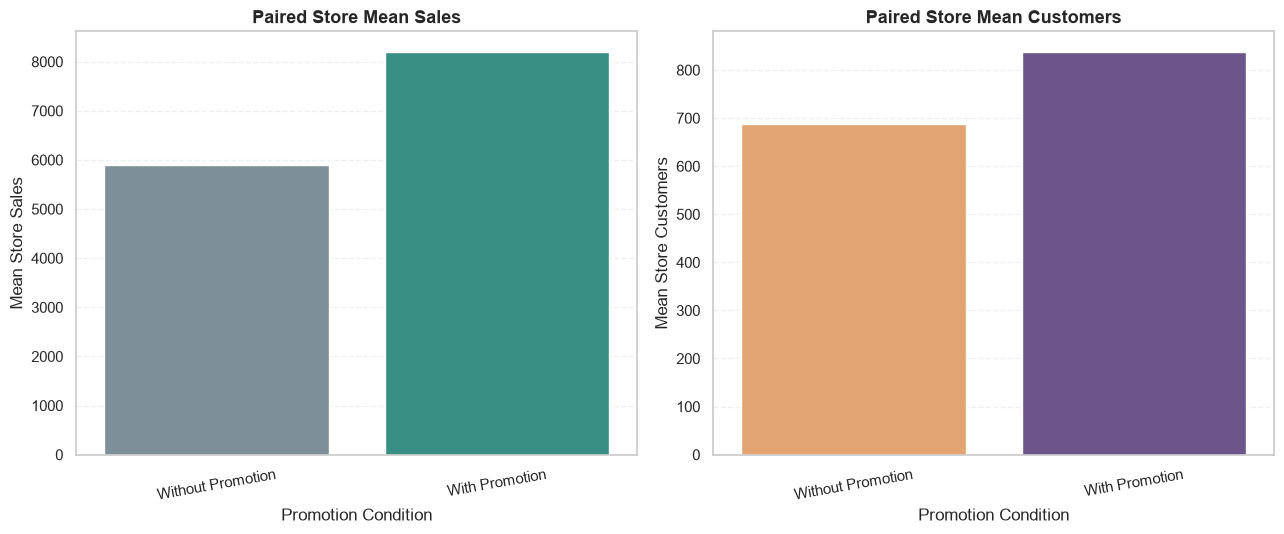

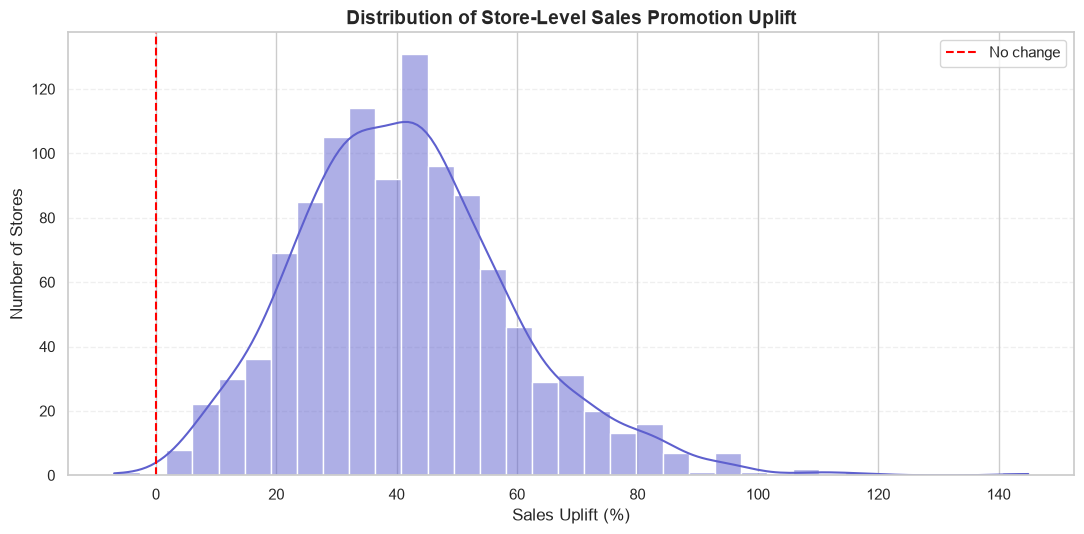

2026-10-31 09:23:23,615 | INFO | Project6_EDA | Section 27 completed. Paired stores=1115; mean sales uplift=41.43%; mean customer uplift=23.84%.



Section 27 completed successfully.
Interpret promotion uplift as an observed association, not a proven causal effect.


In [227]:

# ============================================================
# STORE-LEVEL PROMOTION EFFECTIVENESS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# STEP 1: Verify required columns
required_columns = [
    "Store", "Sales", "Customers", "Open", "Promo"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# STEP 2: Prepare analysis data
promo_store_df = train_df[required_columns].copy()

for col in ["Sales", "Customers", "Open", "Promo"]:
    promo_store_df[col] = pd.to_numeric(
        promo_store_df[col], errors="coerce"
    )

# Keep valid open-store observations
promo_store_df = promo_store_df.loc[
    promo_store_df["Open"].eq(1)
    & promo_store_df["Sales"].notna()
    & promo_store_df["Customers"].notna()
    & promo_store_df["Promo"].isin([0, 1])
].copy()

if promo_store_df.empty:
    raise ValueError(
        "No valid records available for promotion analysis."
    )

print("=" * 75)
print("STORE-LEVEL PROMOTION EFFECTIVENESS")
print("=" * 75)

print(f"Eligible open-store records: {len(promo_store_df):,}")
print(f"Unique stores: {promo_store_df['Store'].nunique():,}")

# STEP 3: Calculate store-level averages
store_promo_summary = (
    promo_store_df
    .groupby(["Store", "Promo"])
    .agg(
        Record_Count=("Sales", "size"),
        Mean_Sales=("Sales", "mean"),
        Mean_Customers=("Customers", "mean")
    )
    .reset_index()
)

# STEP 4: Convert store-level results into paired columns
sales_pivot = store_promo_summary.pivot(
    index="Store",
    columns="Promo",
    values="Mean_Sales"
)

customers_pivot = store_promo_summary.pivot(
    index="Store",
    columns="Promo",
    values="Mean_Customers"
)

# Keep stores with both Promo=0 and Promo=1 observations
paired_stores = (
    sales_pivot.dropna(subset=[0, 1]).index
    .intersection(
        customers_pivot.dropna(subset=[0, 1]).index
    )
)

if len(paired_stores) == 0:
    raise ValueError(
        "No stores have observations in both promotion conditions."
    )

# STEP 5: Create paired store-level comparison
store_uplift = pd.DataFrame(index=paired_stores)

store_uplift["Sales_No_Promo"] = sales_pivot.loc[
    paired_stores, 0
]

store_uplift["Sales_With_Promo"] = sales_pivot.loc[
    paired_stores, 1
]

store_uplift["Customers_No_Promo"] = customers_pivot.loc[
    paired_stores, 0
]

store_uplift["Customers_With_Promo"] = customers_pivot.loc[
    paired_stores, 1
]

# Calculate absolute differences
store_uplift["Sales_Difference"] = (
    store_uplift["Sales_With_Promo"]
    - store_uplift["Sales_No_Promo"]
)

store_uplift["Customers_Difference"] = (
    store_uplift["Customers_With_Promo"]
    - store_uplift["Customers_No_Promo"]
)

# Calculate percentage uplift for each store
# Avoid division by zero
store_uplift["Sales_Uplift_Percent"] = np.where(
    store_uplift["Sales_No_Promo"] > 0,
    (
        store_uplift["Sales_Difference"]
        / store_uplift["Sales_No_Promo"]
    ) * 100,
    np.nan
)

store_uplift["Customers_Uplift_Percent"] = np.where(
    store_uplift["Customers_No_Promo"] > 0,
    (
        store_uplift["Customers_Difference"]
        / store_uplift["Customers_No_Promo"]
    ) * 100,
    np.nan
)

print("\n" + "=" * 75)
print("PAIRED STORE COVERAGE")
print("=" * 75)

print(
    f"Stores with both promotional and non-promotional records: "
    f"{len(store_uplift):,}"
)

# STEP 6: Overall paired-store averages
overall_paired_summary = pd.DataFrame({
    "Condition": [
        "Without Promotion",
        "With Promotion"
    ],
    "Mean_Store_Sales": [
        store_uplift["Sales_No_Promo"].mean(),
        store_uplift["Sales_With_Promo"].mean()
    ],
    "Mean_Store_Customers": [
        store_uplift["Customers_No_Promo"].mean(),
        store_uplift["Customers_With_Promo"].mean()
    ]
})

print("\nPAIRED STORE PERFORMANCE SUMMARY")

display(
    overall_paired_summary.style.format({
        "Mean_Store_Sales": "{:,.2f}",
        "Mean_Store_Customers": "{:,.2f}"
    }).background_gradient(
        subset=[
            "Mean_Store_Sales",
            "Mean_Store_Customers"
        ],
        cmap="YlGnBu"
    )
)

# STEP 7: Summarize store-level uplift
uplift_summary = pd.DataFrame({
    "Metric": [
        "Sales Uplift (%)",
        "Customer Uplift (%)"
    ],
    "Mean_Uplift_Percent": [
        store_uplift["Sales_Uplift_Percent"].mean(),
        store_uplift["Customers_Uplift_Percent"].mean()
    ],
    "Median_Uplift_Percent": [
        store_uplift["Sales_Uplift_Percent"].median(),
        store_uplift["Customers_Uplift_Percent"].median()
    ],
    "Stores_With_Positive_Uplift": [
        (store_uplift["Sales_Uplift_Percent"] > 0).sum(),
        (store_uplift["Customers_Uplift_Percent"] > 0).sum()
    ]
})

print("\nSTORE-LEVEL PROMOTION UPLIFT SUMMARY")

display(
    uplift_summary.style.format({
        "Mean_Uplift_Percent": "{:+.2f}%",
        "Median_Uplift_Percent": "{:+.2f}%",
        "Stores_With_Positive_Uplift": "{:,.0f}"
    }).background_gradient(
        subset=["Mean_Uplift_Percent"],
        cmap="RdYlGn"
    )
)

# STEP 8: Visualize paired mean sales and customer counts
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.barplot(
    data=overall_paired_summary,
    x="Condition",
    y="Mean_Store_Sales",
    hue="Condition",
    palette=["#78909C", "#2A9D8F"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Paired Store Mean Sales",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Promotion Condition")
axes[0].set_ylabel("Mean Store Sales")
axes[0].tick_params(axis="x", rotation=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

sns.barplot(
    data=overall_paired_summary,
    x="Condition",
    y="Mean_Store_Customers",
    hue="Condition",
    palette=["#F4A261", "#6A4C93"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Paired Store Mean Customers",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Promotion Condition")
axes[1].set_ylabel("Mean Store Customers")
axes[1].tick_params(axis="x", rotation=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 9: Visualize distribution of store-level sales uplift
plt.figure(figsize=(11, 5.5))

sns.histplot(
    data=store_uplift,
    x="Sales_Uplift_Percent",
    bins=35,
    kde=True,
    color="#5E60CE"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="No change"
)

plt.title(
    "Distribution of Store-Level Sales Promotion Uplift",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sales Uplift (%)")
plt.ylabel("Number of Stores")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 10: Log results
if "logger" in globals():
    logger.info(
        "Section 27 completed. Paired stores=%d; "
        "mean sales uplift=%.2f%%; mean customer uplift=%.2f%%.",
        len(store_uplift),
        store_uplift["Sales_Uplift_Percent"].mean(),
        store_uplift["Customers_Uplift_Percent"].mean()
    )

print("\nSection 27 completed successfully.")
print(
    "Interpret promotion uplift as an observed association, "
    "not a proven causal effect."
)


###  Key Insights — Store-Level Promotion Effectiveness

**1. Paired Store Coverage**

The analysis included 844,392 valid open-store records across 1,115 stores. All 1,115 stores had observations under both promotional and non-promotional conditions and were included in the paired comparison.

**2. Sales Performance During Promotions**

The average of store-level mean sales increased from 5,906.57 without promotions to 8,205.18 during promotions. The mean store-level sales uplift was 41.43%, while the median uplift was 40.56%.

**3. Customer Traffic During Promotions**

The average of store-level mean customer counts increased from 686.90 without promotions to 838.29 during promotions. The mean store-level customer uplift was 23.84%, and the median uplift was 22.66%.

**4. Consistency Across Stores**

A positive sales uplift was observed in 1,114 out of 1,115 stores. A positive customer uplift was observed in 1,101 stores. This indicates that the observed promotional association was positive for most stores in the paired analysis.

**5. Business Interpretation**

The results suggest that promotional periods were associated with higher sales and customer traffic across most stores. Promotions may therefore be an important feature to consider in retail sales forecasting and promotional planning.

**6. Limitations**

These comparisons are descriptive and do not prove that promotions alone caused the increases. Promotional days may differ from non-promotional days in terms of weekdays, holidays, seasons, and customer demand. The analysis also does not measure promotional costs or profit margins, so higher sales do not necessarily mean higher profitability.

**Conclusion:** Store-level analysis shows a positive association between promotions and both sales and customer traffic. Promotion information should be considered in forecasting, while accounting for calendar effects and store-level differences.

### 28. **Correlation Analysis of Important Variables**

This section examines the statistical relationships between important variables in the Rossmann retail sales dataset.

The analysis focuses on understanding how numerical measurements and binary indicators are associated with daily Sales.

**The analysis includes:**

1. Pearson correlation to measure linear relationships between variables.
2. Spearman correlation to examine monotonic relationships using ranked values.
3. Correlation heatmaps to visualize positive and negative associations.
4. Ranking variables according to their correlation with Sales.
5. Comparing Pearson and Spearman results to identify consistent relationships.

**Data preparation and methodology:**

- Only valid open-store observations will be considered.
- `DayOfWeek` will be treated as a categorical variable rather than a continuous numerical measurement.
- Store identifiers will not be included in correlation calculations.
- Missing values will be handled through pairwise correlation calculations.
- Store-level metadata will be interpreted carefully because the same values are repeated across daily observations.

**Important:** Correlation measures statistical association and does not establish causation. Correlation results will be used as exploratory evidence to identify potentially useful forecasting features.

CORRELATION ANALYSIS — DATA OVERVIEW
Total training records : 1,017,209
Open-store records     : 844,392
Variables included     : 7

Selected variables:
- Sales
- Customers
- Promo
- SchoolHoliday
- Promo2
- CompetitionDistance
- CompetitionDistance_missing

Missing values in selected variables:


,Missing_Count
Sales,0
Customers,0
Promo,0
SchoolHoliday,0
Promo2,0
CompetitionDistance,2186
CompetitionDistance_missing,0



PEARSON CORRELATION MATRIX


,Sales,Customers,Promo,SchoolHoliday,Promo2,CompetitionDistance,CompetitionDistance_missing
Sales,+1.000,+0.824,+0.368,+0.039,-0.128,-0.036,-0.024
Customers,+0.824,+1.000,+0.183,+0.025,-0.202,-0.149,-0.027
Promo,+0.368,+0.183,+1.000,+0.029,-0.000,-0.002,+0.000
SchoolHoliday,+0.039,+0.025,+0.029,+1.000,-0.008,-0.004,-0.001
Promo2,-0.128,-0.202,-0.000,-0.008,+1.000,-0.142,-0.022
CompetitionDistance,-0.036,-0.149,-0.002,-0.004,-0.142,+1.000,+nan
CompetitionDistance_missing,-0.024,-0.027,+0.000,-0.001,-0.022,+nan,+1.000



SPEARMAN CORRELATION MATRIX


,Sales,Customers,Promo,SchoolHoliday,Promo2,CompetitionDistance,CompetitionDistance_missing
Sales,+1.000,+0.832,+0.420,+0.038,-0.117,-0.035,-0.030
Customers,+0.832,+1.000,+0.262,+0.032,-0.228,-0.257,-0.035
Promo,+0.420,+0.262,+1.000,+0.029,-0.000,+0.000,+0.000
SchoolHoliday,+0.038,+0.032,+0.029,+1.000,-0.008,-0.004,-0.001
Promo2,-0.117,-0.228,-0.000,-0.008,+1.000,-0.092,-0.022
CompetitionDistance,-0.035,-0.257,+0.000,-0.004,-0.092,+1.000,+nan
CompetitionDistance_missing,-0.030,-0.035,+0.000,-0.001,-0.022,+nan,+1.000


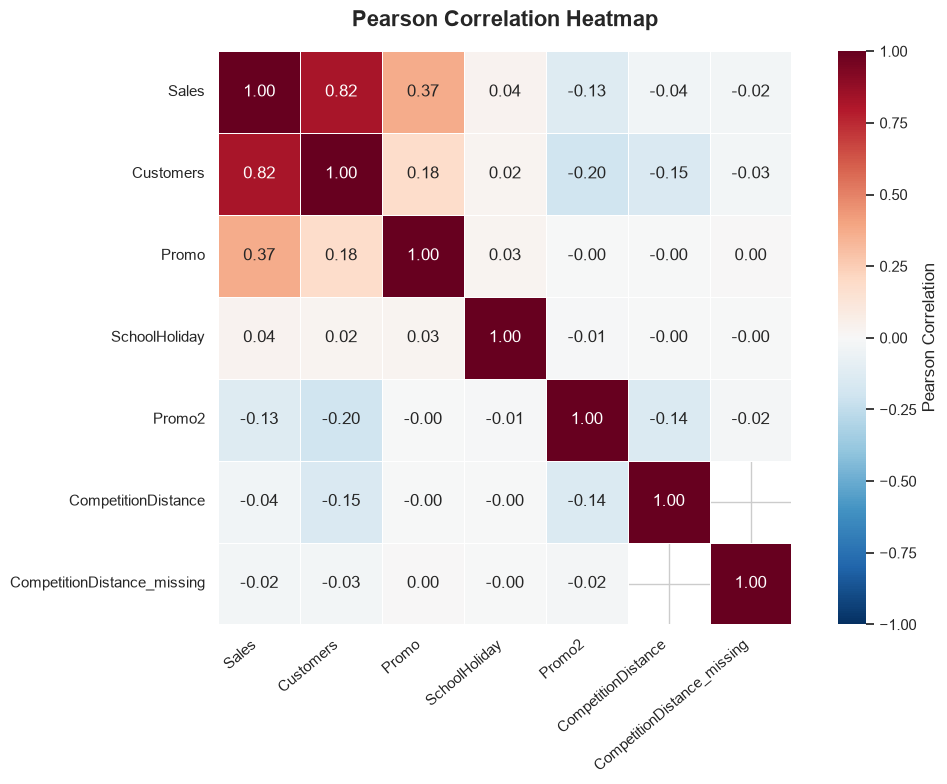

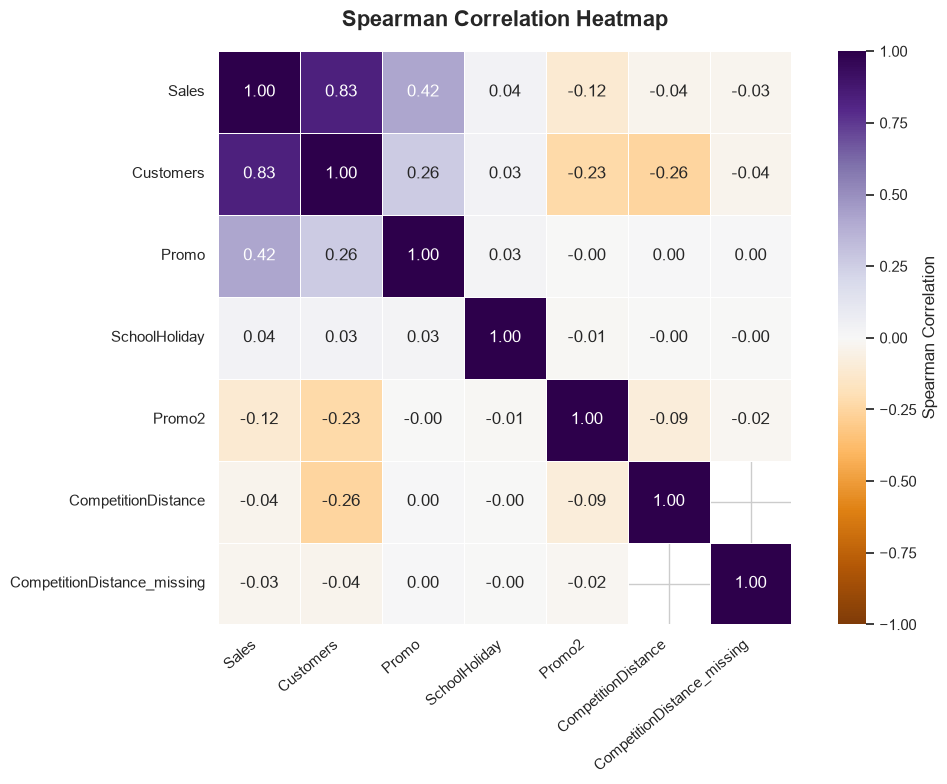


VARIABLES RANKED BY CORRELATION WITH SALES


,Variable,Pearson_Correlation,Spearman_Correlation
0,Customers,+0.8236,+0.8319
1,Promo,+0.3681,+0.4204
2,Promo2,-0.1276,-0.1166
3,SchoolHoliday,+0.0386,+0.0382
4,CompetitionDistance,-0.0364,-0.0352
5,CompetitionDistance_missing,-0.0242,-0.0296


2026-10-31 09:23:26,166 | INFO | Project6_EDA | Correlation analysis completed. Open-store records: 844392; Variables: 7



Correlation analysis completed successfully.
Note: Correlation indicates statistical association, not causation.


In [228]:
# ============================================================
# CORRELATION ANALYSIS OF IMPORTANT VARIABLES
# ============================================================
# Objectives:
# 1. Select meaningful numerical and binary variables.
# 2. Analyze only open-store observations.
# 3. Exclude identifiers and categorical date codes.
# 4. Calculate Pearson and Spearman correlations.
# 5. Visualize correlation matrices using heatmaps.
# 6. Rank variables according to their relationship with Sales.
# ============================================================


# STEP 1: Select meaningful variables for correlation analysis.

candidate_columns = [
    "Sales",
    "Customers",
    "Promo",
    "SchoolHoliday",
    "Promo2",
    "CompetitionDistance",
    "CompetitionDistance_missing"
]

# Select only columns available in the training dataset.
available_columns = [
    column
    for column in candidate_columns
    if column in train_df.columns
]

# Sales and Customers are essential for this analysis.
essential_columns = ["Sales", "Customers"]

missing_essential = [
    column
    for column in essential_columns
    if column not in available_columns
]

if missing_essential:
    raise ValueError(
        f"Required columns are missing: {missing_essential}"
    )


# STEP 2: Create a separate analysis DataFrame.

correlation_df = train_df[available_columns].copy()

# Convert selected columns into numeric format.
for column in available_columns:
    correlation_df[column] = pd.to_numeric(
        correlation_df[column],
        errors="coerce"
    )


# STEP 3: Keep only open-store observations.

if "Open" not in train_df.columns:
    raise ValueError("Open column is missing from training data.")

open_store_mask = pd.to_numeric(
    train_df["Open"],
    errors="coerce"
).eq(1)

correlation_df = correlation_df.loc[
    open_store_mask
].copy()

# Remove records without a valid Sales value.
correlation_df = correlation_df.dropna(
    subset=["Sales"]
)


# STEP 4: Remove columns that have no variation.

valid_columns = [
    column
    for column in correlation_df.columns
    if correlation_df[column].notna().any()
    and correlation_df[column].nunique(
        dropna=True
    ) > 1
]

correlation_df = correlation_df[valid_columns]


# STEP 5: Display the analysis overview.

print("=" * 75)
print("CORRELATION ANALYSIS — DATA OVERVIEW")
print("=" * 75)

print(f"Total training records : {len(train_df):,}")
print(f"Open-store records     : {len(correlation_df):,}")
print(f"Variables included     : {len(valid_columns)}")

print("\nSelected variables:")
for column in valid_columns:
    print("-", column)

print("\nMissing values in selected variables:")
display(
    correlation_df.isna().sum().to_frame(
        name="Missing_Count"
    )
)


# STEP 6: Calculate Pearson correlation.

pearson_matrix = correlation_df.corr(
    method="pearson",
    min_periods=2
)

print("\n" + "=" * 75)
print("PEARSON CORRELATION MATRIX")
print("=" * 75)

display(
    pearson_matrix.style
    .format("{:+.3f}")
    .background_gradient(
        cmap="RdYlBu_r",
        vmin=-1,
        vmax=1
    )
)


# STEP 7: Calculate Spearman correlation.

spearman_matrix = correlation_df.corr(
    method="spearman",
    min_periods=2
)

print("\n" + "=" * 75)
print("SPEARMAN CORRELATION MATRIX")
print("=" * 75)

display(
    spearman_matrix.style
    .format("{:+.3f}")
    .background_gradient(
        cmap="RdYlBu_r",
        vmin=-1,
        vmax=1
    )
)


# STEP 8: Visualize Pearson correlation.

plt.figure(figsize=(11, 8))

sns.heatmap(
    pearson_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    square=True,
    cbar_kws={
        "label": "Pearson Correlation"
    }
)

plt.title(
    "Pearson Correlation Heatmap",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# STEP 9: Visualize Spearman correlation.

plt.figure(figsize=(11, 8))

sns.heatmap(
    spearman_matrix,
    annot=True,
    fmt=".2f",
    cmap="PuOr",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    square=True,
    cbar_kws={
        "label": "Spearman Correlation"
    }
)

plt.title(
    "Spearman Correlation Heatmap",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# STEP 10: Rank variables by Pearson correlation with Sales.

pearson_sales = (
    pearson_matrix["Sales"]
    .drop(labels=["Sales"], errors="ignore")
)

spearman_sales = (
    spearman_matrix["Sales"]
    .drop(labels=["Sales"], errors="ignore")
)

sales_correlation_summary = pd.DataFrame({
    "Pearson_Correlation": pearson_sales,
    "Spearman_Correlation": spearman_sales
})

sales_correlation_summary["Absolute_Pearson"] = (
    sales_correlation_summary[
        "Pearson_Correlation"
    ].abs()
)

sales_correlation_summary = (
    sales_correlation_summary
    .sort_values(
        by="Absolute_Pearson",
        ascending=False
    )
    .drop(columns=["Absolute_Pearson"])
    .reset_index()
    .rename(columns={"index": "Variable"})
)

print("\n" + "=" * 75)
print("VARIABLES RANKED BY CORRELATION WITH SALES")
print("=" * 75)

display(
    sales_correlation_summary.style.format({
        "Pearson_Correlation": "{:+.4f}",
        "Spearman_Correlation": "{:+.4f}"
    }).background_gradient(
        subset=[
            "Pearson_Correlation",
            "Spearman_Correlation"
        ],
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )
)


# STEP 11: Record completion in the project log.

logger.info(
    "Correlation analysis completed. "
    "Open-store records: %d; Variables: %d",
    len(correlation_df),
    len(valid_columns)
)

print("\nCorrelation analysis completed successfully.")

print(
    "Note: Correlation indicates statistical association, "
    "not causation."
)

###  Key Insights — Correlation Analysis

**1. Strong Positive Relationship Between Sales and Customers**

Customers has the strongest positive association with Sales:

- Pearson correlation: **+0.8236**
- Spearman correlation: **+0.8319**

Both measures indicate a strong positive relationship. Store-days with higher customer traffic generally tend to record higher Sales.

**2. Positive Association Between Promotions and Sales**

Promo shows a positive association with Sales:

- Pearson correlation: **+0.3681**
- Spearman correlation: **+0.4204**

The positive relationship supports the earlier descriptive findings that promotional periods are associated with higher average Sales and Customers.

**3. Weak Negative Association of Promo2 with Sales**

Promo2 has a weak negative association with Sales:

- Pearson correlation: **-0.1276**
- Spearman correlation: **-0.1166**

This result should not be interpreted as evidence that Promo2 reduces Sales. Differences in store characteristics, promotion participation, and other factors may influence this relationship.

**4. Very Weak Relationships with School Holidays and Competition Distance**

- SchoolHoliday: Pearson **+0.0386**, Spearman **+0.0382**
- CompetitionDistance: Pearson **-0.0364**, Spearman **-0.0352**

These values indicate very weak individual associations with daily Sales. However, weak correlation does not necessarily mean that these variables have no predictive value when combined with other features.

**5. Competition Distance Missing-Value Indicator**

The `CompetitionDistance_missing` indicator has a weak negative association with Sales:

- Pearson correlation: **-0.0242**
- Spearman correlation: **-0.0296**

This indicator represents whether competition-distance information is missing. It should be interpreted as a data-availability indicator, not as a direct measure of competition.

**6. Pearson and Spearman Comparison**

Pearson and Spearman correlations show similar patterns for the major variables. Spearman correlation is slightly stronger for Customers and Promo, suggesting that their positive relationships with Sales are also visible when observations are compared by rank.

**7. Business Interpretation**

Customer traffic and promotional activity show the strongest individual associations with Sales among the variables examined. Competition distance and holiday indicators show weak individual correlations, but may still contribute useful information in combination with other forecasting features.

**8. Limitations**

- Correlation measures association and does not establish causation.
- Only open-store observations were included in this analysis.
- Customers is available in historical training data but is not provided in the test dataset; therefore, actual future Customers must not be used as a direct forecasting input.
- Store-level metadata is repeated across daily records and should be interpreted carefully.
- Correlation alone cannot determine the predictive importance of a feature.

**Conclusion:** Customers and Promo have the strongest positive individual associations with Sales in this analysis. These findings provide useful guidance for feature selection, but final feature importance must be evaluated using forecasting models.

### 29. **Promotion × Store Type Analysis**

This section examines whether the relationship between promotions and retail performance differs across store types.

The analysis will compare promotional and non-promotional periods for each store type using:

- Average Sales
- Average Customers
- Number of observations
- Number of unique stores
- Percentage change in average Sales and Customers during promotions

Grouped comparisons and visualizations will help identify which store types show stronger promotional associations.

The findings can help understand whether promotional effectiveness varies according to store characteristics and can support the development of store-aware forecasting strategies.

**Note:** These comparisons are descriptive and do not establish that promotions alone caused changes in Sales or Customers.

PROMOTION × STORE TYPE ANALYSIS
Eligible open-store records: 844,392
Unique stores: 1,115

PROMOTION PERFORMANCE BY STORE TYPE


,StoreType,Promo,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers,Median_Customers
0,a,0,"252,556",602,"5,808.50","5,313.00",713.81,641.00
1,a,1,"204,521",602,"8,304.10","7,646.00",896.07,814.00
2,b,0,"9,623",17,"9,566.86","8,516.00","1,941.80","1,753.00"
3,b,1,"5,940",17,"11,307.99","10,202.50","2,151.45","2,011.00"
4,c,0,"62,240",148,"6,028.06","5,523.00",758.71,698.00
5,c,1,"50,738",148,"8,042.00","7,572.00",885.09,833.00
6,d,0,"143,077",348,"5,855.27","5,551.00",556.29,531.00
7,d,1,"115,697",348,"8,017.83","7,626.00",668.23,641.00



PROMOTIONAL UPLIFT BY STORE TYPE


,StoreType,Sales_Without_Promo,Sales_With_Promo,Sales_Uplift_Percent,Customers_Without_Promo,Customers_With_Promo,Customers_Uplift_Percent
0,a,"5,808.50","8,304.10",+42.96%,713.81,896.07,+25.53%
1,b,"9,566.86","11,307.99",+18.20%,"1,941.80","2,151.45",+10.80%
2,c,"6,028.06","8,042.00",+33.41%,758.71,885.09,+16.66%
3,d,"5,855.27","8,017.83",+36.93%,556.29,668.23,+20.12%


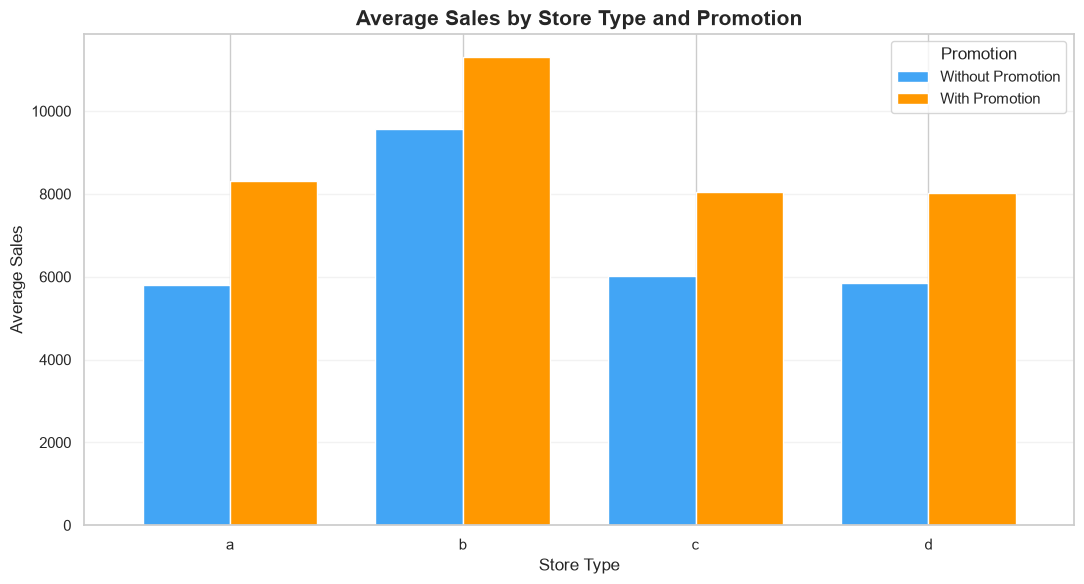

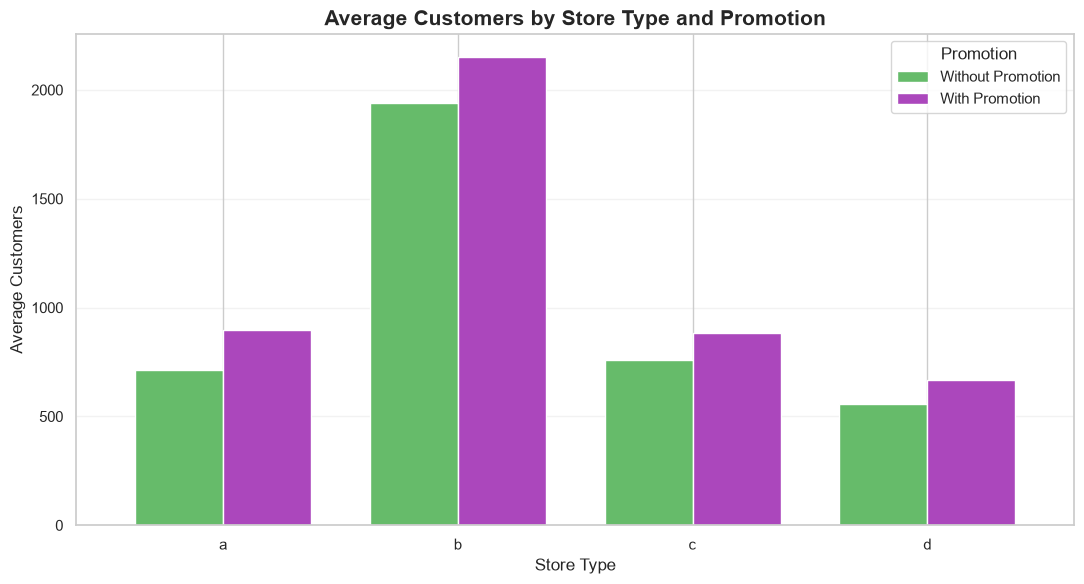

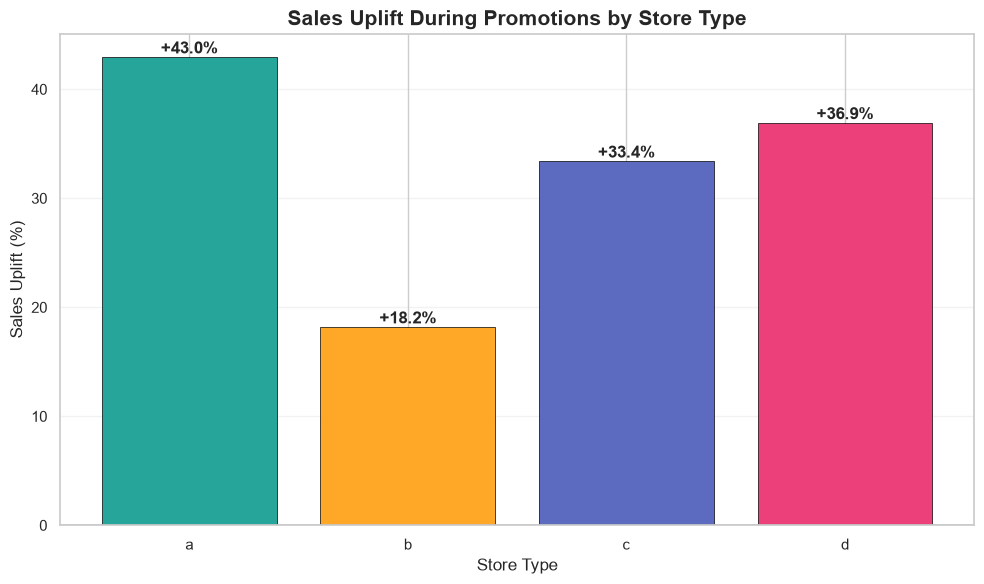

2026-10-31 09:23:26,940 | INFO | Project6_EDA | Section 29 completed. Records=844392; StoreTypes=4.



Section 29 completed successfully.


In [229]:

# ============================================================
# PROMOTION × STORE TYPE ANALYSIS
# ============================================================

# STEP 1: Check required columns
required_columns = [
    "Store",
    "StoreType",
    "Promo",
    "Sales",
    "Customers",
    "Open"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Select required data
promo_store_df = train_df[required_columns].copy()

# Convert numeric columns safely
numeric_columns = [
    "Promo", "Sales", "Customers", "Open"
]

for col in numeric_columns:
    promo_store_df[col] = pd.to_numeric(
        promo_store_df[col],
        errors="coerce"
    )

# STEP 3: Keep valid open-store records
promo_store_df = promo_store_df[
    (promo_store_df["Open"] == 1) &
    (promo_store_df["Promo"].isin([0, 1])) &
    (promo_store_df["StoreType"].notna()) &
    (promo_store_df["Sales"].notna()) &
    (promo_store_df["Customers"].notna())
].copy()

print("=" * 75)
print("PROMOTION × STORE TYPE ANALYSIS")
print("=" * 75)

print(
    f"Eligible open-store records: "
    f"{len(promo_store_df):,}"
)

print(
    f"Unique stores: "
    f"{promo_store_df['Store'].nunique():,}"
)

# STEP 4: Calculate performance by StoreType and Promo
store_type_promo_summary = (
    promo_store_df
    .groupby(["StoreType", "Promo"], observed=True)
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean"),
        Median_Customers=("Customers", "median")
    )
    .reset_index()
)

print("\nPROMOTION PERFORMANCE BY STORE TYPE")

display(
    store_type_promo_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}",
        "Median_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

# STEP 5: Calculate promotional uplift for each StoreType
sales_pivot = store_type_promo_summary.pivot(
    index="StoreType",
    columns="Promo",
    values="Mean_Sales"
)

customers_pivot = store_type_promo_summary.pivot(
    index="StoreType",
    columns="Promo",
    values="Mean_Customers"
)

# Keep only StoreTypes having both Promo 0 and Promo 1
valid_store_types = (
    sales_pivot.dropna(subset=[0, 1]).index
    .intersection(
        customers_pivot.dropna(subset=[0, 1]).index
    )
)

sales_pivot = sales_pivot.loc[valid_store_types]
customers_pivot = customers_pivot.loc[valid_store_types]

uplift_summary = pd.DataFrame(index=valid_store_types)

uplift_summary["Sales_Without_Promo"] = sales_pivot[0]
uplift_summary["Sales_With_Promo"] = sales_pivot[1]

uplift_summary["Sales_Uplift_Percent"] = (
    (sales_pivot[1] - sales_pivot[0]) /
    sales_pivot[0].replace(0, np.nan)
) * 100

uplift_summary["Customers_Without_Promo"] = (
    customers_pivot[0]
)

uplift_summary["Customers_With_Promo"] = (
    customers_pivot[1]
)

uplift_summary["Customers_Uplift_Percent"] = (
    (customers_pivot[1] - customers_pivot[0]) /
    customers_pivot[0].replace(0, np.nan)
) * 100

uplift_summary = uplift_summary.reset_index(
    names="StoreType"
)

print("\nPROMOTIONAL UPLIFT BY STORE TYPE")

display(
    uplift_summary.style.format({
        "Sales_Without_Promo": "{:,.2f}",
        "Sales_With_Promo": "{:,.2f}",
        "Sales_Uplift_Percent": "{:+.2f}%",
        "Customers_Without_Promo": "{:,.2f}",
        "Customers_With_Promo": "{:,.2f}",
        "Customers_Uplift_Percent": "{:+.2f}%"
    }).background_gradient(
        subset=[
            "Sales_Uplift_Percent",
            "Customers_Uplift_Percent"
        ],
        cmap="RdYlGn"
    )
)

# STEP 6: Graph 1 — Average Sales by Store Type
sales_plot = store_type_promo_summary.pivot(
    index="StoreType",
    columns="Promo",
    values="Mean_Sales"
)

sales_plot = sales_plot.rename(columns={
    0: "Without Promotion",
    1: "With Promotion"
})

ax = sales_plot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#42A5F5", "#FF9800"],
    width=0.75
)

plt.title(
    "Average Sales by Store Type and Promotion",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.legend(title="Promotion")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# STEP 7: Graph 2 — Average Customers by Store Type
customers_plot = store_type_promo_summary.pivot(
    index="StoreType",
    columns="Promo",
    values="Mean_Customers"
)

customers_plot = customers_plot.rename(columns={
    0: "Without Promotion",
    1: "With Promotion"
})

ax = customers_plot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#66BB6A", "#AB47BC"],
    width=0.75
)

plt.title(
    "Average Customers by Store Type and Promotion",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Store Type")
plt.ylabel("Average Customers")
plt.xticks(rotation=0)
plt.legend(title="Promotion")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# STEP 8: Graph 3 — Sales Uplift by Store Type
plt.figure(figsize=(10, 6))

bars = plt.bar(
    uplift_summary["StoreType"].astype(str),
    uplift_summary["Sales_Uplift_Percent"],
    color=["#26A69A", "#FFA726", "#5C6BC0", "#EC407A"][
        :len(uplift_summary)
    ],
    edgecolor="black",
    linewidth=0.5
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:+.1f}%",
        ha="center",
        va="bottom" if height >= 0 else "top",
        fontweight="bold"
    )

plt.title(
    "Sales Uplift During Promotions by Store Type",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Store Type")
plt.ylabel("Sales Uplift (%)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# STEP 9: Log completion
if "logger" in globals():
    logger.info(
        "Section 29 completed. Records=%d; StoreTypes=%d.",
        len(promo_store_df),
        len(valid_store_types)
    )

print("\nSection 29 completed successfully.")


###  Key Insights — Promotion × Store Type Analysis

**1. Promotional Sales Uplift Varies Across Store Types**

The percentage increase in average Sales during promotional periods differs across store types:

- Store Type A: **+42.96%**
- Store Type B: **+18.20%**
- Store Type C: **+33.41%**
- Store Type D: **+36.93%**

Store Type A records the highest promotional Sales uplift, while Store Type B records the lowest.

**2. Customer Traffic Also Increases During Promotions**

Average Customers increase across all four store types:

- Store Type A: **+25.53%**
- Store Type B: **+10.80%**
- Store Type C: **+16.66%**
- Store Type D: **+20.12%**

This indicates that promotional periods are associated with higher customer traffic across every store type.

**3. Store Type B Has the Highest Average Sales**

Store Type B has the highest average Sales both without promotions (9,566.86) and with promotions (11,307.99).

However, its percentage Sales uplift is the lowest at 18.20%. A high baseline sales level does not necessarily mean a high percentage response to promotions.

**4. Store Type A Shows the Strongest Promotional Uplift**

Store Type A has the highest Sales uplift (+42.96%) and Customer uplift (+25.53%). This suggests a comparatively stronger association between promotional periods and retail activity in this store type.

**5. Business Interpretation**

Promotional performance differs across store types. A forecasting strategy may benefit from considering StoreType and Promo together rather than treating promotional activity as having an identical relationship with Sales in every store.

**6. Limitations**

- These are descriptive comparisons, not causal estimates.
- Store types have different numbers of stores and observations.
- Differences in baseline sales, store locations, customer behavior, and calendar effects may influence the results.
- Promotion costs and profit margins are not included.

**Conclusion:** Promotional uplift is highest in Store Type A and lowest in Store Type B. Store type should therefore be considered when analyzing promotional activity and developing forecasting features.

### 30. **Combined Effects of Promotions, Holidays, and Customer Traffic**

This section examines the combined relationship between promotional activity, holiday conditions, customer traffic, and retail Sales.

The analysis will:

- Classify dates into regular days, school holidays, state holidays, and days when both holiday indicators apply.
- Compare promotional and non-promotional performance under each holiday condition.
- Divide open-store observations into customer traffic groups using quartiles.
- Examine average Sales and Customers across these combined categories.
- Use grouped summary tables and heatmaps to visualize the results.

The objective is to understand how promotional activity and holiday conditions are associated with Sales under different levels of customer traffic.

**Note:** These results are descriptive associations and do not establish causation.

COMBINED PROMOTION, HOLIDAY AND CUSTOMER TRAFFIC ANALYSIS
Eligible open-store records: 844,392
Unique stores: 1,115

HOLIDAY CONDITION DISTRIBUTION


,Holiday_Condition,Record_Count
0,Regular Day,680339
1,School Holiday Only,163143
2,State Holiday Only,596
3,Both Holidays,314



CUSTOMER TRAFFIC GROUP DISTRIBUTION


,Customer_Traffic_Group,Record_Count
0,Low Traffic,211939
1,Medium Traffic,211208
2,High Traffic,211005
3,Very High Traffic,210240



COMBINED PERFORMANCE SUMMARY


,Holiday_Condition,Promo,Customer_Traffic_Group,Record_Count,Unique_Stores,Mean_Sales,Median_Sales,Mean_Customers
0,Both Holidays,0,Low Traffic,41,14,"2,310.10","1,929.00",303.88
1,Both Holidays,0,Medium Traffic,23,12,"3,730.65","3,815.00",600.17
2,Both Holidays,0,High Traffic,26,14,"4,481.62","4,541.00",763.08
3,Both Holidays,0,Very High Traffic,141,19,"11,469.72","10,060.00","1,986.52"
4,Both Holidays,1,Low Traffic,4,4,"4,996.75","4,713.50",421.25
5,Both Holidays,1,Medium Traffic,12,11,"6,300.83","6,127.00",602.33
6,Both Holidays,1,High Traffic,7,7,"8,423.71","8,407.00",761.43
7,Both Holidays,1,Very High Traffic,60,20,"12,133.58","10,259.00","2,097.52"
8,Regular Day,0,Low Traffic,"132,461",903,"3,917.40","3,896.00",403.74
9,Regular Day,0,Medium Traffic,"98,961",993,"5,458.88","5,346.00",594.10


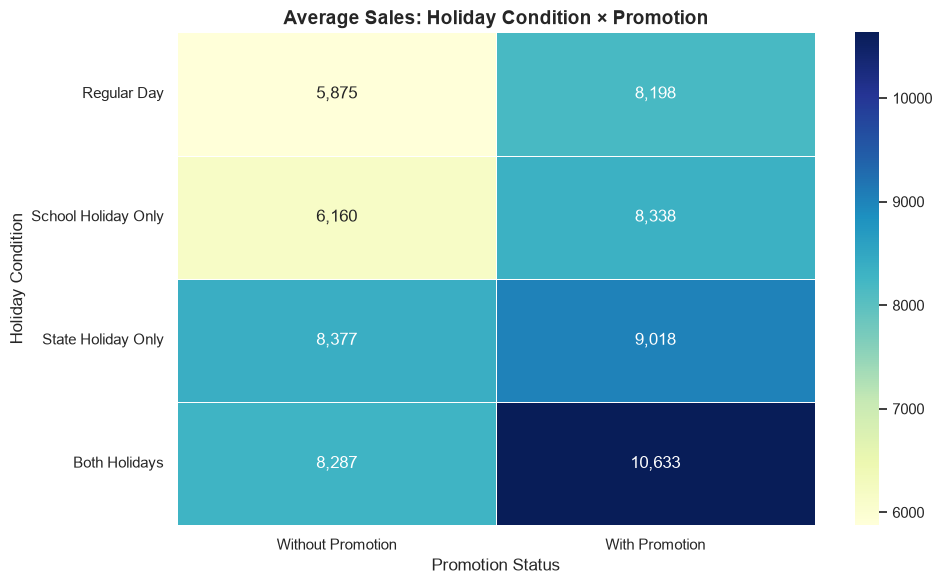

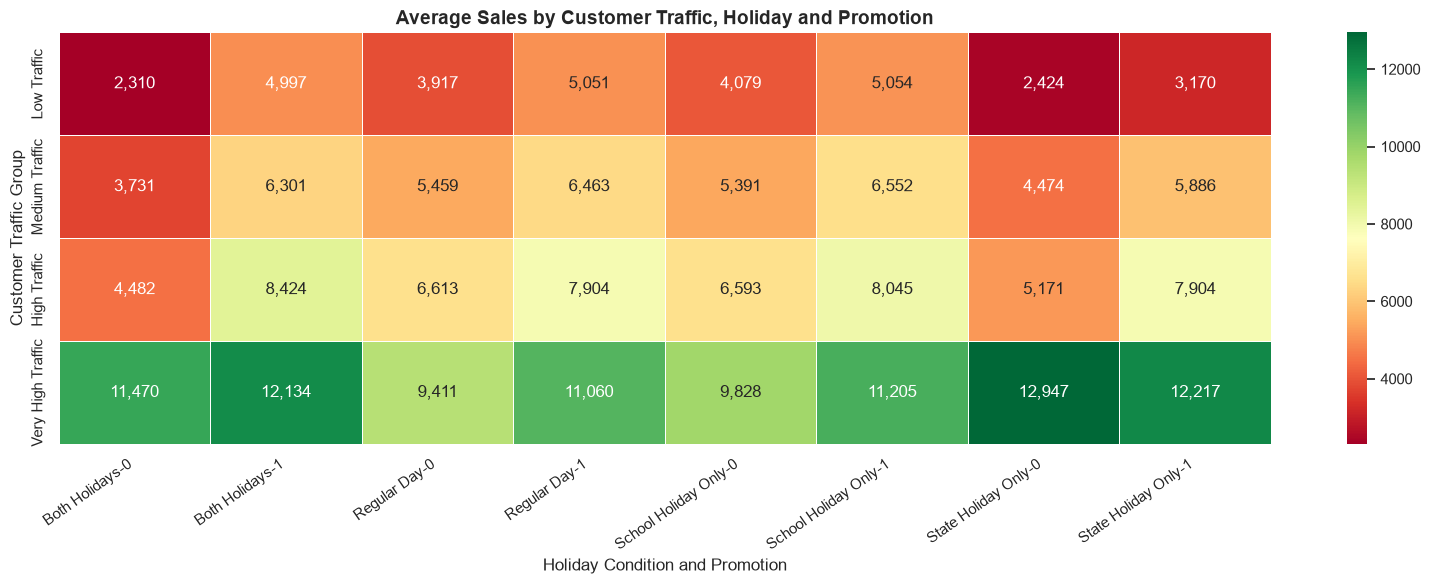

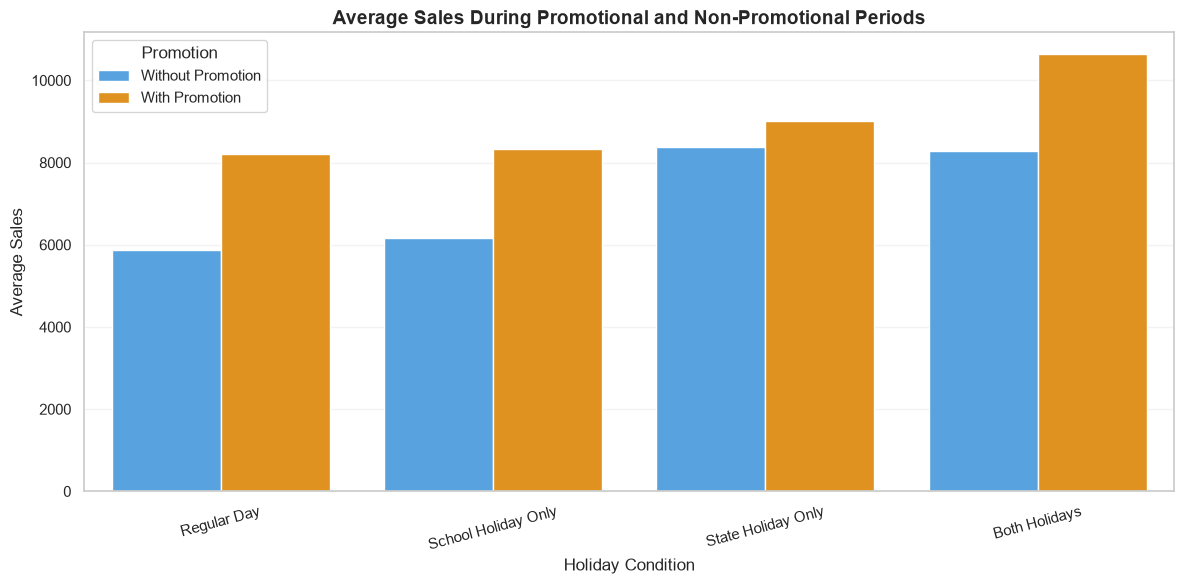

2026-10-31 09:23:29,484 | INFO | Project6_EDA | Section 30 completed. Records=844392; Holiday conditions=4.



Section 30 completed successfully.


In [230]:

# ============================================================
# COMBINED EFFECTS OF PROMOTIONS,
# HOLIDAYS, AND CUSTOMER TRAFFIC
# ============================================================

# STEP 1: Validate required columns
required_columns = [
    "Store",
    "Date",
    "Sales",
    "Customers",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# STEP 2: Prepare analysis dataset
combined_df = train_df[required_columns].copy()

combined_df["Date"] = pd.to_datetime(
    combined_df["Date"],
    errors="coerce"
)

for col in [
    "Sales",
    "Customers",
    "Open",
    "Promo",
    "SchoolHoliday"
]:
    combined_df[col] = pd.to_numeric(
        combined_df[col],
        errors="coerce"
    )

# STEP 3: Keep valid open-store observations
combined_df = combined_df.loc[
    combined_df["Open"].eq(1)
    & combined_df["Date"].notna()
    & combined_df["Sales"].notna()
    & combined_df["Customers"].notna()
    & combined_df["Promo"].isin([0, 1])
    & combined_df["SchoolHoliday"].notna()
].copy()

print("=" * 80)
print("COMBINED PROMOTION, HOLIDAY AND CUSTOMER TRAFFIC ANALYSIS")
print("=" * 80)

print(
    f"Eligible open-store records: {len(combined_df):,}"
)
print(
    f"Unique stores: {combined_df['Store'].nunique():,}"
)

# STEP 4: Identify State Holiday and School Holiday
state_holiday_values = (
    combined_df["StateHoliday"]
    .astype("string")
    .str.strip()
    .str.lower()
)

non_holiday_values = {
    "0", "0.0", "", "nan", "none", "<na>"
}

combined_df["Is_State_Holiday"] = (
    state_holiday_values.notna()
    & ~state_holiday_values.isin(non_holiday_values)
).astype(int)

combined_df["Is_School_Holiday"] = (
    combined_df["SchoolHoliday"].eq(1)
).astype(int)

# STEP 5: Create combined Holiday Condition
conditions = [
    (
        combined_df["Is_State_Holiday"].eq(0)
        & combined_df["Is_School_Holiday"].eq(0)
    ),
    (
        combined_df["Is_State_Holiday"].eq(0)
        & combined_df["Is_School_Holiday"].eq(1)
    ),
    (
        combined_df["Is_State_Holiday"].eq(1)
        & combined_df["Is_School_Holiday"].eq(0)
    ),
    (
        combined_df["Is_State_Holiday"].eq(1)
        & combined_df["Is_School_Holiday"].eq(1)
    )
]

holiday_labels = [
    "Regular Day",
    "School Holiday Only",
    "State Holiday Only",
    "Both Holidays"
]

combined_df["Holiday_Condition"] = np.select(
    conditions,
    holiday_labels,
    default="Unknown"
)

# STEP 6: Create Customer Traffic Groups
# Quartiles divide observations into low-to-high
# customer traffic groups based on Customers.
traffic_bins = pd.qcut(
    combined_df["Customers"],
    q=4,
    duplicates="drop"
)

number_of_traffic_groups = len(
    traffic_bins.cat.categories
)

traffic_labels = [
    "Low Traffic",
    "Medium Traffic",
    "High Traffic",
    "Very High Traffic"
][:number_of_traffic_groups]

traffic_codes = traffic_bins.cat.codes

combined_df["Customer_Traffic_Group"] = (
    pd.Categorical.from_codes(
        traffic_codes,
        categories=traffic_labels,
        ordered=True
    )
)

print("\nHOLIDAY CONDITION DISTRIBUTION")

display(
    combined_df["Holiday_Condition"]
    .value_counts()
    .rename_axis("Holiday_Condition")
    .reset_index(name="Record_Count")
)

print("\nCUSTOMER TRAFFIC GROUP DISTRIBUTION")

display(
    combined_df["Customer_Traffic_Group"]
    .value_counts(sort=False)
    .rename_axis("Customer_Traffic_Group")
    .reset_index(name="Record_Count")
)

# STEP 7: Analyze all three factors together
combined_summary = (
    combined_df
    .groupby(
        [
            "Holiday_Condition",
            "Promo",
            "Customer_Traffic_Group"
        ],
        observed=True
    )
    .agg(
        Record_Count=("Sales", "size"),
        Unique_Stores=("Store", "nunique"),
        Mean_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Mean_Customers=("Customers", "mean")
    )
    .reset_index()
)

print("\nCOMBINED PERFORMANCE SUMMARY")

display(
    combined_summary.style.format({
        "Record_Count": "{:,.0f}",
        "Unique_Stores": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}",
        "Mean_Customers": "{:,.2f}"
    }).background_gradient(
        subset=["Mean_Sales", "Mean_Customers"],
        cmap="YlGnBu"
    )
)

# STEP 8: Heatmap — Holiday Condition × Promotion
holiday_promo_sales = (
    combined_df
    .pivot_table(
        index="Holiday_Condition",
        columns="Promo",
        values="Sales",
        aggfunc="mean",
        observed=True
    )
    .reindex(holiday_labels)
)

holiday_promo_sales = holiday_promo_sales.rename(
    columns={
        0: "Without Promotion",
        1: "With Promotion"
    }
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    holiday_promo_sales,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Average Sales: Holiday Condition × Promotion",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Promotion Status")
plt.ylabel("Holiday Condition")
plt.tight_layout()
plt.show()

# STEP 9: Heatmap — Customer Traffic × Holiday × Promotion
traffic_holiday_promo = (
    combined_summary
    .pivot_table(
        index="Customer_Traffic_Group",
        columns=["Holiday_Condition", "Promo"],
        values="Mean_Sales",
        observed=True
    )
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    traffic_holiday_promo,
    annot=True,
    fmt=",.0f",
    cmap="RdYlGn",
    linewidths=0.4
)

plt.title(
    "Average Sales by Customer Traffic, Holiday and Promotion",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Holiday Condition and Promotion")
plt.ylabel("Customer Traffic Group")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# STEP 10: Promotion comparison across holiday conditions
plt.figure(figsize=(12, 6))

sns.barplot(
    data=combined_df,
    x="Holiday_Condition",
    y="Sales",
    hue="Promo",
    order=holiday_labels,
    estimator="mean",
    errorbar=None,
    palette=["#42A5F5", "#FF9800"]
)

plt.title(
    "Average Sales During Promotional and Non-Promotional Periods",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Holiday Condition")
plt.ylabel("Average Sales")
plt.xticks(rotation=15)
plt.legend(
    title="Promotion",
    labels=["Without Promotion", "With Promotion"]
)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# STEP 11: Log completion
if "logger" in globals():
    logger.info(
        "Section 30 completed. Records=%d; Holiday conditions=%d.",
        len(combined_df),
        combined_df["Holiday_Condition"].nunique()
    )

print("\nSection 30 completed successfully.")


###  Key Insights — Combined Effects of Promotions, Holidays, and Customer Traffic

**1. Distribution of Holiday Conditions**

The analysis of 844,392 valid open-store observations identified four holiday conditions:

- Regular Day: **680,339 records**
- School Holiday Only: **163,143 records**
- State Holiday Only: **596 records**
- Both Holidays: **314 records**

Regular days account for the largest share of observations, while state-holiday categories have substantially smaller sample sizes.

**2. Customer Traffic Group Distribution**

Customer counts were divided into four quartile-based groups:

- Low Traffic: **211,939 records**
- Medium Traffic: **211,208 records**
- High Traffic: **211,005 records**
- Very High Traffic: **210,240 records**

The groups contain approximately equal numbers of observations, allowing comparison across different historical customer-traffic levels.

**3. Combined Promotion and Holiday Analysis**

Average Sales were compared across promotional and non-promotional observations under each holiday condition.

The heatmap and grouped summary provide a visual comparison of how Sales vary across:

- Regular days
- School holidays only
- State holidays only
- Days when both holiday indicators apply

The small number of observations in the state-holiday categories means their average values should be interpreted cautiously.

**4. Customer Traffic and Sales**

The second heatmap compares average Sales across customer-traffic groups, holiday conditions, and promotion status.

This helps identify differences in historical Sales across combinations of these factors.

However, customer-traffic groups are created using actual Customers values. They are useful for historical exploratory analysis but cannot be directly used as future inputs when actual customer counts are unavailable.

**5. Business Interpretation**

Promotions, holiday conditions, and customer traffic provide useful context for understanding historical retail Sales patterns.

Considering these factors together may help identify useful forecasting features and possible differences in store performance across business conditions.

**6. Limitations**

- The analysis is descriptive and does not establish causation.
- State Holiday Only and Both Holidays have relatively small sample sizes.
- Customer traffic groups are based on historical Customers values.
- Store-level differences and calendar effects may influence the observed patterns.
- Promotional costs and profit margins are not included.

**Conclusion:** The combined analysis provides a structured view of historical Sales across promotional activity, holiday conditions, and customer-traffic groups. These findings can guide feature engineering, while future forecasting must rely only on information available at prediction time.

### 31. **Summary of Key EDA Findings**

This section consolidates the major findings from the Exploratory Data Analysis of the Rossmann Store Sales dataset.

The summary covers the following areas:

1. Dataset structure, date range, and data quality.
2. Missing values and numerical outlier patterns.
3. Promotion distribution across training and test datasets.
4. Promotional impact on Sales and Customers.
5. Holiday-related and seasonal sales behavior.
6. Relationship between Sales and Customers.
7. Weekday and weekend sales patterns.
8. Store Type and Assortment performance.
9. Competition distance and competitor opening analysis.
10. Store-level promotional effectiveness.
11. Promotion performance across different store types.
12. Combined effects of promotions, holidays, and customer traffic.
13. Correlation patterns and their relevance to forecasting.

### Important Data Limitations

- The dataset does not contain exact daily store opening and closing times. Therefore, customer behavior by time of day cannot be analyzed.
- The dataset does not provide a direct city-center indicator or store coordinates. Therefore, the effect of competition distance specifically within city centers cannot be isolated.
- Actual Customers values are available in the historical training data but are not available in the test dataset. They must not be used as direct inputs for future Sales predictions.
- Observed relationships and percentage changes are descriptive and should not be interpreted as proof of causation.

The objective is to consolidate the EDA findings, identify useful business patterns, document data limitations, and prepare a reliable foundation for the subsequent Sales Forecasting stage.

In [231]:

# ============================================================
# SECTION 31: SUMMARY OF KEY EDA FINDINGS
# ============================================================

# STEP 1: Import required libraries
import pandas as pd
from IPython.display import display

# STEP 2: Prepare consolidated EDA findings
# Numerical values are based on the reviewed EDA outputs.

eda_findings = [

    {
        "Analysis Area": "Dataset Structure",
        "Key Finding": "Training: 1,017,209 records; Test: 41,088 records",
        "Interpretation": "The project contains a large-scale retail dataset."
    },

    {
        "Analysis Area": "Temporal Coverage",
        "Key Finding": "Training: Jan 2013 to Jul 2015; Test: Aug 2015 to Sep 2015",
        "Interpretation": "The test period follows the training period."
    },

    {
        "Analysis Area": "Data Quality",
        "Key Finding": "No exact duplicate rows or duplicate Store-Date pairs",
        "Interpretation": "No duplicate records were identified in the data audit."
    },

    {
        "Analysis Area": "Missing Values",
        "Key Finding": "Training completeness: 88.75%; Test completeness: 88.88%",
        "Interpretation": "Missing values require appropriate handling before modeling."
    },

    {
        "Analysis Area": "Outlier Analysis",
        "Key Finding": "Sales, Customers and CompetitionDistance show right-skewed distributions and extreme values",
        "Interpretation": "Potential outliers should be investigated rather than automatically removed."
    },

    {
        "Analysis Area": "Promotion Distribution",
        "Key Finding": "Training promotion share: 38.15%; Test promotion share: 39.58%",
        "Interpretation": "Promotion frequency is broadly similar in both datasets."
    },

    {
        "Analysis Area": "Promotion Impact",
        "Key Finding": "Mean Sales uplift: +38.77%; Mean Customers uplift: +21.18%",
        "Interpretation": "Promotional periods are associated with higher average Sales and Customers."
    },

    {
        "Analysis Area": "Holiday Analysis",
        "Key Finding": "Mean Sales: During holidays 7,728.29; Other days 6,752.60",
        "Interpretation": "Higher average Sales were observed during the identified holiday periods."
    },

    {
        "Analysis Area": "Seasonal Analysis",
        "Key Finding": "Christmas Sales: +15.54%; Easter Sales: +10.87% versus other days",
        "Interpretation": "The analyzed Christmas and Easter periods show higher average Sales."
    },

    {
        "Analysis Area": "Sales and Customers",
        "Key Finding": "Pearson: +0.8236; Spearman: +0.8319",
        "Interpretation": "Sales and customer traffic have a strong positive association."
    },

    {
        "Analysis Area": "Weekday and Weekend",
        "Key Finding": "Weekend mean Sales are 17.29% lower than weekday mean Sales",
        "Interpretation": "Retail Sales behavior varies across weekdays and weekends."
    },

    {
        "Analysis Area": "All-Weekday-Open Stores",
        "Key Finding": "10 stores were open on all observed weekdays. Their weekend mean Sales were 11,627.11 compared with 5,826.74 for other stores.",
        "Interpretation": "All-weekday-open stores showed approximately 99.55% higher weekend mean Sales. However, this group contains only 10 stores, so the result should be interpreted cautiously."
    },

    {
        "Analysis Area": "Store Type",
        "Key Finding": "Store Type B has the highest reported mean Sales: 10,231.41",
        "Interpretation": "Average Sales differ across store types; Type B has only 17 stores."
    },

    {
        "Analysis Area": "Missing-to-Available Competition Distance",
        "Key Finding": "Out of 1,115 stores, 3 had completely missing CompetitionDistance information and no store showed a missing-to-available transition.",
        "Interpretation": "Missing competition-distance information remained consistent across the observed training records for these stores."
    },

    {
        "Analysis Area": "Competition Distance — Store Level",
        "Key Finding": "Pearson: -0.0424; Spearman: -0.0280, based on 1,112 stores.",
        "Interpretation": "Store-level average Sales have a very weak negative association with CompetitionDistance."
    },

    {
        "Analysis Area": "Competition Distance — Daily Level",
        "Key Finding": "Pearson: -0.0364; Spearman: -0.0352, based on 844,392 open-store observations.",
        "Interpretation": "Daily open-store observations also show a very weak negative association with CompetitionDistance."
    },

    {
        "Analysis Area": "Competitor Opening",
        "Key Finding": "188 paired stores; observed mean Sales change: -4.41%",
        "Interpretation": "Lower average Sales were observed after competitor opening in this paired comparison; this does not establish causation."
    },

    {
        "Analysis Area": "Store-Level Promotion",
        "Key Finding": "Mean store-level Sales uplift: +41.43%; 1,114 of 1,115 stores showed positive uplift",
        "Interpretation": "Observed promotional Sales uplift was positive for nearly all analyzed stores."
    },

    {
        "Analysis Area": "Promotion × Store Type",
        "Key Finding": "Sales uplift: Type A +42.96%; B +18.20%; C +33.41%; D +36.93%",
        "Interpretation": "Promotional associations vary across store types."
    },

    {
        "Analysis Area": "Customer Traffic Groups",
        "Key Finding": "Four quartile-based groups: Low, Medium, High and Very High Traffic",
        "Interpretation": "Historical Sales were compared across different customer-traffic levels."
    },

    {
        "Analysis Area": "Combined Holiday Analysis",
        "Key Finding": "Four holiday conditions analyzed across 844,392 open-store observations",
        "Interpretation": "Sales patterns were examined across promotion and holiday combinations."
    },

    {
        "Analysis Area": "Forecasting Relevance",
        "Key Finding": "Customers has a strong historical association with Sales but is unavailable in the test dataset",
        "Interpretation": "Actual future Customers must not be used as a direct forecasting input."
    },

    {
        "Analysis Area": "Data Limitations",
        "Key Finding": "Exact store opening times, closing times, city-center indicators and coordinates are unavailable",
        "Interpretation": "Time-of-day and city-center-specific competition analysis cannot be directly performed using the available data."
    },

    {
        "Analysis Area": "Assortment",
        "Key Finding": "Assortment C: mean Sales 7,300.53 across 513 stores; Assortment A: 6,621.02 across 593 stores; Assortment B: 8,639.35 across 9 stores.",
        "Interpretation": "Assortment B recorded the highest observed mean Sales, but its small coverage of only 9 stores limits generalization. Assortment C had the highest mean Sales among the broadly represented groups."
    },
]


# STEP 3: Convert findings into a DataFrame
eda_summary_df = pd.DataFrame(eda_findings)


# STEP 4: Display summary heading
print("=" * 100)
print("PROJECT 6: ROSSMANN STORE SALES FORECASTING")
print("SECTION 31: SUMMARY OF KEY EDA FINDINGS")
print("=" * 100)

print(
    f"\nTotal analysis areas summarized: "
    f"{len(eda_summary_df)}"
)


# STEP 5: Apply professional table formatting
summary_styled = (
    eda_summary_df.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#263238"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border", "1px solid #dddddd"),
                ("font-size", "12px")
            ]
        }
    ])
)

# Display the complete summary table
display(summary_styled)


# STEP 6: Display major EDA observations
print("\n" + "=" * 100)
print("MAJOR EDA OBSERVATIONS")
print("=" * 100)

major_observations = [

    "Customer traffic has a strong positive association with Sales.",

    "Promotional periods are associated with higher average Sales and Customers.",

    "Holiday and seasonal periods show variations in retail performance.",

    "Sales behavior differs across store types and days of the week.",

    "Only 10 stores were open on all observed weekdays; their weekend Sales were higher, but the group is small.",

    "Three stores had completely missing CompetitionDistance values, with no missing-to-available transition observed.",

    "Competition distance has a very weak negative association with Sales at both store and daily levels.",

    "Competitor opening analysis showed a -4.41% mean Sales change among 188 paired stores; this is descriptive, not causal.",

    "Promotional uplift varies across individual stores and store types.",

    "Historical customer counts cannot be directly used as future prediction inputs.",

    "Feature engineering and forecasting models are required to evaluate predictive performance."
]

for number, observation in enumerate(
    major_observations,
    start=1
):
    print(f"{number}. {observation}")


# STEP 7: Log completion
if "logger" in globals():

    logger.info(
        "Section 31 summary completed successfully. "
        "Analysis areas summarized: %d",
        len(eda_summary_df)
    )

print("\nSection 31 Summary completed successfully.")


PROJECT 6: ROSSMANN STORE SALES FORECASTING
SECTION 31: SUMMARY OF KEY EDA FINDINGS

Total analysis areas summarized: 24


,Analysis Area,Key Finding,Interpretation
0,Dataset Structure,"Training: 1,017,209 records; Test: 41,088 records",The project contains a large-scale retail dataset.
1,Temporal Coverage,Training: Jan 2013 to Jul 2015; Test: Aug 2015 to Sep 2015,The test period follows the training period.
2,Data Quality,No exact duplicate rows or duplicate Store-Date pairs,No duplicate records were identified in the data audit.
3,Missing Values,Training completeness: 88.75%; Test completeness: 88.88%,Missing values require appropriate handling before modeling.
4,Outlier Analysis,"Sales, Customers and CompetitionDistance show right-skewed distributions and extreme values",Potential outliers should be investigated rather than automatically removed.
5,Promotion Distribution,Training promotion share: 38.15%; Test promotion share: 39.58%,Promotion frequency is broadly similar in both datasets.
6,Promotion Impact,Mean Sales uplift: +38.77%; Mean Customers uplift: +21.18%,Promotional periods are associated with higher average Sales and Customers.
7,Holiday Analysis,"Mean Sales: During holidays 7,728.29; Other days 6,752.60",Higher average Sales were observed during the identified holiday periods.
8,Seasonal Analysis,Christmas Sales: +15.54%; Easter Sales: +10.87% versus other days,The analyzed Christmas and Easter periods show higher average Sales.
9,Sales and Customers,Pearson: +0.8236; Spearman: +0.8319,Sales and customer traffic have a strong positive association.


2026-10-31 09:23:29,518 | INFO | Project6_EDA | Section 31 summary completed successfully. Analysis areas summarized: 24



MAJOR EDA OBSERVATIONS
1. Customer traffic has a strong positive association with Sales.
2. Promotional periods are associated with higher average Sales and Customers.
3. Holiday and seasonal periods show variations in retail performance.
4. Sales behavior differs across store types and days of the week.
5. Only 10 stores were open on all observed weekdays; their weekend Sales were higher, but the group is small.
6. Three stores had completely missing CompetitionDistance values, with no missing-to-available transition observed.
7. Competition distance has a very weak negative association with Sales at both store and daily levels.
8. Competitor opening analysis showed a -4.41% mean Sales change among 188 paired stores; this is descriptive, not causal.
9. Promotional uplift varies across individual stores and store types.
10. Historical customer counts cannot be directly used as future prediction inputs.
11. Feature engineering and forecasting models are required to evaluate predictive 